# Diagnóstico de cobertura de la base RAMA para el estudio de contingencias atmosféricas (2015–2025)

## 1. Objetivo

Este notebook tiene como propósito realizar un diagnóstico de la disponibilidad,
calidad y continuidad temporal de los datos horarios de la **Red Automática de
Monitoreo Atmosférico (RAMA)** durante el periodo 2015–2025.

El diagnóstico se realizará con un objetivo específico: determinar qué estaciones
y series temporales presentan información suficiente para estudiar posteriormente
la **detección temprana de condiciones asociadas con contingencias ambientales
atmosféricas en la Zona Metropolitana del Valle de México**.

A diferencia de un análisis general de calidad del aire, en este proyecto se
considerarán como **contaminantes objetivo**:

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Esta selección responde a que las contingencias ambientales atmosféricas en la
ZMVM se encuentran asociadas con concentraciones elevadas de ozono y partículas
PM10 y PM2.5.

Por tanto, el diagnóstico de cobertura se realizará **por separado para cada
contaminante objetivo**.

Se definirán tres conjuntos de estaciones candidatas: $S_{O_3}$, $S_{PM_{10}}$ y $S_{PM_{2.5}}$, sin exigir que una misma estación tenga simultáneamente buena cobertura para los tres contaminantes.


### Contaminantes auxiliares

Los archivos RAMA contienen además información de otros contaminantes, entre ellos

$$
NO_2,\qquad NO_x,\qquad NO,\qquad CO,\qquad SO_2.
$$

Estos contaminantes **no serán utilizados inicialmente para seleccionar las estaciones objetivo**.

Sin embargo, se conservarán en la base original porque posteriormente podrán evaluarse como **variables predictoras o covariables químicas** para anticipar episodios de contaminación.

En particular, el problema futuro podrá plantearse de manera general como

$$
\mathbf{X}_t
\longrightarrow
Z_{t+h}^{(c)},
$$

donde

$$
c\in\{O_3,PM_{10},PM_{2.5}\},
$$

$\mathbf{X}_t$ representa la información disponible hasta el tiempo $t$ y
$Z_{t+h}^{(c)}$ representa la ocurrencia futura de una condición de interés
asociada con el contaminante $c$.

La definición exacta de $Z_{t+h}^{(c)}$, de los umbrales de contingencia y de los
horizontes de anticipación **no se realizará todavía en este notebook**.


## Objetivos específicos

Durante este notebook se buscará:

1. verificar la existencia y organización de los archivos RAMA correspondientes al periodo 2015–2025;

2. comprobar la estructura temporal de los registros horarios;

3. identificar valores faltantes, duplicados y posibles huecos temporales;

4. cuantificar la cobertura horaria de cada combinación

$$
(\text{año},\text{contaminante},\text{estación});
$$

5. estudiar la continuidad longitudinal de las estaciones para cada uno de los tres contaminantes objetivo;

6. identificar las estaciones con mejor disponibilidad para

$$
O_3,\qquad PM_{10},\qquad PM_{2.5};
$$

7. analizar posteriormente si la cobertura de las estaciones seleccionadas es
   suficiente para construir las variables temporales necesarias para estudiar
   contingencias;

8. generar tablas reproducibles que sirvan como entrada para los siguientes notebooks del proyecto.


## Alcance de esta etapa

En este notebook **no se realizará todavía**:

- imputación de concentraciones faltantes;
- definición formal de contingencias;
- construcción de etiquetas de eventos;
- cálculo de percentiles de extremos;
- entrenamiento de modelos de aprendizaje automático;
- incorporación de variables meteorológicas;
- selección definitiva de predictores químicos.

El objetivo de esta primera etapa es más fundamental: **determinar qué series horarias de O3, PM10 y PM2.5 poseen calidad, continuidad temporal y cobertura suficientes para construir posteriormente un problema reproducible de detección temprana de contingencias  atmosféricas.**

Las decisiones tomadas durante este notebook deberán basarse primero en la estructura real de los datos y no en criterios elegidos únicamente para maximizar el tamaño de la muestra.

# Conceptos fundamentales para estudiar este notebook

Este notebook tiene como objetivo determinar qué estaciones de la RAMA poseen
información temporal y espacial suficientemente adecuada para continuar el
estudio de contingencias atmosféricas asociadas con

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Para comprender correctamente el procedimiento realizado, es recomendable
estudiar los siguientes conceptos.


## 1. Serie temporal

Una **serie temporal** es una sucesión de observaciones ordenadas en el tiempo.

Puede representarse como

$$
X_1,X_2,\ldots,X_T,
$$

donde $X_t$ es el valor observado en el instante $t$.

En este proyecto, cada estación genera series temporales de concentraciones de
contaminantes.

Por ejemplo,

$$
O_{3,t}^{(s)}
$$

representa la concentración de ozono registrada por la estación $s$ en la hora
$t$.

La característica fundamental de una serie temporal es que el orden de las
observaciones importa.



## 2. Resolución temporal

La **resolución temporal** indica con qué frecuencia se registran las
observaciones.

Los datos utilizados en este notebook tienen resolución horaria.

Por tanto, idealmente cada día contiene 24 observaciones.

Un año ordinario contiene

$$
365\times24=8760
$$

horas, mientras que un año bisiesto contiene

$$
366\times24=8784.
$$



## 3. Estación de monitoreo

Una estación de monitoreo es un punto físico donde se encuentran instrumentos
que registran concentraciones de contaminantes atmosféricos.

Una estación puede:

- medir varios contaminantes;
- medir solamente algunos contaminantes;
- aparecer en determinados años y no en otros;
- presentar periodos sin mediciones válidas.

Por esta razón, la disponibilidad debe estudiarse para cada combinación

$$
(\text{estación},\text{contaminante},\text{tiempo}).
$$



## 4. Red de monitoreo

Una **red de monitoreo** es un conjunto de estaciones que proporcionan
información sobre un contaminante.

Para el contaminante $c$ podemos representar su red mediante

$$
S_c=\{s_1,s_2,\ldots,s_m\}.
$$

Una idea fundamental de este notebook es que no existe necesariamente una única
red adecuada para todos los contaminantes.

Por ello se construyen redes diferentes:

$$
S_{O_3},\qquad
S_{PM_{10}},\qquad
S_{PM_{2.5}}.
$$



## 5. Contaminante objetivo y contaminante auxiliar

Un **contaminante objetivo** es aquel para el cual se desea construir
posteriormente el problema de detección temprana.

En este proyecto son:

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Otros contaminantes, como

$$
NO_2,\qquad NO_x,\qquad NO,\qquad CO,\qquad SO_2,
$$

podrán utilizarse posteriormente como variables auxiliares o predictoras.

Por tanto,

$$
\text{variable objetivo}
\neq
\text{variable predictora}.
$$



## 6. Calidad e integridad estructural de los datos

Antes de analizar concentraciones es necesario comprobar que la base posee una
estructura consistente.

Entre las verificaciones realizadas se encuentran:

- número esperado de archivos;
- número esperado de filas;
- fechas válidas;
- horas válidas;
- registros duplicados;
- valores no numéricos;
- horas faltantes.

Este procedimiento se denomina **auditoría de datos**.

La existencia de un archivo no garantiza que los datos contenidos en él sean
completos:

$$
\text{archivo existente}
\not\Rightarrow
\text{serie completa}.
$$



## 7. Observaciones esperadas y observaciones disponibles

Las **observaciones esperadas** corresponden al número de mediciones que debería
tener una serie si funcionara continuamente.

Para un año $y$,

$$
H_y=
\begin{cases}
8760, & \text{año ordinario},\\
8784, & \text{año bisiesto}.
\end{cases}
$$

Las observaciones realmente almacenadas pueden ser menores.

Es importante utilizar como referencia el calendario teórico y no solamente el
número de registros existentes.


## 8. Datos faltantes

Un **dato faltante** representa una observación que debería existir pero cuya
medición no está disponible.

En los archivos de RAMA se utiliza principalmente el código

$$
-99
$$

para representar información no disponible.



## 2. Configuración inicial del análisis

Antes de comenzar a leer los archivos de RAMA se establecerán las librerías,
rutas y parámetros generales que serán utilizados durante todo el notebook.

El periodo principal de estudio será

$$
2015,\ldots,2025,
$$

es decir, once años completos.

Los contaminantes objetivo se definirán explícitamente como

$$
\mathcal{C}_{\mathrm{obj}}
=
\{O_3,PM_{10},PM_{2.5}\}.
$$

En los nombres de los archivos RAMA, PM2.5 aparece identificado mediante la
abreviatura `PM25`.

También se conservará una lista separada de contaminantes auxiliares que podrán
ser estudiados posteriormente como posibles variables predictoras:

$$
NO_2,\qquad NO_x,\qquad NO,\qquad CO,\qquad SO_2.
$$

En esta primera celda de código únicamente se:

1. importarán las librerías necesarias;
2. definirá el periodo de estudio;
3. establecerán los contaminantes objetivo y auxiliares;
4. comprobará que existen las carpetas anuales esperadas.

Todavía no se leerán los archivos de concentraciones.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re
import calendar
import matplotlib.pyplot as plt


In [2]:
# Ruta base: Las carpetas 15RAMA, 16RAMA, ..., 25RAMA
from google.colab import drive

# Montar Google Drive
drive.mount('/content/drive')

# Ruta exacta según tu captura de pantalla
RUTA_BASE = Path("/content/drive/MyDrive/Colab Notebooks/Tesis")

# Periodo de estudio

ANIOS = range(2015, 2026)


# Contaminantes objetivo

CONTAMINANTES_OBJETIVO = [
    "O3",
    "PM10",
    "PM25"
]


# Contaminantes auxiliares

CONTAMINANTES_AUXILIARES = [
    "NO2",
    "NOX",
    "NO",
    "CO",
    "SO2"
]


# Comprobar existencia de carpetas anuales

print("Periodo de estudio:")
print(f"{min(ANIOS)}–{max(ANIOS)}")

print("\nContaminantes objetivo:")
print(CONTAMINANTES_OBJETIVO)

print("\nContaminantes auxiliares:")
print(CONTAMINANTES_AUXILIARES)

print("\nVerificación de carpetas RAMA:")

for anio in ANIOS:

    carpeta = (
        RUTA_BASE
        / f"{str(anio)[-2:]}RAMA"
    )

    estado = (
        "OK"
        if carpeta.exists()
        else "NO ENCONTRADA"
    )

    print(
        f"{anio}: {carpeta} -> {estado}"
    )

Mounted at /content/drive
Periodo de estudio:
2015–2025

Contaminantes objetivo:
['O3', 'PM10', 'PM25']

Contaminantes auxiliares:
['NO2', 'NOX', 'NO', 'CO', 'SO2']

Verificación de carpetas RAMA:
2015: /content/drive/MyDrive/Colab Notebooks/Tesis/15RAMA -> OK
2016: /content/drive/MyDrive/Colab Notebooks/Tesis/16RAMA -> OK
2017: /content/drive/MyDrive/Colab Notebooks/Tesis/17RAMA -> OK
2018: /content/drive/MyDrive/Colab Notebooks/Tesis/18RAMA -> OK
2019: /content/drive/MyDrive/Colab Notebooks/Tesis/19RAMA -> OK
2020: /content/drive/MyDrive/Colab Notebooks/Tesis/20RAMA -> OK
2021: /content/drive/MyDrive/Colab Notebooks/Tesis/21RAMA -> OK
2022: /content/drive/MyDrive/Colab Notebooks/Tesis/22RAMA -> OK
2023: /content/drive/MyDrive/Colab Notebooks/Tesis/23RAMA -> OK
2024: /content/drive/MyDrive/Colab Notebooks/Tesis/24RAMA -> OK
2025: /content/drive/MyDrive/Colab Notebooks/Tesis/25RAMA -> OK


## 3. Inventario de archivos RAMA

Una vez comprobada la existencia de las carpetas anuales, el siguiente paso
consiste en construir un inventario reproducible de los archivos disponibles.

Para cada archivo se registrarán:

- el año;
- la carpeta de origen;
- el nombre del archivo;
- el contaminante;
- la ruta completa utilizada para acceder a los datos.

Aunque el proyecto se enfocará posteriormente en

$$
O_3,\qquad PM_{10},\qquad PM_{2.5},
$$

en esta etapa se conservará el inventario completo de contaminantes.

Esto permitirá verificar que la estructura externa de la base sea consistente y
mantener disponibles los contaminantes auxiliares para análisis posteriores.

En particular, interesa comprobar que para cada año

$$
y\in\{2015,\ldots,2025\}
$$

exista exactamente un archivo correspondiente a cada contaminante objetivo.

La existencia del archivo todavía **no garantiza que los datos sean completos**.
En esta etapa únicamente se auditará la organización externa de la base.

In [3]:
# INVENTARIO DE ARCHIVOS RAMA

registros = []

for anio in ANIOS:

    carpeta = (
        RUTA_BASE
        / f"{str(anio)[-2:]}RAMA"
    )

    archivos = sorted( #acomoda por añfabeto
        carpeta.glob("*.xls") #engloba todos los archivo

    )

    for archivo in archivos:

        # Eliminar los cuatro dígitos iniciales del año para obtener la abreviatura del contaminante.
        contaminante = re.sub(
            r"^\d{4}",
            "",
            archivo.stem
        )

        registros.append({
            "ANIO": anio,
            "CARPETA": carpeta.name,
            "ARCHIVO": archivo.name,
            "CONTAMINANTE": contaminante,
            "RUTA": str(archivo)
        })


inventario = pd.DataFrame(
    registros
)

# Resumen general

print(
    f"Total de archivos encontrados: "
    f"{len(inventario)}"
)

print(
    "\nNúmero de archivos por año:"
)

display(
    inventario
    .groupby("ANIO") #agrupa
    .size() #Cuenta la cantidad total de filas por cada grupo de año.
    .rename("N_ARCHIVOS") #renombra el archivo
    .to_frame() # lo combierte en un dataframe
)

print(
    "\nArchivos correspondientes a los "
    "contaminantes objetivo:"
)

inventario_objetivo = (
    inventario[
        inventario["CONTAMINANTE"]
        .isin(CONTAMINANTES_OBJETIVO) #Evalúa fila por fila si el valor de la columna está presente dentro de la lista
    ]
    .sort_values( #ordena la fila
        ["ANIO", "CONTAMINANTE"]
    )
    .reset_index(drop=True) #acomoda nuevamente en secuancia
)

display(inventario_objetivo)

Total de archivos encontrados: 99

Número de archivos por año:


,N_ARCHIVOS
ANIO,
2015,9
2016,9
2017,9
2018,9
2019,9
2020,9
2021,9
2022,9
2023,9



Archivos correspondientes a los contaminantes objetivo:


,ANIO,CARPETA,ARCHIVO,CONTAMINANTE,RUTA
0,2015,15RAMA,2015O3.xls,O3,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
1,2015,15RAMA,2015PM10.xls,PM10,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
2,2015,15RAMA,2015PM25.xls,PM25,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
3,2016,16RAMA,2016O3.xls,O3,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
4,2016,16RAMA,2016PM10.xls,PM10,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
5,2016,16RAMA,2016PM25.xls,PM25,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
6,2017,17RAMA,2017O3.xls,O3,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
7,2017,17RAMA,2017PM10.xls,PM10,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
8,2017,17RAMA,2017PM25.xls,PM25,/content/drive/MyDrive/Colab Notebooks/Tesis/1...
9,2018,18RAMA,2018O3.xls,O3,/content/drive/MyDrive/Colab Notebooks/Tesis/1...


Tenemos nuevamente los 99 archivos esperados, con nueve contaminantes por año, y específicamente los tres contaminantes objetivo aparecen en los once años:

$$
11\ \text{años}\times3\ \text{contaminantes objetivo}=33\ \text{archivos}.
$$

Conviene cerrar formalmente la auditoría del inventario objetivo verificando que exista exactamente un archivo para cada combinación año–contaminante. Así distinguimos claramente entre disponibilidad del archivo y calidad de los datos contenidos en él.

## 3.1. Consistencia del inventario de contaminantes objetivo

El inventario inicial identificó los archivos correspondientes a los tres
contaminantes que serán utilizados como variables objetivo:

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Como el periodo comprende once años, si la estructura externa de la base es
completa deberían existir

$$
11\times3=33
$$

combinaciones año–contaminante.

Para verificarlo se construirá una matriz

$$
A_{c,y},
$$

donde

$$
A_{c,y}
=
\text{número de archivos encontrados para el contaminante }c
\text{ durante el año }y.
$$

La situación esperada es

$$
A_{c,y}=1
$$

para todas las combinaciones.

Por tanto:

- $A_{c,y}=0$ indicaría que falta un archivo;
- $A_{c,y}=1$ representa la situación esperada;
- $A_{c,y}>1$ indicaría posibles archivos duplicados.

Esta verificación únicamente evalúa la **estructura externa** de la base.

Es importante distinguir:

$$
\text{archivo disponible}
\not\Rightarrow
\text{serie temporal completa}.
$$

Un archivo puede existir y, aun así, contener estaciones ausentes, valores
`-99`, huecos temporales o periodos prolongados sin mediciones válidas.

Después de esta comprobación comenzará la auditoría del contenido de los
archivos horarios.

In [4]:
# CONSISTENCIA DEL INVENTARIO DE CONTAMINANTES OBJETIVO

disponibilidad_objetivo = (
    inventario_objetivo
    .groupby(
        ["CONTAMINANTE", "ANIO"]
    )
    .size()#Cuenta la cantidad de registros por combinación de grupo
    .unstack(fill_value=0) #Transforma el último nivel del índice en columnas
    .reindex(#Asegura que la tabla tenga exactamente las filas o columnas que tú le indiques.
        CONTAMINANTES_OBJETIVO
    )
)

print(
    "Matriz de disponibilidad de archivos "
    "para los contaminantes objetivo:"
)

display(disponibilidad_objetivo)


# Verificación de faltantes y duplicados

n_faltantes = int(
    (disponibilidad_objetivo == 0)
    .sum()
    .sum()
)

n_duplicados = int(
    (disponibilidad_objetivo > 1)
    .sum()
    .sum()
)

estructura_completa = bool(
    (disponibilidad_objetivo == 1)
    .all()
    .all() #evalúa si todos los elementos de una secuencia, Serie o DataFrame son verdaderos
)


print("\nResumen de consistencia:")
print(
    f"Combinaciones esperadas : "
    f"{len(CONTAMINANTES_OBJETIVO) * len(ANIOS)}"
)
print(
    f"Combinaciones encontradas: "
    f"{len(inventario_objetivo)}"
)
print(
    f"Combinaciones faltantes : "
    f"{n_faltantes}"
)
print(
    f"Combinaciones duplicadas: "
    f"{n_duplicados}"
)
print(
    f"Estructura completa      : "
    f"{estructura_completa}"
)

Matriz de disponibilidad de archivos para los contaminantes objetivo:


ANIO,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
CONTAMINANTE,,,,,,,,,,,
O3,1,1,1,1,1,1,1,1,1,1,1
PM10,1,1,1,1,1,1,1,1,1,1,1
PM25,1,1,1,1,1,1,1,1,1,1,1



Resumen de consistencia:
Combinaciones esperadas : 33
Combinaciones encontradas: 33
Combinaciones faltantes : 0
Combinaciones duplicadas: 0
Estructura completa      : True


La estructura externa ya quedó completamente validada: 33=11×3 archivos objetivo, sin faltantes ni duplicados. Ahora sí conviene pasar del nivel archivo al nivel contenido.

## 4. Inspección de la estructura interna de un archivo objetivo

La existencia de los 33 archivos esperados confirma que la organización externa
de la base es consistente. El siguiente paso consiste en revisar la estructura
interna de los registros horarios.

Antes de automatizar la auditoría para todos los archivos, se inspeccionará un
archivo representativo:

$$
O_3,\qquad 2015.
$$

De acuerdo con la estructura de RAMA, cada archivo debe contener:

1. una columna `FECHA`;
2. una columna `HORA`;
3. una columna por cada estación de monitoreo disponible para el contaminante.

Cada fila representa una observación horaria.

Para un año ordinario como 2015 se esperan

$$
365\times24=8760
$$

registros.

En esta inspección inicial se verificará:

- dimensión de la tabla;
- nombres de las primeras columnas;
- número de estaciones;
- tipo de las variables `FECHA` y `HORA`;
- fecha inicial y final;
- valores observados de `HORA`;
- presencia de valores `-99`;
- presencia de valores `NaN`.

Los valores `-99` son especialmente importantes porque representan datos no
disponibles en los archivos RAMA, pero siguen siendo almacenados como valores
numéricos.

En esta etapa todavía no se modificarán los datos. El objetivo es observar
directamente cómo está almacenada la información original antes de establecer
las reglas generales de limpieza y cobertura.

In [5]:
# INSPECCIÓN DE UN ARCHIVO OBJETIVO REPRESENTATIVO
# O3 - 2015

fila_ejemplo = (
    inventario_objetivo.loc[
        (inventario_objetivo["ANIO"] == 2015)
        & (inventario_objetivo["CONTAMINANTE"] == "O3")
    ]
    .iloc[0]
)

ruta_ejemplo = Path(
    fila_ejemplo["RUTA"]
)

print("Archivo seleccionado:")
print(ruta_ejemplo)


# Lectura del archivo

df_ejemplo = pd.read_excel(
    ruta_ejemplo
)


# Dimensiones

print("\nDimensiones:")
print(
    f"Filas    : {df_ejemplo.shape[0]:,}"#Obtiene el número total de filas
)
print(
    f"Columnas : {df_ejemplo.shape[1]:,}" #Te devuelve una tupla con las dimensiones de la tabla en formato
)


# Estructura de columnas

print("\nPrimeras columnas:")
print(
    df_ejemplo.columns[:10].tolist() #convierte una Serie de Pandas, un Índice o un Arreglo de NumPy en una lista nativa de Python
)

columnas_estaciones = (
    df_ejemplo.columns[2:]
)

print(
    f"\nNúmero de estaciones: "
    f"{len(columnas_estaciones)}"
)

print("\nEstaciones:")
print(
    columnas_estaciones.tolist()
)


# Variables temporales

print("\nTipos de FECHA y HORA:")
print(
    df_ejemplo[
        ["FECHA", "HORA"]
    ].dtypes
)

print("\nRango de fechas:")
print(
    f"{df_ejemplo['FECHA'].min()} "
    f"-> "
    f"{df_ejemplo['FECHA'].max()}"
)

print("\nValores distintos de HORA:")
print(
    sorted(
        df_ejemplo["HORA"]
        .dropna()
        .unique()
        .tolist()
    )
)


# Valores faltantes

datos_estaciones = (
    df_ejemplo[
        columnas_estaciones
    ]
)

n_celdas = (
    datos_estaciones.size
)

n_menos99 = int(
    (datos_estaciones == -99)
    .sum()
    .sum()
)

n_nan = int(
    datos_estaciones
    .isna()
    .sum()
    .sum()
)

pct_menos99 = (
    100 * n_menos99 / n_celdas
)

pct_nan = (
    100 * n_nan / n_celdas
)


print("\nValores faltantes en las mediciones:")
print(
    f"Celdas de medición : {n_celdas:,}"
)
print(
    f"Valores -99        : "
    f"{n_menos99:,} "
    f"({pct_menos99:.2f}%)"
)
print(
    f"Valores NaN        : "
    f"{n_nan:,} "
    f"({pct_nan:.2f}%)"
)


# Primeras observaciones

print("\nPrimeras cinco observaciones:")
display(df_ejemplo.head())

Archivo seleccionado:
/content/drive/MyDrive/Colab Notebooks/Tesis/15RAMA/2015O3.xls

Dimensiones:
Filas    : 8,760
Columnas : 37

Primeras columnas:
['FECHA', 'HORA', 'ACO', 'AJM', 'AJU', 'ATI', 'BJU', 'CAM', 'CCA', 'CHO']

Número de estaciones: 35

Estaciones:
['ACO', 'AJM', 'AJU', 'ATI', 'BJU', 'CAM', 'CCA', 'CHO', 'COY', 'CUA', 'CUT', 'FAC', 'GAM', 'HGM', 'INN', 'IZT', 'LLA', 'LPR', 'MER', 'MGH', 'MON', 'NEZ', 'PED', 'SAG', 'SFE', 'SJA', 'SUR', 'TAH', 'TLA', 'TLI', 'TPN', 'UAX', 'UIZ', 'VIF', 'XAL']

Tipos de FECHA y HORA:
FECHA    datetime64[ns]
HORA              int64
dtype: object

Rango de fechas:
2015-01-01 00:00:00 -> 2015-12-31 00:00:00

Valores distintos de HORA:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

Valores faltantes en las mediciones:
Celdas de medición : 306,600
Valores -99        : 73,521 (23.98%)
Valores NaN        : 0 (0.00%)

Primeras cinco observaciones:


,FECHA,HORA,ACO,AJM,AJU,ATI,BJU,CAM,CCA,CHO,...,SJA,SUR,TAH,TLA,TLI,TPN,UAX,UIZ,VIF,XAL
0,2015-01-01,1,4,8,20,21,-99,2,2,3,...,3,2,6,3,2,20,2,2,2,-99
1,2015-01-01,2,5,2,31,16,-99,2,4,6,...,3,2,16,3,3,15,2,2,3,-99
2,2015-01-01,3,6,3,26,10,-99,3,1,4,...,3,1,7,4,3,21,2,4,3,-99
3,2015-01-01,4,7,6,17,7,-99,3,2,5,...,4,2,5,4,3,15,4,4,2,-99
4,2015-01-01,5,6,2,20,5,-99,3,1,4,...,4,2,5,2,3,20,5,4,5,-99


## 4.1. Auditoría estructural de los 33 archivos objetivo

La inspección individual de $O_3$ durante 2015 mostró que el archivo presenta la
estructura temporal esperada, pero también una cantidad importante de valores
`-99`.

El siguiente paso consiste en extender esta auditoría a los

$$
11\times3=33
$$

archivos correspondientes a

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Para cada combinación año–contaminante se verificará:

- número de filas;
- número esperado de horas del año;
- diferencia entre observaciones esperadas y observadas;
- rango de fechas;
- presencia de las horas $1,\ldots,24$;
- registros duplicados en la combinación `FECHA`–`HORA`;
- fechas inválidas;
- valores no numéricos en las columnas de estaciones;
- número de estaciones incluidas;
- cantidad y porcentaje de valores `-99`;
- cantidad de valores `NaN`.

Para un año $y$, el número teórico de registros será

$$
H_y=
\begin{cases}
8760, & \text{si }y\text{ no es bisiesto},\\
8784, & \text{si }y\text{ es bisiesto}.
\end{cases}
$$

La comparación se realizará contra este calendario teórico y no solamente contra
el número de filas efectivamente almacenadas.

Esto es importante porque un archivo podría presentar una estructura interna
aparentemente regular y, aun así, omitir determinadas combinaciones

$$
(\text{FECHA},\text{HORA}).
$$

En esta etapa todavía no se imputará ningún registro faltante. Primero se
identificarán y documentarán las irregularidades estructurales de la base
original.

In [6]:
# AUDITORÍA ESTRUCTURAL DE LOS 33 ARCHIVOS OBJETIVO

resultados_auditoria = []

for _, fila in inventario_objetivo.iterrows():

    anio = int(
        fila["ANIO"]
    )

    contaminante = (
        fila["CONTAMINANTE"]
    )

    ruta = Path(
        fila["RUTA"]
    )

    # Lectura

    df = pd.read_excel(
        ruta
    )

    # Número teórico de horas del año

    horas_esperadas = (
        8784
        if calendar.isleap(anio) #año bisiesto
        else 8760
    )

    # Variables temporales

    fecha = pd.to_datetime(
        df["FECHA"],
        errors="coerce"
    )

    hora = pd.to_numeric(
        df["HORA"],
        errors="coerce"
    )

    n_fechas_invalidas = int(
        fecha.isna().sum()
    )

    horas_observadas = sorted(
        hora.dropna()#elimina
        .unique()#devuelve una lista o arreglo con los valores únicos
        .tolist()
    )

    horas_1_24 = (
        horas_observadas
        == list(range(1, 25))
    )

    # Duplicados FECHA-HORA

    n_duplicados_temporales = int(
        pd.DataFrame({
            "FECHA": fecha,
            "HORA": hora
        })
        .duplicated()#duplica
        .sum()
    )

    # Columnas de estaciones

    estaciones = (
        df.columns[2:]
    )

    datos = (
        df[estaciones]
    )

    # Conversión numérica para identificar posibles valores no numéricos.
    datos_numericos = (
        datos.apply( #aplica el metodo
            pd.to_numeric,#lo comvierte en numeros
            errors="coerce"
        )
    )

    # Un valor se considera no numérico si originalmente estaba presente pero se convierte en NaN.
    no_numericos = (
        datos.notna()
        & datos_numericos.isna() #verifica si existe el valor
    )

    n_no_numericos = int(
        no_numericos
        .sum()
        .sum()
    )

    # -99 y NaN

    n_celdas = (
        datos_numericos.size
    )

    n_menos99 = int(
        (datos_numericos == -99)
        .sum()
        .sum()
    )

    n_nan = int(
        datos_numericos
        .isna()
        .sum()
        .sum()
    )

    pct_menos99 = (
        100 * n_menos99 / n_celdas
        if n_celdas > 0
        else np.nan
    )

    # Guardar resultados

    resultados_auditoria.append({
        "ANIO": anio,
        "CONTAMINANTE": contaminante,
        "FILAS_OBSERVADAS": len(df),
        "FILAS_ESPERADAS": horas_esperadas,
        "DIFERENCIA_FILAS":
            len(df) - horas_esperadas,
        "FECHA_INICIO":
            fecha.min(),
        "FECHA_FIN":
            fecha.max(),
        "HORAS_1_24_COMPLETAS":
            horas_1_24,
        "DUPLICADOS_FECHA_HORA":
            n_duplicados_temporales,
        "FECHAS_INVALIDAS":
            n_fechas_invalidas,
        "N_ESTACIONES":
            len(estaciones),
        "VALORES_NO_NUMERICOS":
            n_no_numericos,
        "N_MENOS99":
            n_menos99,
        "PCT_MENOS99":
            pct_menos99,
        "N_NAN":
            n_nan
    })


auditoria_objetivo = pd.DataFrame(
    resultados_auditoria
)

auditoria_objetivo[
    "PCT_MENOS99"
] = (
    auditoria_objetivo[
        "PCT_MENOS99"
    ]
    .round(2)
)


# RESUMEN

print(
    "Archivos auditados:",
    len(auditoria_objetivo)
)

print(
    "\nArchivos con número de filas "
    "distinto al esperado:"
)

display(
    auditoria_objetivo.loc[
        auditoria_objetivo[
            "DIFERENCIA_FILAS"
        ] != 0,
        [
            "ANIO",
            "CONTAMINANTE",
            "FILAS_OBSERVADAS",
            "FILAS_ESPERADAS",
            "DIFERENCIA_FILAS"
        ]
    ]
)


print(
    "\nResumen de posibles problemas estructurales:"
)

print(
    "Archivos sin horas 1–24 completas:",
    int(
        (
            ~auditoria_objetivo[
                "HORAS_1_24_COMPLETAS"
            ]
        ).sum()
    )
)

print(
    "Duplicados FECHA-HORA:",
    int(
        auditoria_objetivo[
            "DUPLICADOS_FECHA_HORA"
        ].sum()
    )
)

print(
    "Fechas inválidas:",
    int(
        auditoria_objetivo[
            "FECHAS_INVALIDAS"
        ].sum()
    )
)

print(
    "Valores no numéricos:",
    int(
        auditoria_objetivo[
            "VALORES_NO_NUMERICOS"
        ].sum()
    )
)


print(
    "\nNúmero de estaciones y porcentaje de -99:"
)

display(
    auditoria_objetivo[
        [
            "ANIO",
            "CONTAMINANTE",
            "N_ESTACIONES",
            "PCT_MENOS99",
            "N_NAN"
        ]
    ]
)

Archivos auditados: 33

Archivos con número de filas distinto al esperado:


,ANIO,CONTAMINANTE,FILAS_OBSERVADAS,FILAS_ESPERADAS,DIFERENCIA_FILAS
27,2024,O3,8782,8784,-2
28,2024,PM10,8782,8784,-2
29,2024,PM25,8782,8784,-2



Resumen de posibles problemas estructurales:
Archivos sin horas 1–24 completas: 0
Duplicados FECHA-HORA: 0
Fechas inválidas: 0
Valores no numéricos: 0

Número de estaciones y porcentaje de -99:


,ANIO,CONTAMINANTE,N_ESTACIONES,PCT_MENOS99,N_NAN
0,2015,O3,35,23.98,0
1,2015,PM10,24,23.96,0
2,2015,PM25,20,28.57,0
3,2016,O3,34,14.29,0
4,2016,PM10,24,19.46,0
5,2016,PM25,21,28.39,0
6,2017,O3,34,15.45,0
7,2017,PM10,24,26.42,0
8,2017,PM25,21,33.32,0
9,2018,O3,34,21.23,0


La auditoría confirma dos cosas importantes.

Primero, la estructura de los 33 archivos es muy limpia: no hay duplicados `FECHA-HORA`, fechas inválidas ni valores no numéricos, y todos manejan correctamente las horas $1,\ldots,24$. Segundo, la única irregularidad estructural aparece en 2024: los tres contaminantes tienen exactamente 8782 filas en lugar de 8784.

Esto sugiere que podrían faltar las mismas dos horas en los tres archivos. Conviene verificarlo explícitamente antes de continuar.

También hay que ser cuidadosos con `PCT_MENOS99`: por ejemplo, PM2.5 alcanza casi (50%) en 2024, pero este porcentaje está calculado sobre **todas las columnas de estaciones del archivo**, incluyendo estaciones que pueden estar inactivas durante largos periodos. Por eso todavía no debemos interpretar esos porcentajes como la calidad real de la red. La cobertura correcta se calculará después estación por estación.

## 4.2. Identificación de los registros horarios ausentes en 2024

La auditoría estructural mostró que los tres contaminantes objetivo presentan en 2024:

$$
8782
$$

registros, cuando un año bisiesto debería contener

$$
366\times24=8784
$$

combinaciones `FECHA`–`HORA`.

Por tanto, en cada archivo faltan exactamente dos registros horarios.

El siguiente paso consiste en identificar esas combinaciones temporales y determinar si las ausencias son comunes a

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Para ello se construirá el calendario horario teórico de 2024:

$$
\mathcal{T}_{2024}
=
\{
(d,h):
d\in\text{fechas de 2024},
\;
h\in\{1,\ldots,24\}
\}.
$$

Este conjunto contiene

$$
|\mathcal{T}_{2024}|=8784
$$

combinaciones.

Para cada contaminante se comparará el conjunto teórico con las combinaciones realmente presentes en el archivo.

Si los mismos registros faltan en los tres contaminantes, esto sugerirá una interrupción común de la base o del sistema de registro y no un problema específico de un contaminante.

Estos registros no serán imputados en esta etapa. Su ausencia se conservará explícitamente para que posteriormente cuente como falta de información al calcular la cobertura temporal.

In [7]:
# IDENTIFICAR LAS HORAS AUSENTES EN 2024

ANIO_AUDITAR = 2024

# Calendario teórico de 2024
# FECHA × HORA

fechas_2024 = pd.date_range(
    start="2024-01-01",
    end="2024-12-31",
    freq="D"
)

calendario_teorico_2024 = pd.MultiIndex.from_product(
    [
        fechas_2024,
        range(1, 25)
    ],
    names=["FECHA", "HORA"]
).to_frame(index=False)

print(
    "Combinaciones FECHA-HORA esperadas:",
    len(calendario_teorico_2024)
)


# Buscar registros ausentes por contaminante

faltantes_2024 = []

conjuntos_faltantes = {}

for contaminante in CONTAMINANTES_OBJETIVO:

    ruta = Path(
        inventario_objetivo.loc[
            (inventario_objetivo["ANIO"] == ANIO_AUDITAR)
            & (
                inventario_objetivo["CONTAMINANTE"]
                == contaminante
            ),
            "RUTA"
        ].iloc[0]
    )

    df = pd.read_excel(
        ruta,
        usecols=["FECHA", "HORA"] #sirve para cargar únicamente las columnas que necesitas
    )

    df["FECHA"] = pd.to_datetime(
        df["FECHA"],
        errors="coerce"
    )

    df["HORA"] = pd.to_numeric(
        df["HORA"],
        errors="coerce"
    ).astype(int) #se utiliza para cambiar o explícitamente el tipo de dato

    observados = (
        df[
            ["FECHA", "HORA"]
        ]
        .drop_duplicates()#elimina la duplicacion
    )

    comparacion = (
        calendario_teorico_2024
        .merge(
            observados,
            on=["FECHA", "HORA"],
            how="left",
            indicator=True
        )
    )

    faltantes = (
        comparacion.loc[
            comparacion["_merge"] == "left_only",
            ["FECHA", "HORA"]
        ]
        .copy()
    )

    faltantes["CONTAMINANTE"] = contaminante

    faltantes_2024.append(
        faltantes
    )

    conjuntos_faltantes[contaminante] = set(
        zip(
            faltantes["FECHA"],
            faltantes["HORA"]
        )
    )


faltantes_2024 = pd.concat( #une
    faltantes_2024,
    ignore_index=True
)

print(
    "\nRegistros horarios ausentes:"
)

display(
    faltantes_2024[
        [
            "CONTAMINANTE",
            "FECHA",
            "HORA"
        ]
    ]
)


# Verificar si las ausencias son comunes

faltantes_comunes = set.intersection( #intesrseccion
    *conjuntos_faltantes.values()
)

mismos_faltantes = all(
    conjunto == faltantes_comunes
    for conjunto in conjuntos_faltantes.values()
)

print(
    "\n¿Los tres contaminantes presentan "
    "exactamente los mismos registros ausentes?",
    mismos_faltantes
)

print(
    "\nRegistros ausentes comunes:"
)

for fecha, hora in sorted(
    faltantes_comunes
):
    print(
        f"{fecha.date()} - HORA {hora}"
    )

Combinaciones FECHA-HORA esperadas: 8784

Registros horarios ausentes:


,CONTAMINANTE,FECHA,HORA
0,O3,2024-01-17,19
1,O3,2024-04-06,24
2,PM10,2024-01-17,19
3,PM10,2024-04-06,24
4,PM25,2024-01-17,19
5,PM25,2024-04-06,24



¿Los tres contaminantes presentan exactamente los mismos registros ausentes? True

Registros ausentes comunes:
2024-01-17 - HORA 19
2024-04-06 - HORA 24


Los dos huecos de 2024 son comunes a los tres contaminantes, así que los trataremos como ausencias temporales estructurales de la base y no como fallas específicas de O$_3$, PM10 o PM2.5. Además, representan solamente

$$
\frac{2}{8784}\times 100 \approx 0.023%
$$

del año, por lo que no justifican ningún tratamiento especial en este punto. Lo correcto será que simplemente cuenten como horas no disponibles cuando calculemos cobertura.


## 5. Cobertura horaria por estación y contaminante objetivo

Una vez verificada la estructura temporal de los archivos, se analizará la disponibilidad efectiva de las mediciones para cada combinación

$$
(\text{año},\text{contaminante},\text{estación}).
$$

Éste constituye uno de los pasos centrales del diagnóstico.

Para una estación $s$, contaminante $c$ y año $y$, se definirá la cobertura
horaria como

$$
C_{s,c,y}
=
\frac{N_{s,c,y}^{(\mathrm{válido})}}
{H_y}
\times 100,
$$

donde:

- $N_{s,c,y}^{(\mathrm{válido})}$ es el número de observaciones horarias válidas;
- $H_y$ es el número teórico de horas del año.

Por tanto,

$$
H_y=
\begin{cases}
8760, & \text{año ordinario},\\
8784, & \text{año bisiesto}.
\end{cases}
$$

Una observación será considerada válida cuando:

1. pueda interpretarse como un valor numérico;
2. no sea `NaN`;
3. no corresponda al código `-99`.

Es importante utilizar como denominador el número teórico de horas y no el número de filas almacenadas en cada archivo. De esta manera, las dos horas ausentes identificadas en 2024 también cuentan correctamente como información faltante.


### Ausencia de una estación en un archivo

La lista de estaciones no es necesariamente idéntica entre años.

Por ello debe distinguirse entre:

$$
\text{estación presente en el archivo pero sin mediciones válidas}
$$

y

$$
\text{estación completamente ausente del archivo}.
$$

Para evitar sobreestimar la continuidad longitudinal, para cada contaminante se
construirá primero la unión de todas las estaciones observadas durante
2015–2025:

$$
S_c
=
\bigcup_{y=2015}^{2025}S_{c,y}.
$$

Posteriormente se construirá el panel completo

$$
S_c
\times
\{2015,\ldots,2025\}.
$$

Si una estación no aparece en el archivo correspondiente a determinado año, se
registrará explícitamente con

$$
C_{s,c,y}=0.
$$

De esta manera, una estación que únicamente operó durante algunos años no podrá
parecer artificialmente buena al calcular su cobertura promedio utilizando
solamente los periodos en que estuvo presente.


### Enfoque independiente por contaminante

En este notebook las estaciones se evaluarán independientemente para

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

En esta etapa **no se calculará ninguna intersección entre los tres conjuntos de
estaciones**.

El objetivo es conocer primero la red temporal disponible para cada contaminante
objetivo por separado.

In [8]:
# COBERTURA HORARIA POR ESTACIÓN, AÑO Y CONTAMINANTE OBJETIVO

registros_cobertura = []

# 1. Calcular cobertura para las estaciones que aparecen físicamente en cada archivo

for _, fila in inventario_objetivo.iterrows():

    anio = int(
        fila["ANIO"]
    )

    contaminante = (
        fila["CONTAMINANTE"]
    )

    ruta = Path(
        fila["RUTA"]
    )

    df = pd.read_excel(
        ruta
    )

    horas_esperadas = (
        8784
        if calendar.isleap(anio)
        else 8760
    )

    estaciones = (
        df.columns[2:]
    )

    for estacion in estaciones:

        serie = pd.to_numeric(
            df[estacion],
            errors="coerce"
        )

        n_nan = int(
            serie.isna().sum()
        )

        n_menos99 = int(
            (serie == -99).sum()
        )

        validos = (
            serie.notna()
            & (serie != -99)
        )

        n_validos = int(
            validos.sum()
        )

        cobertura_pct = (
            100
            * n_validos
            / horas_esperadas
        )

        registros_cobertura.append({
            "ANIO": anio,
            "CONTAMINANTE": contaminante,
            "ESTACION": estacion,
            "HORAS_ESPERADAS": horas_esperadas,
            "HORAS_EN_ARCHIVO": len(df),
            "N_VALIDOS": n_validos,
            "N_MENOS99": n_menos99,
            "N_NAN": n_nan,
            "COBERTURA_PCT": cobertura_pct,
            "PRESENTE_EN_ARCHIVO": True
        })


cobertura_observada = pd.DataFrame(
    registros_cobertura
)


# 2. CONSTRUIR PANEL COMPLETO POR CONTAMINANTE

paneles = []

for contaminante in CONTAMINANTES_OBJETIVO:

    # Unión de estaciones que aparecen al menos una vez
    estaciones_contaminante = sorted(
        cobertura_observada.loc[
            cobertura_observada["CONTAMINANTE"]
            == contaminante,
            "ESTACION"
        ].unique()
    )

    panel = pd.MultiIndex.from_product(
        [
            [contaminante],
            estaciones_contaminante,
            list(ANIOS)
        ],
        names=[
            "CONTAMINANTE",
            "ESTACION",
            "ANIO"
        ]
    ).to_frame(index=False)

    paneles.append(
        panel
    )


panel_teorico = pd.concat(
    paneles,
    ignore_index=True
)


# Incorporar coberturas observadas

cobertura_panel = (
    panel_teorico
    .merge(#se utiliza para cruzar o cruzar relacionalmente dos DataFrames
        cobertura_observada,
        on=[
            "CONTAMINANTE",
            "ESTACION",
            "ANIO"
        ],
        how="left"
    )
)


# 3. COMPLETAR COMBINACIONES AUSENTES

cobertura_panel["PRESENTE_EN_ARCHIVO"] = (
    cobertura_panel[
        "PRESENTE_EN_ARCHIVO"
    ]
    .fillna(False) #se utiliza para remplazar o imputar valores nulos
    .astype(bool)
)

cobertura_panel["AUSENTE_DEL_ARCHIVO"] = (
    ~cobertura_panel[
        "PRESENTE_EN_ARCHIVO"
    ]
)

# Horas teóricas según el año
cobertura_panel["HORAS_ESPERADAS"] = (
    cobertura_panel["ANIO"]
    .apply( #se utiliza para aplicar una función personalizada o existente a lo largo de un eje de un DataFrame
        lambda y:
        8784
        if calendar.isleap(int(y))
        else 8760
    )
)

# Las combinaciones ausentes se registran con cero datos
columnas_cero = [
    "HORAS_EN_ARCHIVO",
    "N_VALIDOS",
    "N_MENOS99",
    "N_NAN",
    "COBERTURA_PCT"
]

cobertura_panel[columnas_cero] = (
    cobertura_panel[columnas_cero]
    .fillna(0)
)

cobertura_panel[
    "PRESENTE_SIN_DATOS"
] = (
    cobertura_panel[
        "PRESENTE_EN_ARCHIVO"
    ]
    & (
        cobertura_panel[
            "N_VALIDOS"
        ] == 0
    )
)

cobertura_panel[
    "COBERTURA_PCT"
] = (
    cobertura_panel[
        "COBERTURA_PCT"
    ]
    .round(2)
)


# 4. RESUMEN DEL PANEL

resumen_panel = (
    cobertura_panel
    .groupby("CONTAMINANTE")
    .agg( #sirve para aplicar una o múltiples funciones de agregación
        N_ESTACIONES=(
            "ESTACION",
            "nunique"
        ),
        COMBINACIONES_ESTACION_ANIO=(
            "ESTACION",
            "size"
        ),
        AUSENTE_DEL_ARCHIVO=(
            "AUSENTE_DEL_ARCHIVO",
            "sum"
        ),
        PRESENTE_SIN_DATOS=(
            "PRESENTE_SIN_DATOS",
            "sum"
        ),
        COBERTURA_MEDIANA_PCT=(
            "COBERTURA_PCT",
            "median"
        ),
        COBERTURA_MIN_PCT=(
            "COBERTURA_PCT",
            "min"
        ),
        COBERTURA_MAX_PCT=(
            "COBERTURA_PCT",
            "max"
        )
    )
    .reset_index()
)

columnas_pct = [
    "COBERTURA_MEDIANA_PCT",
    "COBERTURA_MIN_PCT",
    "COBERTURA_MAX_PCT"
]

resumen_panel[columnas_pct] = (
    resumen_panel[columnas_pct]
    .round(2)
)


print(
    "Dimensiones de la tabla observada:",
    cobertura_observada.shape
)

print(
    "Dimensiones del panel completo:",
    cobertura_panel.shape
)

print(
    "\nResumen por contaminante objetivo:"
)

resumen_panel

Dimensiones de la tabla observada: (927, 10)
Dimensiones del panel completo: (1067, 12)

Resumen por contaminante objetivo:


/tmp/ipykernel_2131/1459555367.py:145: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


,CONTAMINANTE,N_ESTACIONES,COMBINACIONES_ESTACION_ANIO,AUSENTE_DEL_ARCHIVO,PRESENTE_SIN_DATOS,COBERTURA_MEDIANA_PCT,COBERTURA_MIN_PCT,COBERTURA_MAX_PCT
0,O3,39,429,41,27,82.91,0.0,96.93
1,PM10,31,341,53,44,67.80,0.0,98.59
2,PM25,27,297,46,49,65.68,0.0,98.59


La salida ya muestra una diferencia importante entre los tres problemas:

$$
|S_{O_3}|=39,\qquad |S_{PM10}|=31,\qquad |S_{PM2.5}|=27.
$$

Además, O$_3$ presenta una cobertura mediana claramente mayor: 82.91%,
frente a (67.80%) para PM10 y (65.68%) para PM2.5. Esto anticipa que probablemente podremos trabajar con una red más amplia y continua para ozono.

También es importante distinguir las dos situaciones que aparecen en el panel:

* `AUSENTE_DEL_ARCHIVO`: la estación ni siquiera aparece como columna ese año;
* `PRESENTE_SIN_DATOS`: la estación aparece, pero no tiene ninguna observación válida.

Todavía no conviene establecer un umbral definitivo de selección. Primero debemos estudiar la continuidad longitudinal de cada estación durante los once años.

## 5.1. Continuidad longitudinal de las estaciones

La cobertura de un solo año no es suficiente para determinar si una estación es
adecuada para un estudio de detección temprana.

Para construir y validar modelos temporales durante 2015–2025 se requiere que
las estaciones presenten una trayectoria suficientemente continua a lo largo
del periodo.

Por esta razón, para cada combinación

$$
(\text{contaminante},\text{estación})
$$

se resumirá la información de los once años mediante los siguientes indicadores.

### Años de presencia en los archivos

Se definirá $N_{\mathrm{archivo}}$ como el número de años en los que la estación aparece físicamente como columna dentro del archivo correspondiente.

### Años con mediciones válidas

Se definirá $N_{\mathrm{datos}}$ como el número de años en los que la estación presenta al menos una observación
válida:

$$
N_{s,c,y}^{(\mathrm{válido})}>0.
$$

Esto permite distinguir una estación presente nominalmente de una estación que
realmente produjo información.

### Años que superan determinados niveles de cobertura

Como diagnóstico se calcularán también:

$$
N_{\geq50},
\qquad
N_{\geq75},
\qquad
N_{\geq90},
$$

donde, por ejemplo,

$$
N_{\geq75}
=
\sum_{y=2015}^{2025}
I(C_{s,c,y}\geq75\%).
$$

Los valores de $50\%$, $75\%$ y $90\%$ se utilizarán únicamente como
**referencias descriptivas**.

En esta etapa no representan todavía criterios definitivos para excluir
estaciones.

### Resumen de la cobertura anual

Para cada estación se calcularán además:

- cobertura media;
- cobertura mediana;
- cobertura mínima;
- cobertura máxima.

La mediana será especialmente útil porque es menos sensible que la media a uno
o dos años excepcionalmente malos.

Sin embargo, una cobertura mediana alta tampoco garantiza continuidad. Por
ejemplo, una estación podría presentar coberturas cercanas al $95\%$ durante
seis años y estar completamente ausente durante los cinco restantes.

Por ello, la selección posterior deberá considerar conjuntamente:

$$
\text{nivel de cobertura}
+
\text{continuidad longitudinal}
+
\text{estabilidad entre años}.
$$

El análisis se realizará de forma independiente para

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

In [9]:
# CONTINUIDAD LONGITUDINAL POR ESTACIÓN Y CONTAMINANTE

resumen_longitudinal = (
    cobertura_panel
    .groupby(
        [
            "CONTAMINANTE",
            "ESTACION"
        ]
    )
    .agg(
        ANIOS_EN_ARCHIVO=(
            "PRESENTE_EN_ARCHIVO",
            "sum"
        ),
        ANIOS_CON_DATOS=(
            "N_VALIDOS",
            lambda x: int((x > 0).sum())
        ),
        ANIOS_GE_50=(
            "COBERTURA_PCT",
            lambda x: int((x >= 50).sum())
        ),
        ANIOS_GE_75=(
            "COBERTURA_PCT",
            lambda x: int((x >= 75).sum())
        ),
        ANIOS_GE_90=(
            "COBERTURA_PCT",
            lambda x: int((x >= 90).sum())
        ),
        COBERTURA_MEDIA=(
            "COBERTURA_PCT",
            "mean"
        ),
        COBERTURA_MEDIANA=(
            "COBERTURA_PCT",
            "median"
        ),
        COBERTURA_MIN=(
            "COBERTURA_PCT",
            "min"
        ),
        COBERTURA_MAX=(
            "COBERTURA_PCT",
            "max"
        )
    )
    .reset_index()
)


# Redondear indicadores porcentuales

columnas_cobertura = [
    "COBERTURA_MEDIA",
    "COBERTURA_MEDIANA",
    "COBERTURA_MIN",
    "COBERTURA_MAX"
]

resumen_longitudinal[
    columnas_cobertura
] = (
    resumen_longitudinal[
        columnas_cobertura
    ]
    .round(2)
)


# Resumen general por contaminante

print(
    "Número de combinaciones "
    "contaminante-estación:",
    len(resumen_longitudinal)
)

print(
    "\nDistribución de años con datos "
    "por contaminante:"
)

tabla_anios_con_datos = (
    resumen_longitudinal
    .groupby(
        [
            "CONTAMINANTE",
            "ANIOS_CON_DATOS"
        ]
    )
    .size()
    .unstack(#se utiliza para reestructurar o "despivota" un índice jerárquico
        fill_value=0
    )
)

display(
    tabla_anios_con_datos
)


# Estaciones con datos durante los 11 años

print(
    "\nEstaciones con mediciones válidas "
    "durante los 11 años:"
)

estaciones_11_anios = (
    resumen_longitudinal.loc[
        resumen_longitudinal[
            "ANIOS_CON_DATOS"
        ] == len(ANIOS),
        [
            "CONTAMINANTE",
            "ESTACION",
            "ANIOS_GE_75",
            "ANIOS_GE_90",
            "COBERTURA_MEDIA",
            "COBERTURA_MEDIANA",
            "COBERTURA_MIN",
            "COBERTURA_MAX"
        ]
    ]
    .sort_values(
        [
            "CONTAMINANTE",
            "COBERTURA_MEDIANA"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(estaciones_11_anios)

Número de combinaciones contaminante-estación: 97

Distribución de años con datos por contaminante:


ANIOS_CON_DATOS,0,1,3,5,7,8,9,10,11
CONTAMINANTE,,,,,,,,,
O3,1,2,2,0,2,2,2,3,25
PM10,4,1,0,3,3,3,0,4,13
PM25,3,1,1,2,5,3,0,3,9



Estaciones con mediciones válidas durante los 11 años:


,CONTAMINANTE,ESTACION,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIA,COBERTURA_MEDIANA,COBERTURA_MIN,COBERTURA_MAX
0,O3,MGH,11,7,91.92,93.50,85.88,96.50
1,O3,CCA,11,8,91.58,92.96,81.55,96.93
2,O3,CUA,8,7,82.05,91.97,49.78,94.26
3,O3,BJU,8,6,80.90,90.87,38.60,95.51
4,O3,FAC,11,6,89.86,90.19,83.61,95.03
5,O3,MER,11,6,90.83,90.01,84.17,96.56
6,O3,PED,10,5,87.79,89.77,74.11,94.97
7,O3,CUT,11,5,88.78,89.25,82.23,95.24
8,O3,UAX,10,5,87.76,89.13,70.25,96.84
9,O3,LPR,8,5,83.15,88.63,59.74,95.91


La salida es muy informativa. La red disponible para $O_3$ es claramente más robusta longitudinalmente:

$$
25\text{ estaciones con datos en los 11 años},
$$

mientras que tenemos

$$
13\text{ para PM}_{10}
\qquad\text{y}\qquad
9\text{ para PM}_{2.5}.
$$

Aparecen candidatos interesantes. Por ejemplo, para $O_3$, MGH, CCA, FAC, MER, CUT y TLA mantienen coberturas muy altas; para PM10 destacan CUT, MER y TLA; y para PM2.5 CCA, UAX, MER y TLA parecen especialmente prometedoras. Pero todavía no seleccionaría ninguna.

Hay una razón: una mediana elevada puede ocultar uno o dos años problemáticos. Por ejemplo, BJU tiene una mediana de cobertura de $90.87\%$ para $O_3$, pero un mínimo de solo $38.60\%$. Antes de fijar un criterio necesitamos ver en qué años ocurren esas caídas.

El siguiente paso será, por tanto, construir la matriz anual de cobertura de las estaciones que poseen datos en los once años.


## 5.2. Estabilidad interanual de las estaciones con continuidad completa

El número de años con mediciones válidas permite identificar estaciones con
continuidad longitudinal, pero no garantiza que la calidad de la cobertura sea
homogénea entre años.

Una estación puede presentar datos durante los once años y, al mismo tiempo,
tener uno o varios periodos con cobertura muy reducida.

Por ejemplo, una secuencia hipotética como

$$
95,\;94,\;93,\;92,\;91,\;90,\;89,\;88,\;87,\;40,\;35
$$

presenta datos durante todo el periodo, pero contiene dos años claramente
problemáticos.

Por ello, para las estaciones que cumplen

$$
N_{\mathrm{datos}}=11
$$

se construirá una matriz de cobertura anual:

$$
\mathbf{C}^{(c)}
=
\left[
C_{s,c,y}
\right],
$$

donde:

- las filas representan estaciones;
- las columnas representan los años 2015–2025;
- cada celda contiene el porcentaje de cobertura horaria anual.

El análisis se realizará por separado para

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Además de los once valores anuales se mostrarán:

- número de años con cobertura mayor o igual al $75\%$;
- número de años con cobertura mayor o igual al $90\%$;
- cobertura mediana;
- cobertura mínima.

El valor de $75\%$ continúa utilizándose solamente como una referencia
descriptiva y no constituye todavía un criterio definitivo de selección.

Esta matriz permitirá identificar tres situaciones diferentes:

1. estaciones con cobertura alta y estable durante prácticamente todo el periodo;

2. estaciones generalmente buenas pero con uno o varios años problemáticos;

3. estaciones con datos durante los once años, pero con cobertura insuficiente
   o muy irregular.

La selección de estaciones deberá favorecer no solamente una cobertura elevada,
sino también una estructura temporal suficientemente estable para permitir
posteriormente entrenamiento, validación y evaluación fuera de muestra.

In [10]:
# MATRICES DE COBERTURA ANUAL PARA ESTACIONES CON DATOS EN LOS 11 AÑOS

matrices_cobertura_11 = {}

for contaminante in CONTAMINANTES_OBJETIVO:

    # Estaciones con al menos algún dato válido en los 11 años

    estaciones_continuas = (
        resumen_longitudinal.loc[
            (resumen_longitudinal["CONTAMINANTE"] == contaminante)
            & (
                resumen_longitudinal["ANIOS_CON_DATOS"]
                == len(ANIOS)
            ),
            "ESTACION"
        ]
        .tolist()
    )

    # Matriz año × estación

    matriz = (
        cobertura_panel.loc[
            (cobertura_panel["CONTAMINANTE"] == contaminante)
            & (
                cobertura_panel["ESTACION"]
                .isin(estaciones_continuas)
            )
        ]
        .pivot( #se utiliza para reestructurar
            index="ESTACION",
            columns="ANIO",
            values="COBERTURA_PCT"
        )
    )

    # Incorporar indicadores longitudinales

    indicadores = (
        resumen_longitudinal.loc[
            (resumen_longitudinal["CONTAMINANTE"] == contaminante)
            & (
                resumen_longitudinal["ESTACION"]
                .isin(estaciones_continuas)
            ),
            [
                "ESTACION",
                "ANIOS_GE_75",
                "ANIOS_GE_90",
                "COBERTURA_MEDIANA",
                "COBERTURA_MIN"
            ]
        ]
        .set_index("ESTACION")
    )

    matriz = (
        matriz
        .join(indicadores) #es un método que sirve para combinar dos DataFrames utilizando principalmente sus Índices
        .sort_values(
            [
                "ANIOS_GE_75",
                "COBERTURA_MEDIANA"
            ],
            ascending=[
                False,
                False
            ]
        )
    )

    matrices_cobertura_11[
        contaminante
    ] = matriz

    # Mostrar resultados

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: estaciones con datos "
        f"durante los 11 años"
    )

    print(
        "=" * 50
    )

    print(
        f"Número de estaciones: "
        f"{len(matriz)}"
    )

    display(
        matriz.round(2)
    )


O3: estaciones con datos durante los 11 años
Número de estaciones: 25


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIANA,COBERTURA_MIN
ESTACION,,,,,,,,,,,,,,,
MGH,93.50,95.72,85.88,87.63,95.40,88.33,96.50,94.73,89.44,93.58,90.39,11,7,93.50,85.88
CCA,92.60,91.36,82.91,81.55,96.03,95.26,89.49,95.23,93.11,92.96,96.93,11,8,92.96,81.55
FAC,92.83,92.43,83.61,84.35,94.65,95.03,90.19,89.59,93.37,86.07,86.38,11,6,90.19,83.61
MER,95.32,87.99,88.46,93.31,95.05,93.53,96.56,90.01,86.04,88.68,84.17,11,6,90.01,84.17
CUT,95.24,89.25,93.40,91.04,94.13,82.47,84.12,88.25,84.00,82.23,92.40,11,5,89.25,82.23
TLA,95.30,87.74,82.99,84.41,93.11,94.54,94.77,87.19,79.37,80.32,92.25,11,5,87.74,79.37
UIZ,96.44,92.74,79.22,89.92,76.58,94.30,77.51,87.69,76.71,86.93,88.09,11,3,87.69,76.58
PED,92.50,89.55,89.77,85.32,91.34,94.97,90.13,74.11,76.92,87.91,93.12,10,5,89.77,74.11
UAX,96.84,94.23,94.04,89.13,88.73,95.55,91.05,85.88,82.07,70.25,77.58,10,5,89.13,70.25



PM10: estaciones con datos durante los 11 años
Número de estaciones: 13


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIANA,COBERTURA_MIN
ESTACION,,,,,,,,,,,,,,,
CUT,94.43,95.31,79.62,87.47,93.07,83.87,81.78,87.02,72.58,90.45,94.84,10,5,87.47,72.58
MER,94.78,83.17,73.47,71.58,90.57,78.11,97.04,87.91,82.67,83.19,87.55,9,3,83.19,71.58
TLA,69.49,88.14,82.01,82.99,78.20,76.61,87.43,84.75,75.99,57.16,86.24,9,0,82.01,57.16
BJU,39.04,97.87,95.06,96.20,42.18,87.51,95.41,96.21,86.53,76.50,56.20,8,5,87.51,39.04
FAC,94.45,58.97,82.75,77.75,85.30,83.71,85.84,79.77,77.50,70.66,66.05,8,1,79.77,58.97
CUA,86.05,96.71,77.96,93.26,83.55,41.07,17.92,86.03,90.56,69.62,51.18,7,3,83.55,17.92
VIF,63.76,94.47,82.50,84.44,74.99,86.17,59.85,83.23,75.88,68.56,80.87,7,1,80.87,59.85
ATI,66.48,96.86,72.37,94.34,70.22,92.21,77.04,75.59,54.59,53.39,81.88,6,3,75.59,53.39
CAM,83.34,85.22,64.36,68.86,49.50,74.70,78.70,44.82,77.44,81.57,59.86,5,0,74.70,44.82



PM25: estaciones con datos durante los 11 años
Número de estaciones: 9


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIANA,COBERTURA_MIN
ESTACION,,,,,,,,,,,,,,,
CCA,92.04,97.78,84.74,77.34,88.82,86.09,89.20,95.26,90.48,86.27,98.40,11,5,89.20,77.34
UAX,94.18,92.94,84.00,86.34,63.77,95.21,90.92,92.39,77.08,38.88,89.32,9,5,89.32,38.88
MER,94.78,83.17,73.47,71.58,90.57,78.11,97.04,87.91,82.67,83.19,87.55,9,3,83.19,71.58
TLA,69.49,88.14,82.01,82.99,78.20,76.61,87.43,84.75,75.99,57.16,86.24,9,0,82.01,57.16
BJU,39.06,97.84,95.06,96.20,42.18,87.51,95.41,96.21,86.53,76.50,56.20,8,5,87.51,39.06
NEZ,96.35,98.06,74.79,95.56,83.85,74.90,65.56,86.70,85.65,37.74,79.32,7,3,83.85,37.74
CAM,83.34,85.22,64.36,68.86,49.50,74.70,78.70,44.82,77.44,81.57,59.86,5,0,74.70,44.82
SAG,92.99,88.40,56.59,69.25,32.74,81.51,73.11,81.47,26.78,68.42,16.95,4,1,69.25,16.95
INN,26.76,69.48,70.92,48.39,37.71,93.68,64.51,83.94,33.39,44.91,53.04,2,1,53.04,26.76


Estas matrices nos permiten hacer una primera preselección longitudinal, todavía no definitiva. Se observa una diferencia clara entre los contaminantes: $O_3$ permite una red bastante amplia y estable, mientras que PM10 y sobre todo PM2.5 son mucho más restrictivos.

Como criterio exploratorio, exigimos que exista alguna medición válida en los once años y que en al menos 9 de ellos la cobertura anual sea $\geq75\%$. Esto permite tolerar hasta dos años problemáticos sin descartar una estación que podría seguir siendo muy útil.

## 5.3. Preselección longitudinal exploratoria de estaciones

Las matrices de cobertura anual muestran que no todas las estaciones con datos durante los once años presentan la misma estabilidad temporal.

Para continuar el diagnóstico se realizará una preselección exploratoria de estaciones.

Una estación será considerada candidata longitudinal cuando cumpla
simultáneamente:

$$
N_{\mathrm{datos}}=11,
$$

y

$$
N_{\geq75}\geq9.
$$

La primera condición exige que exista al menos alguna medición válida durante cada uno de los años 2015–2025.

La segunda exige que la cobertura horaria anual sea al menos del $75\%$ en nueve
o más de los once años.

En términos prácticos, este criterio permite hasta dos años con cobertura
inferior al $75\%$:

$$
11-9=2.
$$

Esto resulta útil porque una estación puede experimentar interrupciones
temporales, mantenimiento o problemas instrumentales sin que necesariamente
deba ser descartada de todo el estudio.


### Importante: este criterio no es definitivo

Los valores

$$
75\%
$$

y

$$
9\text{ de }11\text{ años}
$$

se utilizan en esta etapa como **filtros diagnósticos**, no como umbrales metodológicos definitivos.

Una cobertura anual elevada tampoco garantiza que la información esté
distribuida uniformemente durante el año.

Por ejemplo, dos estaciones pueden tener una cobertura anual del $80\%$:

- una podría presentar pequeños faltantes distribuidos a lo largo del año;
- otra podría contener un bloque continuo de varios meses sin observaciones.

Estas dos situaciones no son equivalentes para un problema de predicción
temporal.

Por ello, las estaciones que superen esta preselección serán sometidas
posteriormente a un análisis más detallado de:

- huecos temporales;
- duración de los periodos sin datos;
- distribución mensual de la cobertura;
- disponibilidad efectiva para construir las variables utilizadas en la
  detección temprana.

La preselección se realizará de forma independiente para

$$
O_3,\qquad PM_{10},\qquad PM_{2.5},
$$

sin requerir que una estación pertenezca simultáneamente a los tres conjuntos.

In [11]:
# PRESELECCIÓN LONGITUDINAL EXPLORATORIA

criterio_anios_datos = len(ANIOS)   # 11 años
criterio_anios_ge75 = 9             # al menos 9 años con cobertura >= 75 %

candidatas_longitudinales = (
    resumen_longitudinal.loc[
        (
            resumen_longitudinal["ANIOS_CON_DATOS"]
            == criterio_anios_datos
        )
        &
        (
            resumen_longitudinal["ANIOS_GE_75"]
            >= criterio_anios_ge75
        )
    ]
    .copy()
)


# Ordenar dentro de cada contaminante

candidatas_longitudinales = (
    candidatas_longitudinales
    .sort_values(
        [
            "CONTAMINANTE",
            "ANIOS_GE_75",
            "COBERTURA_MEDIANA"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


# Mostrar resumen

print(
    "Criterio exploratorio:"
)

print(
    f"- Datos válidos en los "
    f"{criterio_anios_datos} años"
)

print(
    f"- Cobertura >= 75 % en al menos "
    f"{criterio_anios_ge75} años"
)


print(
    "\nNúmero de estaciones candidatas "
    "por contaminante:"
)

resumen_candidatas = (
    candidatas_longitudinales
    .groupby("CONTAMINANTE")
    .size()
    .rename("N_CANDIDATAS")
    .reindex(
        CONTAMINANTES_OBJETIVO,
        fill_value=0
    )
    .to_frame()
)

print(
    resumen_candidatas
)


# Mostrar estaciones candidatas

for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: "
        "estaciones candidatas longitudinales"
    )

    print(
        "=" * 50
    )

    tabla = (
        candidatas_longitudinales.loc[
            candidatas_longitudinales[
                "CONTAMINANTE"
            ] == contaminante,
            [
                "ESTACION",
                "ANIOS_CON_DATOS",
                "ANIOS_GE_75",
                "ANIOS_GE_90",
                "COBERTURA_MEDIA",
                "COBERTURA_MEDIANA",
                "COBERTURA_MIN",
                "COBERTURA_MAX"
            ]
        ]
        .reset_index(drop=True)
    )

    display(tabla)

Criterio exploratorio:
- Datos válidos en los 11 años
- Cobertura >= 75 % en al menos 9 años

Número de estaciones candidatas por contaminante:
              N_CANDIDATAS
CONTAMINANTE              
O3                      14
PM10                     3
PM25                     4

O3: estaciones candidatas longitudinales


,ESTACION,ANIOS_CON_DATOS,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIA,COBERTURA_MEDIANA,COBERTURA_MIN,COBERTURA_MAX
0,MGH,11,11,7,91.92,93.50,85.88,96.50
1,CCA,11,11,8,91.58,92.96,81.55,96.93
2,FAC,11,11,6,89.86,90.19,83.61,95.03
3,MER,11,11,6,90.83,90.01,84.17,96.56
4,CUT,11,11,5,88.78,89.25,82.23,95.24
5,TLA,11,11,5,88.36,87.74,79.37,95.30
6,UIZ,11,11,3,86.01,87.69,76.58,96.44
7,PED,11,10,5,87.79,89.77,74.11,94.97
8,UAX,11,10,5,87.76,89.13,70.25,96.84
9,SAG,11,10,2,84.05,86.93,62.12,96.87



PM10: estaciones candidatas longitudinales


,ESTACION,ANIOS_CON_DATOS,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIA,COBERTURA_MEDIANA,COBERTURA_MIN,COBERTURA_MAX
0,CUT,11,10,5,87.31,87.47,72.58,95.31
1,MER,11,9,3,84.55,83.19,71.58,97.04
2,TLA,11,9,0,79.00,82.01,57.16,88.14



PM25: estaciones candidatas longitudinales


,ESTACION,ANIOS_CON_DATOS,ANIOS_GE_75,ANIOS_GE_90,COBERTURA_MEDIA,COBERTURA_MEDIANA,COBERTURA_MIN,COBERTURA_MAX
0,CCA,11,11,5,89.67,89.20,77.34,98.40
1,UAX,11,9,5,82.28,89.32,38.88,95.21
2,MER,11,9,3,84.55,83.19,71.58,97.04
3,TLA,11,9,0,79.00,82.01,57.16,88.14


La preselección ya deja una estructura bastante razonable:

$$
14\text{ estaciones para }O_3,\qquad
3\text{ para PM}_{10},\qquad
4\text{ para PM}_{2.5}.
$$

Pero todavía hay estaciones que merecen cautela. Por ejemplo, UAX en PM2.5 tiene una mediana de (89.32%), pero un año con apenas (38.88%); TLA llega a (57.16%). Antes de descartarlas necesitamos saber cómo están distribuidos esos faltantes.

Ahora analizaremos las rachas consecutivas sin observaciones válidas sobre una cuadrícula horaria completa 2015–2025.

## 5.4. Estructura temporal de los datos faltantes

La cobertura anual resume la cantidad de información disponible, pero no describe
cómo se distribuyen temporalmente los datos faltantes.

Por ejemplo, una cobertura anual del $80\%$ puede corresponder a situaciones muy
diferentes:

- pequeñas pérdidas aisladas distribuidas durante todo el año;
- varios huecos de unas cuantas horas;
- interrupciones de varios días;
- uno o más periodos continuos de varias semanas o meses.

Esta diferencia es particularmente importante para un problema de detección
temprana, porque los modelos utilizarán información temporal previa para
anticipar condiciones futuras.

Para cada estación candidata y contaminante se construirá una cuadrícula horaria completa durante todo el periodo $2015\text{--}2025.$

Para cada instante horario $t$ se definirá

$$
V_t=
\begin{cases}
1, & \text{si existe una concentración válida},\\
0, & \text{si la observación está ausente, es `NaN` o vale `-99`}.
\end{cases}
$$

A partir de esta secuencia se estudiarán las **rachas consecutivas de datos
faltantes**.

Si una racha tiene longitud $L$ horas, entonces:

$$
L=24
$$

equivale aproximadamente a un día completo sin información,

$$
L=72
$$

a tres días, y

$$
L=168
$$

a una semana.

Para cada combinación contaminante–estación se calcularán:

- cobertura horaria global durante 2015–2025;
- longitud máxima de una racha faltante;
- número de rachas de al menos $24$ horas;
- número de rachas de al menos $72$ horas;
- número de rachas de al menos $168$ horas.

La cobertura global se calculará como

$$
C_{s,c}^{(\mathrm{global})}
=
\frac{
\sum_t V_t
}{
N_{\mathrm{horas\ teóricas}}
}
\times100.
$$

Este análisis permitirá diferenciar estaciones con faltantes dispersos de
estaciones que presentan interrupciones prolongadas.

Todavía no se eliminará ninguna estación. Los resultados se utilizarán para
evaluar si el criterio longitudinal anterior es suficiente o necesita ser
refinado.

In [12]:
# RACHAS CONSECUTIVAS DE DATOS FALTANTES EN LAS ESTACIONES CANDIDATAS

# Cuadrícula horaria teórica completa 2015–2025
indice_horario_completo = pd.date_range(
    start="2015-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

n_horas_teoricas = len(
    indice_horario_completo
)

print(
    "Número total de horas teóricas "
    f"2015–2025: {n_horas_teoricas:,}"
)


# Función para obtener las longitudes de las rachas de False

def longitudes_rachas_faltantes(mascara_valida):
    """
    Recibe una serie booleana:
    True  = dato válido
    False = dato faltante

    Devuelve las longitudes, en horas,
    de todas las rachas consecutivas de faltantes.
    """

    faltante = ~mascara_valida

    grupos = (
        faltante.ne(
            faltante.shift()#se utiliza para desplazar los valores de una Serie o columna hacia arriba o hacia abajo a lo largo del índice
        )
        .cumsum()#suma acumulada
    )

    rachas = (
        faltante[
            faltante
        ]
        .groupby(
            grupos[
                faltante
            ]
        )
        .size()
    )

    return (
        rachas.to_numpy()
        if len(rachas) > 0
        else np.array([], dtype=int)
    )


# Analizar cada contaminante por separado

resultados_rachas = []

for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones = (
        candidatas_longitudinales.loc[
            candidatas_longitudinales[
                "CONTAMINANTE"
            ] == contaminante,
            "ESTACION"
        ]
        .tolist()
    )

    # Construir series 2015–2025 para las estaciones candidatas

    series_anuales = []

    for anio in ANIOS:

        ruta = Path(
            inventario_objetivo.loc[
                (
                    inventario_objetivo["ANIO"]
                    == anio
                )
                &
                (
                    inventario_objetivo[
                        "CONTAMINANTE"
                    ]
                    == contaminante
                ),
                "RUTA"
            ].iloc[0]
        )

        df = pd.read_excel(
            ruta
        )

        # Crear un índice horario interno.
        # RAMA codifica HORA de 1 a 24. Para representar las 24 posiciones consecutivas del día se utiliza HORA - 1.

        fecha = pd.to_datetime(
            df["FECHA"],
            errors="coerce"
        )

        hora = pd.to_numeric(
            df["HORA"],
            errors="coerce"
        )

        timestamp = (
            fecha
            + pd.to_timedelta(
                hora - 1,
                unit="h"
            )
        )

        datos_anio = pd.DataFrame(
            index=timestamp
        )

        for estacion in estaciones:

            if estacion in df.columns:

                serie = pd.to_numeric(
                    df[estacion],
                    errors="coerce"
                )

                datos_anio[
                    estacion
                ] = serie.to_numpy()

            else:

                datos_anio[
                    estacion
                ] = np.nan

        series_anuales.append(
            datos_anio
        )

    datos_periodo = pd.concat(
        series_anuales
    )

    # Reindexar contra TODAS las horas teóricas
    datos_periodo = (
        datos_periodo
        .reindex(
            indice_horario_completo
        )
    )

    # Calcular métricas por estación
    for estacion in estaciones:

        serie = (
            datos_periodo[
                estacion
            ]
        )

        mascara_valida = (
            serie.notna()
            & (serie != -99)
        )

        n_validos = int(
            mascara_valida.sum()
        )

        cobertura_global = (
            100
            * n_validos
            / n_horas_teoricas
        )

        rachas = (
            longitudes_rachas_faltantes(
                mascara_valida
            )
        )

        max_racha = (
            int(rachas.max())
            if len(rachas) > 0
            else 0
        )

        resultados_rachas.append({
            "CONTAMINANTE": contaminante,
            "ESTACION": estacion,
            "COBERTURA_GLOBAL_PCT":
                cobertura_global,
            "MAX_RACHA_FALTANTE_H":
                max_racha,
            "MAX_RACHA_FALTANTE_DIAS":
                max_racha / 24,
            "RACHAS_GE_24H":
                int((rachas >= 24).sum()),
            "RACHAS_GE_72H":
                int((rachas >= 72).sum()),
            "RACHAS_GE_168H":
                int((rachas >= 168).sum())
        })


resumen_rachas = pd.DataFrame(
    resultados_rachas
)

resumen_rachas[
    "COBERTURA_GLOBAL_PCT"
] = (
    resumen_rachas[
        "COBERTURA_GLOBAL_PCT"
    ]
    .round(2)
)

resumen_rachas[
    "MAX_RACHA_FALTANTE_DIAS"
] = (
    resumen_rachas[
        "MAX_RACHA_FALTANTE_DIAS"
    ]
    .round(1)
)


# Mostrar resultados

for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: estructura temporal "
        "de los datos faltantes"
    )

    print(
        "=" * 50
    )

    tabla = (
        resumen_rachas.loc[
            resumen_rachas[
                "CONTAMINANTE"
            ] == contaminante
        ]
        .drop(
            columns="CONTAMINANTE"
        )
        .sort_values(
            [
                "MAX_RACHA_FALTANTE_H",
                "COBERTURA_GLOBAL_PCT"
            ],
            ascending=[
                True,
                False
            ]
        )
        .reset_index(drop=True)
    )

    display(tabla)

Número total de horas teóricas 2015–2025: 96,432

O3: estructura temporal de los datos faltantes


,ESTACION,COBERTURA_GLOBAL_PCT,MAX_RACHA_FALTANTE_H,MAX_RACHA_FALTANTE_DIAS,RACHAS_GE_24H,RACHAS_GE_72H,RACHAS_GE_168H
0,MGH,91.92,685,28.5,38,13,7
1,UIZ,86.02,903,37.6,59,28,14
2,FAC,89.86,973,40.5,51,20,7
3,MER,90.83,1021,42.5,50,22,6
4,CUT,88.77,1024,42.7,40,24,10
5,TLA,88.36,1045,43.5,45,17,14
6,CCA,91.59,1309,54.5,30,15,9
7,NEZ,85.59,1538,64.1,48,24,14
8,UAX,87.76,1746,72.8,43,20,13
9,PED,87.79,2040,85.0,44,20,13



PM10: estructura temporal de los datos faltantes


,ESTACION,COBERTURA_GLOBAL_PCT,MAX_RACHA_FALTANTE_H,MAX_RACHA_FALTANTE_DIAS,RACHAS_GE_24H,RACHAS_GE_72H,RACHAS_GE_168H
0,CUT,87.31,926,38.6,60,27,11
1,MER,84.55,1009,42.0,99,37,15
2,TLA,79.00,1338,55.8,89,44,27



PM25: estructura temporal de los datos faltantes


,ESTACION,COBERTURA_GLOBAL_PCT,MAX_RACHA_FALTANTE_H,MAX_RACHA_FALTANTE_DIAS,RACHAS_GE_24H,RACHAS_GE_72H,RACHAS_GE_168H
0,MER,84.55,1009,42.0,99,37,15
1,CCA,89.68,1106,46.1,44,17,13
2,TLA,79.00,1338,55.8,89,44,27
3,UAX,82.27,5720,238.3,49,25,15


Estos resultados son muy importantes porque muestran algo que no era visible con la cobertura anual. Por ejemplo, UAX parecía una excelente candidata para PM2.5:

$$
\text{mediana}=89.32%,
$$

pero ahora vemos una interrupción máxima de

$$
5720\text{ h}\approx238.3\text{ días}.
$$

Eso cambia por completo su valoración. Algo similar ocurre con LLA y VIF para $O_3$. Incluso las mejores estaciones presentan interrupciones de varias semanas, así que no conviene seleccionar únicamente a partir de cobertura anual.

El siguiente paso natural es localizar temporalmente estos problemas mediante la cobertura mensual. Esto nos permitirá distinguir una estación con uno o dos meses malos de otra con pérdidas persistentes o concentradas en determinados años.

## 5.5. Cobertura mensual de las estaciones candidatas

El análisis de rachas mostró que una cobertura anual elevada puede coexistir con
interrupciones continuas de varias semanas o incluso varios meses.

Por ejemplo, una estación podría conservar una cobertura anual cercana al $85\%$
aunque presente un bloque prolongado sin información.

Esto puede ser problemático para un estudio de detección temprana porque una
interrupción extensa elimina por completo determinados periodos atmosféricos y
puede afectar:

- la representación de ciertas estaciones del año;
- la construcción de rezagos;
- la identificación de episodios;
- el entrenamiento de modelos;
- la validación temporal fuera de muestra.

Por ello, el siguiente diagnóstico se realizará a escala mensual.

Para una estación $s$, contaminante $c$, año $y$ y mes $m$, se definirá

$$
C_{s,c,y,m}
=
\frac{
N_{s,c,y,m}^{(\mathrm{válido})}
}{
H_{y,m}
}
\times100,
$$

donde $H_{y,m}$ es el número teórico de horas del mes.

Por ejemplo, un mes de $31$ días contiene $31\times24=744$ horas teóricas.

La cobertura mensual permitirá identificar de manera más precisa cuándo se producen las interrupciones observadas anteriormente.

Como resumen descriptivo se contabilizarán, para cada estación:

- meses con cobertura mayor o igual al $75\%$;
- meses con cobertura entre $50\%$ y $75\%$;
- meses con cobertura menor al $50\%$;
- meses completamente sin datos.

El periodo 2015–2025 contiene $11\times12=132$ meses.

Por tanto, una estación temporalmente estable debería presentar una proporción
alta de meses con buena cobertura y pocos periodos completamente ausentes.

El umbral mensual del $75\%$ seguirá utilizándose únicamente como referencia
diagnóstica. Todavía no se empleará como criterio definitivo de exclusión.

In [13]:
# COBERTURA MENSUAL DE LAS ESTACIONES CANDIDATAS

resultados_mensuales = []

for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones = (
        candidatas_longitudinales.loc[
            candidatas_longitudinales["CONTAMINANTE"]
            == contaminante,
            "ESTACION"
        ]
        .tolist()
    )

    for anio in ANIOS:

        ruta = Path(
            inventario_objetivo.loc[
                (
                    inventario_objetivo["ANIO"]
                    == anio
                )
                &
                (
                    inventario_objetivo["CONTAMINANTE"]
                    == contaminante
                ),
                "RUTA"
            ].iloc[0]
        )

        df = pd.read_excel(
            ruta
        )

        df["FECHA"] = pd.to_datetime(
            df["FECHA"],
            errors="coerce"
        )

        df["MES"] = (
            df["FECHA"]
            .dt.month#
        )

        for mes in range(1, 13):

            df_mes = (
                df.loc[
                    df["MES"] == mes
                ]
            )

            dias_mes = calendar.monthrange(
                anio,
                mes
            )[1]

            horas_esperadas_mes = (
                dias_mes * 24
            )

            for estacion in estaciones:

                if estacion in df_mes.columns:

                    serie = pd.to_numeric(
                        df_mes[estacion],
                        errors="coerce"
                    )

                    n_validos = int(
                        (
                            serie.notna()
                            & (serie != -99)
                        ).sum()
                    )

                else:

                    n_validos = 0

                cobertura_mes = (
                    100
                    * n_validos
                    / horas_esperadas_mes
                )

                resultados_mensuales.append({
                    "CONTAMINANTE": contaminante,
                    "ESTACION": estacion,
                    "ANIO": anio,
                    "MES": mes,
                    "HORAS_ESPERADAS": horas_esperadas_mes,
                    "N_VALIDOS": n_validos,
                    "COBERTURA_MENSUAL_PCT":
                        cobertura_mes
                })


cobertura_mensual = pd.DataFrame(
    resultados_mensuales
)

cobertura_mensual[
    "COBERTURA_MENSUAL_PCT"
] = (
    cobertura_mensual[
        "COBERTURA_MENSUAL_PCT"
    ]
    .round(2)
)


# RESUMEN TEMPORAL POR ESTACIÓN

resumen_mensual = (
    cobertura_mensual
    .groupby(
        [
            "CONTAMINANTE",
            "ESTACION"
        ]
    )
    .agg(
        MESES_TOTALES=(
            "COBERTURA_MENSUAL_PCT",
            "size"
        ),
        MESES_GE_75=(
            "COBERTURA_MENSUAL_PCT",
            lambda x:
            int((x >= 75).sum())
        ),
        MESES_50_75=(
            "COBERTURA_MENSUAL_PCT",
            lambda x:
            int(
                (
                    (x >= 50)
                    & (x < 75)
                ).sum()
            )
        ),
        MESES_LT_50=(
            "COBERTURA_MENSUAL_PCT",
            lambda x:
            int((x < 50).sum())
        ),
        MESES_SIN_DATOS=(
            "COBERTURA_MENSUAL_PCT",
            lambda x:
            int((x == 0).sum())
        ),
        COBERTURA_MENSUAL_MEDIANA=(
            "COBERTURA_MENSUAL_PCT",
            "median"
        ),
        COBERTURA_MENSUAL_MIN=(
            "COBERTURA_MENSUAL_PCT",
            "min"
        )
    )
    .reset_index()
)


# Porcentaje de meses con cobertura >= 75 %

resumen_mensual[
    "PCT_MESES_GE_75"
] = (
    100
    * resumen_mensual[
        "MESES_GE_75"
    ]
    / resumen_mensual[
        "MESES_TOTALES"
    ]
).round(1)


# resultados por contaminante

for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"{contaminante}: resumen de cobertura mensual"
    )

    print(
        "=" * 70
    )

    tabla = (
        resumen_mensual.loc[
            resumen_mensual[
                "CONTAMINANTE"
            ] == contaminante
        ]
        .drop(
            columns="CONTAMINANTE"
        )
        .sort_values(
            [
                "PCT_MESES_GE_75",
                "MESES_SIN_DATOS",
                "COBERTURA_MENSUAL_MEDIANA"
            ],
            ascending=[
                False,
                True,
                False
            ]
        )
        .reset_index(drop=True)
    )

    display(tabla)


O3: resumen de cobertura mensual


,ESTACION,MESES_TOTALES,MESES_GE_75,MESES_50_75,MESES_LT_50,MESES_SIN_DATOS,COBERTURA_MENSUAL_MEDIANA,COBERTURA_MENSUAL_MIN,PCT_MESES_GE_75
0,FAC,132,124,4,4,1,94.825,0.0,93.9
1,MER,132,123,8,1,1,95.015,0.0,93.2
2,MGH,132,122,8,2,0,95.700,12.5,92.4
3,CCA,132,122,6,4,1,96.390,0.0,92.4
4,CUT,132,118,8,6,1,95.125,0.0,89.4
5,PED,132,117,8,7,1,94.945,0.0,88.6
6,UAX,132,115,5,12,2,96.035,0.0,87.1
7,TLA,132,115,11,6,2,94.860,0.0,87.1
8,UIZ,132,112,10,10,1,93.345,0.0,84.8
9,NEZ,132,112,11,9,4,94.975,0.0,84.8



PM10: resumen de cobertura mensual


,ESTACION,MESES_TOTALES,MESES_GE_75,MESES_50_75,MESES_LT_50,MESES_SIN_DATOS,COBERTURA_MENSUAL_MEDIANA,COBERTURA_MENSUAL_MIN,PCT_MESES_GE_75
0,CUT,132,118,7,7,1,93.910,0.0,89.4
1,MER,132,107,20,5,1,90.435,0.0,81.1
2,TLA,132,91,25,16,4,89.245,0.0,68.9



PM25: resumen de cobertura mensual


,ESTACION,MESES_TOTALES,MESES_GE_75,MESES_50_75,MESES_LT_50,MESES_SIN_DATOS,COBERTURA_MENSUAL_MEDIANA,COBERTURA_MENSUAL_MIN,PCT_MESES_GE_75
0,CCA,132,118,5,9,0,97.980,6.05,89.4
1,MER,132,107,20,5,1,90.435,0.00,81.1
2,UAX,132,106,10,16,8,95.290,0.00,80.3
3,TLA,132,91,25,16,4,89.245,0.00,68.9


Los resultados mensuales confirman que las estaciones candidatas no son equivalentes.

Para $O_3$, FAC, MER, MGH y CCA son especialmente estables: más del 92% de los meses tienen cobertura $\geq75%$. En cambio, VIF, LLA y MON tienen entre 10 y 12 meses completamente sin datos.

Para PM10, CUT destaca claramente. MER sigue siendo razonable, mientras que TLA presenta una estructura más irregular, con 16 meses por debajo del $50%$ y cuatro meses completamente ausentes.

En PM2.5 aparece el caso más interesante: CCA es muy estable; MER también parece utilizable; UAX conserva buena cobertura en muchos meses pero tiene ocho meses completamente sin datos, coherente con la racha de aproximadamente 238 días que detectamos. Antes de decidir si esto justifica excluir UAX, necesitamos saber cuándo ocurrieron esos huecos. No es lo mismo una interrupción en 2015 que una en 2024, especialmente porque más adelante utilizaremos validación temporal.



## 5.6. Localización temporal de los meses con cobertura deficiente

La cobertura mensual permitió cuantificar cuántos meses problemáticos presenta
cada estación, pero todavía no indica **cuándo** ocurrieron esos periodos.

Esta información es importante porque la posición temporal de los faltantes puede
afectar de manera diferente el análisis posterior.

Por ejemplo, una estación podría presentar ocho meses sin datos concentrados en
un solo año, mientras que otra podría presentarlos distribuidos a lo largo de
todo el periodo 2015–2025.

También es particularmente importante identificar problemas durante los años
más recientes, ya que posteriormente será necesario separar cronológicamente los
datos para entrenamiento y evaluación fuera de muestra.

Para continuar el diagnóstico se localizarán todos los meses cuya cobertura sea

$$
C_{s,c,y,m}<50\%.
$$

Dentro de ellos se distinguirán los meses con ausencia total de información:

$$
C_{s,c,y,m}=0.
$$

Para cada estación candidata se reportarán:

- número de meses con cobertura menor al $50\%$;
- años en los que aparecen esos meses;
- lista exacta de los periodos con cobertura menor al $50\%$;
- lista exacta de los meses completamente sin datos.

Este análisis permitirá determinar si los problemas de cobertura corresponden a
interrupciones aisladas, a un año particularmente problemático o a fallas
recurrentes durante diferentes partes del periodo.

El umbral del $50\%$ continúa siendo exclusivamente diagnóstico y no se utilizará
todavía como criterio automático para eliminar estaciones.

In [14]:
# LOCALIZACIÓN DE MESES CON COBERTURA DEFICIENTE

cobertura_mensual["PERIODO"] = (
    cobertura_mensual["ANIO"]
    .astype(str)
    + "-"
    + cobertura_mensual["MES"]
    .astype(str)
    .str.zfill(2)#es un método de cadenas de texto (strings) que añade ceros a la izquierda
)


# Función para resumir periodos problemáticos

def resumir_periodos_problematicos(grupo):

    meses_lt50 = (
        grupo.loc[
            grupo["COBERTURA_MENSUAL_PCT"] < 50
        ]
        .sort_values(
            ["ANIO", "MES"]
        )
    )

    meses_cero = (
        grupo.loc[
            grupo["COBERTURA_MENSUAL_PCT"] == 0
        ]
        .sort_values(
            ["ANIO", "MES"]
        )
    )

    anios_problematicos = sorted(
        meses_lt50["ANIO"]
        .unique()
        .tolist()
    )

    lista_lt50 = [
        (
            f"{fila.PERIODO} "
            f"({fila.COBERTURA_MENSUAL_PCT:.1f}%)"
        )
        for fila in meses_lt50.itertuples()
    ]

    lista_cero = (
        meses_cero["PERIODO"]
        .tolist()
    )

    return pd.Series({
        "N_MESES_LT_50":
            len(meses_lt50),

        "ANIOS_CON_MESES_LT_50":
            ", ".join(
                map(str, anios_problematicos)
            )
            if anios_problematicos
            else "-",

        "MESES_LT_50":
            "; ".join(lista_lt50)
            if lista_lt50
            else "-",

        "N_MESES_SIN_DATOS":
            len(meses_cero),

        "MESES_SIN_DATOS":
            ", ".join(lista_cero)
            if lista_cero
            else "-"
    })


# Aplicar a cada contaminante-estación

periodos_problematicos = (
    cobertura_mensual
    .groupby(
        [
            "CONTAMINANTE",
            "ESTACION"
        ]
    )
    .apply(
        resumir_periodos_problematicos,
        include_groups=False
    )
    .reset_index()
)


# Mostrar resultados

for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: localización de "
        "los meses con cobertura < 50 %"
    )

    print(
        "=" * 50
    )

    tabla = (
        periodos_problematicos.loc[
            periodos_problematicos[
                "CONTAMINANTE"
            ] == contaminante
        ]
        .drop(
            columns="CONTAMINANTE"
        )
        .sort_values(
            [
                "N_MESES_LT_50",
                "N_MESES_SIN_DATOS"
            ]
        )
        .reset_index(drop=True)
    )

    display(tabla)


O3: localización de los meses con cobertura < 50 %


,ESTACION,N_MESES_LT_50,ANIOS_CON_MESES_LT_50,MESES_LT_50,N_MESES_SIN_DATOS,MESES_SIN_DATOS
0,MER,1,2025,2025-08 (0.0%),1,2025-08
1,MGH,2,"2020, 2023",2020-08 (42.3%); 2023-12 (12.5%),0,-
2,CCA,4,"2017, 2018, 2021",2017-07 (47.3%); 2017-12 (0.0%); 2018-01 (28.1...,1,2017-12
3,FAC,4,"2017, 2018, 2021, 2025",2017-08 (0.0%); 2018-04 (34.0%); 2021-07 (34.1...,1,2017-08
4,CUT,6,"2020, 2021, 2023, 2024",2020-07 (38.4%); 2020-08 (22.0%); 2021-02 (33....,1,2024-07
5,TLA,6,"2016, 2017, 2022, 2023, 2024",2016-08 (22.0%); 2017-02 (0.0%); 2022-02 (33.2...,2,"2017-02, 2023-06"
6,PED,7,"2016, 2017, 2021, 2022, 2023",2016-03 (43.7%); 2017-09 (37.8%); 2021-12 (47....,1,2022-08
7,NEZ,9,"2017, 2018, 2019, 2021, 2023, 2024, 2025",2017-04 (0.0%); 2017-05 (0.0%); 2018-02 (31.4%...,4,"2017-04, 2017-05, 2024-07, 2025-10"
8,UIZ,10,"2017, 2019, 2021, 2022, 2023",2017-03 (0.0%); 2017-11 (38.9%); 2019-04 (30.6...,1,2017-03
9,UAX,12,"2018, 2021, 2022, 2023, 2024, 2025",2018-06 (44.9%); 2021-12 (48.5%); 2022-10 (36....,2,"2024-01, 2024-06"



PM10: localización de los meses con cobertura < 50 %


,ESTACION,N_MESES_LT_50,ANIOS_CON_MESES_LT_50,MESES_LT_50,N_MESES_SIN_DATOS,MESES_SIN_DATOS
0,MER,5,"2017, 2018, 2020, 2024",2017-03 (19.1%); 2017-07 (40.5%); 2018-05 (0.0...,1,2018-05
1,CUT,7,"2017, 2020, 2021, 2023",2017-05 (0.0%); 2020-07 (38.0%); 2020-08 (35.9...,1,2017-05
2,TLA,16,"2015, 2017, 2018, 2019, 2020, 2023, 2024, 2025",2015-01 (0.0%); 2015-02 (45.5%); 2015-04 (5.3%...,4,"2015-01, 2017-08, 2023-06, 2024-07"



PM25: localización de los meses con cobertura < 50 %


,ESTACION,N_MESES_LT_50,ANIOS_CON_MESES_LT_50,MESES_LT_50,N_MESES_SIN_DATOS,MESES_SIN_DATOS
0,MER,5,"2017, 2018, 2020, 2024",2017-03 (19.1%); 2017-07 (40.5%); 2018-05 (0.0...,1,2018-05
1,CCA,9,"2017, 2018, 2019, 2020, 2021, 2023, 2024",2017-07 (29.6%); 2017-08 (46.6%); 2018-07 (27....,0,-
2,TLA,16,"2015, 2017, 2018, 2019, 2020, 2023, 2024, 2025",2015-01 (0.0%); 2015-02 (45.5%); 2015-04 (5.3%...,4,"2015-01, 2017-08, 2023-06, 2024-07"
3,UAX,16,"2017, 2018, 2019, 2023, 2024, 2025",2017-05 (36.8%); 2017-10 (41.9%); 2018-06 (27....,8,"2019-03, 2019-04, 2024-01, 2024-02, 2024-03, 2..."


La localización mensual confirma que hay dos tipos de candidatas: unas bastante estables y otras cuya buena cobertura global oculta bloques problemáticos. Antes de imponer un filtro adicional, conviene ver la estructura completa de los 132 meses.

En particular:

* para O$_3$, MER, MGH, CCA y FAC parecen muy robustas;
* para PM10, CUT y MER destacan claramente frente a TLA;
* para PM2.5, CCA y MER presentan el comportamiento más regular;
* UAX en PM2.5 merece especial atención porque sus ocho meses sin datos están concentrados en bloques largos;
* TLA tiene problemas más dispersos en distintos años.

Yo todavía no descartamos formalmente ninguna. Primero haremos una representación visual de la cobertura mensual; muchas veces una tabla de 132 meses no deja ver tan claramente la estructura de los huecos como un mapa de calor.

## 5.7. Visualización de la cobertura mensual

Los indicadores anteriores resumen adecuadamente la disponibilidad de cada
estación, pero reducen una serie temporal de $132$ meses a unos cuantos valores.

Para estudiar la **estructura temporal completa de los faltantes**, se
representará la cobertura mensual mediante un mapa de calor para cada
contaminante.

Para cada contaminante $c$ se construirá una matriz

$$
\mathbf{M}^{(c)}
=
\left[
C_{s,c,y,m}
\right],
$$

donde:

- cada fila representa una estación candidata;
- cada columna representa un mes del periodo 2015–2025;
- cada celda contiene la cobertura horaria mensual expresada como porcentaje.

De esta manera será posible observar visualmente:

- interrupciones aisladas;
- bloques continuos de meses con baja cobertura;
- años particularmente problemáticos;
- recuperación posterior de una estación;
- diferencias de estabilidad entre estaciones.

La visualización será especialmente útil para distinguir dos situaciones que
pueden producir indicadores globales similares:

$$
\text{faltantes dispersos}
\qquad\text{vs.}\qquad
\text{faltantes concentrados en bloques largos}.
$$

Esta distinción es relevante para el proyecto porque un bloque continuo sin
información puede impedir la construcción de secuencias temporales, rezagos y
eventos durante una parte completa del periodo.

Los mapas de calor serán utilizados únicamente como herramienta diagnóstica.
La selección definitiva de estaciones se realizará después de combinar la
evidencia anual, mensual y la duración de las interrupciones.

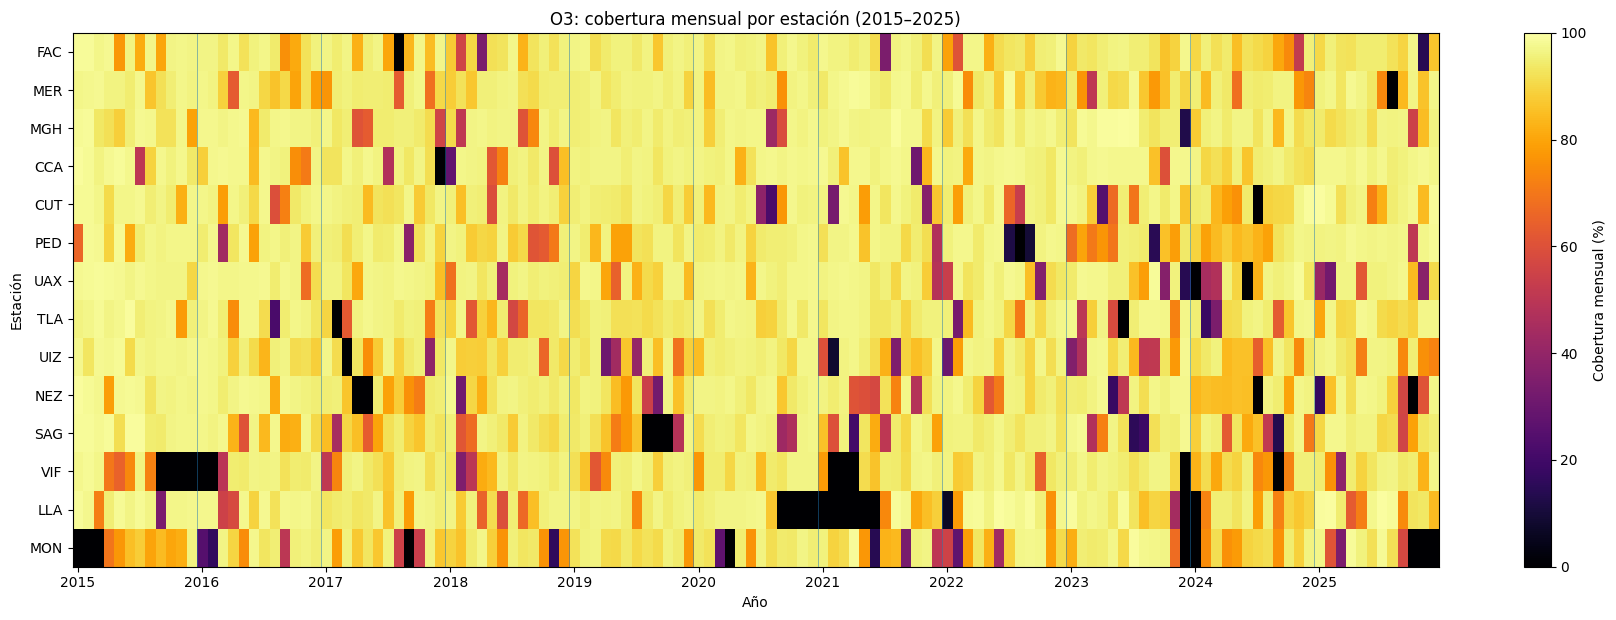

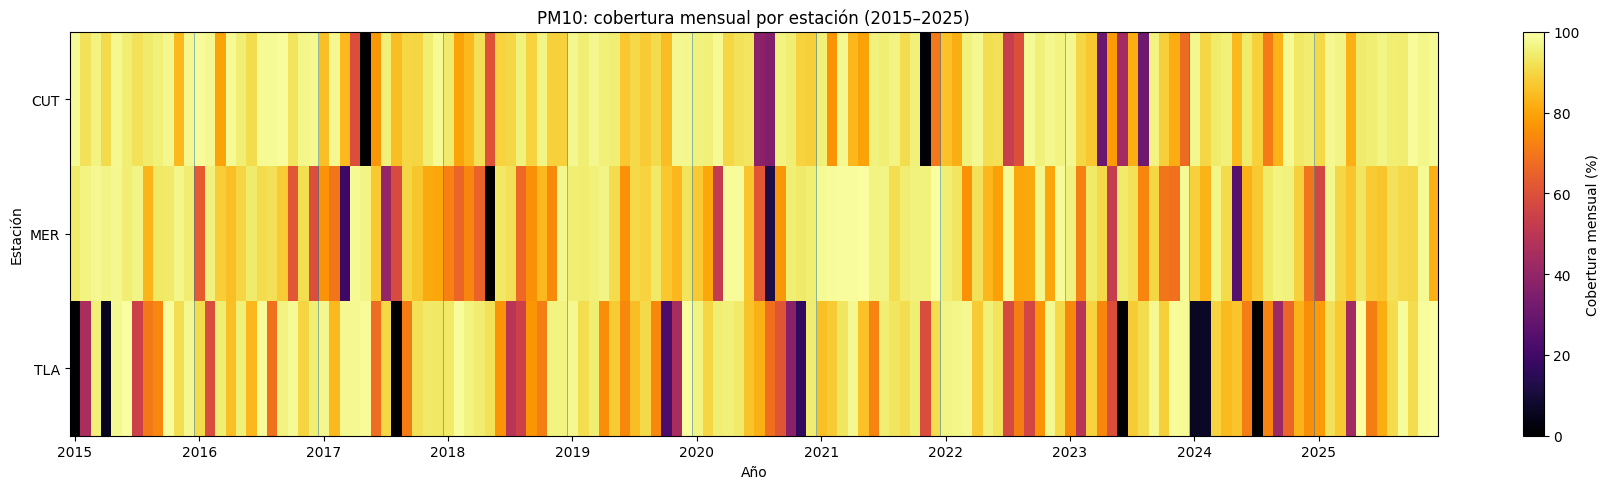

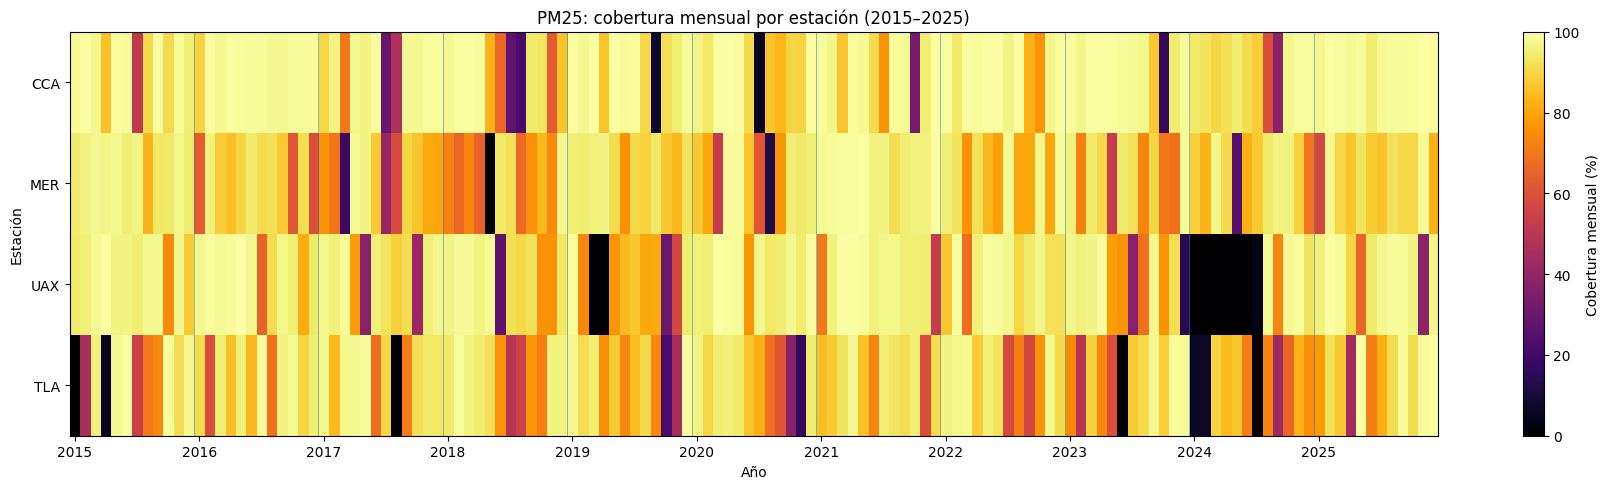

In [15]:
# MAPAS DE CALOR DE LA COBERTURA MENSUAL


# Crear una etiqueta temporal YYYY-MM

cobertura_mensual["FECHA_MES"] = pd.to_datetime(
    dict(
        year=cobertura_mensual["ANIO"],
        month=cobertura_mensual["MES"],
        day=1
    )
)


for contaminante in CONTAMINANTES_OBJETIVO:

    # Orden de estaciones: utilizar el ranking de estabilidad mensual

    orden_estaciones = (
        resumen_mensual.loc[
            resumen_mensual["CONTAMINANTE"]
            == contaminante
        ]
        .sort_values(
            [
                "PCT_MESES_GE_75",
                "MESES_SIN_DATOS",
                "COBERTURA_MENSUAL_MEDIANA"
            ],
            ascending=[
                False,
                True,
                False
            ]
        )["ESTACION"]
        .tolist()
    )

    # Matriz estación × mes

    matriz = (
        cobertura_mensual.loc[
            cobertura_mensual["CONTAMINANTE"]
            == contaminante
        ]
        .pivot(
            index="ESTACION",
            columns="FECHA_MES",
            values="COBERTURA_MENSUAL_PCT"
        )
        .reindex(
            orden_estaciones
        )
    )


    fig, ax = plt.subplots(
        figsize=(18, max(5, 0.45 * len(matriz)))
    )

    imagen = ax.imshow(
        matriz.values,
        cmap='inferno',
        aspect="auto",
        vmin=0,
        vmax=100
    )

    ax.set_yticks(
        range(len(matriz.index))
    )

    ax.set_yticklabels(
        matriz.index
    )


    fechas = matriz.columns

    posiciones_anios = [
        i
        for i, fecha in enumerate(fechas)
        if fecha.month == 1
    ]

    etiquetas_anios = [
        fechas[i].year
        for i in posiciones_anios
    ]

    ax.set_xticks(
        posiciones_anios
    )

    ax.set_xticklabels(
        etiquetas_anios
    )

    # Líneas verticales para separar años
    for posicion in posiciones_anios[1:]:
        ax.axvline(
            posicion - 0.5,
            linewidth=0.7,
            alpha=0.5
        )


    ax.set_title(
        f"{contaminante}: cobertura mensual por estación (2015–2025)"
    )

    ax.set_xlabel(
        "Año"
    )

    ax.set_ylabel(
        "Estación"
    )

    barra = fig.colorbar(
        imagen,
        ax=ax
    )

    barra.set_label(
        "Cobertura mensual (%)"
    )

    plt.tight_layout()
    plt.show()

Las gráficas confirman lo que sugerían las tablas:

- En $O_3$, **FAC, MER, MGH y CCA** muestran una continuidad especialmente buena; CUT, TLA y UIZ también conservan una estructura bastante aprovechable. En cambio, VIF, LLA y MON presentan bloques oscuros prolongados que difícilmente pueden considerarse simples faltantes aislados.

- Para PM10, **CUT y MER** son claramente las estaciones más consistentes. TLA conserva información durante todo el periodo, pero presenta más meses problemáticos y una degradación especialmente visible alrededor de 2024.

- Para PM2.5, **CCA y MER** son las estaciones más estables. El caso de UAX es especialmente ilustrativo: visualmente aparece el gran bloque sin información durante 2024 que ya habíamos cuantificado en aproximadamente (238) días. TLA, por su parte, presenta problemas distribuidos en varios años.

Todavía no elegimos la red definitiva usando umbrales elegidos a mano. El siguiente paso será integrar en una sola tabla los tres niveles de evidencia ya calculamos:

$$
\text{cobertura anual}
+
\text{cobertura mensual}
+
\text{rachas de faltantes}.
$$

Así podremos plantear después un criterio de selección transparente y hacer un análisis de sensibilidad.

## 5.8. Integración de los indicadores de estabilidad temporal

Hasta este punto se han estudiado tres dimensiones complementarias de la
disponibilidad de datos:

1. **continuidad anual**, mediante indicadores como

$$
N_{\geq75}
$$

y la cobertura mediana anual;

2. **continuidad mensual**, mediante la proporción de meses con cobertura
mayor o igual al $75\%$;

3. **estructura de los faltantes**, mediante la duración máxima de las rachas
consecutivas sin información.

Cada indicador describe una característica diferente.

Por ejemplo, una estación puede presentar una cobertura mediana anual elevada,
pero contener un bloque continuo de varios meses sin mediciones. De manera
análoga, otra estación puede presentar muchos faltantes pequeños sin llegar a
tener una interrupción prolongada.

Por ello, antes de establecer una red definitiva de estaciones se construirá
una tabla integrada con los principales indicadores:

$$
\left(
N_{\geq75},
\widetilde{C}_{\mathrm{anual}},
C_{\mathrm{global}},
P_{\mathrm{meses}\geq75},
N_{\mathrm{meses}=0},
L_{\max}
\right),
$$

donde:

- $N_{\geq75}$ es el número de años con cobertura anual de al menos $75\%$;
- $\widetilde{C}_{\mathrm{anual}}$ es la cobertura anual mediana;
- $C_{\mathrm{global}}$ es la cobertura horaria global durante 2015–2025;
- $P_{\mathrm{meses}\geq75}$ es el porcentaje de meses con cobertura de al menos $75\%$;
- $N_{\mathrm{meses}=0}$ es el número de meses completamente sin datos;
- $L_{\max}$ es la duración máxima de una racha consecutiva sin información.

El objetivo de esta tabla no será crear todavía un puntaje artificial ni elegir
automáticamente las estaciones.

Se utilizará para comparar de manera conjunta:

$$
\text{cantidad de información}
\qquad+\qquad
\text{continuidad}
\qquad+\qquad
\text{estabilidad temporal}.
$$

A partir de esta evidencia se podrá evaluar posteriormente la sensibilidad de la selección frente a distintos criterios razonables.

In [16]:
# TABLA INTEGRADA DE ESTABILIDAD TEMPORAL

# Indicadores longitudinales
indicadores_anuales = (
    candidatas_longitudinales[
        [
            "CONTAMINANTE",
            "ESTACION",
            "ANIOS_CON_DATOS",
            "ANIOS_GE_75",
            "ANIOS_GE_90",
            "COBERTURA_MEDIA",
            "COBERTURA_MEDIANA",
            "COBERTURA_MIN"
        ]
    ]
    .copy()
)


# Indicadores mensuales

indicadores_mensuales = (
    resumen_mensual[
        [
            "CONTAMINANTE",
            "ESTACION",
            "PCT_MESES_GE_75",
            "MESES_LT_50",
            "MESES_SIN_DATOS",
            "COBERTURA_MENSUAL_MEDIANA"
        ]
    ]
    .copy()
)


# Indicadores de rachas

indicadores_rachas = (
    resumen_rachas[
        [
            "CONTAMINANTE",
            "ESTACION",
            "COBERTURA_GLOBAL_PCT",
            "MAX_RACHA_FALTANTE_H",
            "MAX_RACHA_FALTANTE_DIAS",
            "RACHAS_GE_24H",
            "RACHAS_GE_72H",
            "RACHAS_GE_168H"
        ]
    ]
    .copy()
)


# Integración de las tres fuentes de información

estabilidad_integrada = (
    indicadores_anuales
    .merge(
        indicadores_mensuales,
        on=[
            "CONTAMINANTE",
            "ESTACION"
        ],
        how="left"
    )
    .merge(
        indicadores_rachas,
        on=[
            "CONTAMINANTE",
            "ESTACION"
        ],
        how="left"
    )
)


# Orden preliminar únicamente para facilitar inspección

estabilidad_integrada = (
    estabilidad_integrada
    .sort_values(
        [
            "CONTAMINANTE",
            "PCT_MESES_GE_75",
            "MAX_RACHA_FALTANTE_DIAS",
            "COBERTURA_GLOBAL_PCT"
        ],
        ascending=[
            True,
            False,
            True,
            False
        ]
    )
    .reset_index(drop=True)
)


# Mostrar indicadores principales

columnas_mostrar = [
    "ESTACION",
    "ANIOS_GE_75",
    "COBERTURA_MEDIANA",
    "COBERTURA_GLOBAL_PCT",
    "PCT_MESES_GE_75",
    "MESES_LT_50",
    "MESES_SIN_DATOS",
    "MAX_RACHA_FALTANTE_DIAS"
]


for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"{contaminante}: indicadores integrados "
        "de estabilidad temporal"
    )

    print(
        "=" * 70
    )

    tabla = (
        estabilidad_integrada.loc[
            estabilidad_integrada[
                "CONTAMINANTE"
            ] == contaminante,
            columnas_mostrar
        ]
        .reset_index(drop=True)
    )

    display(tabla)


O3: indicadores integrados de estabilidad temporal


,ESTACION,ANIOS_GE_75,COBERTURA_MEDIANA,COBERTURA_GLOBAL_PCT,PCT_MESES_GE_75,MESES_LT_50,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS
0,FAC,11,90.19,89.86,93.9,4,1,40.5
1,MER,11,90.01,90.83,93.2,1,1,42.5
2,MGH,11,93.50,91.92,92.4,2,0,28.5
3,CCA,11,92.96,91.59,92.4,4,1,54.5
4,CUT,11,89.25,88.77,89.4,6,1,42.7
5,PED,10,89.77,87.79,88.6,7,1,85.0
6,TLA,11,87.74,88.36,87.1,6,2,43.5
7,UAX,10,89.13,87.76,87.1,12,2,72.8
8,UIZ,11,87.69,86.02,84.8,10,1,37.6
9,NEZ,9,85.72,85.59,84.8,9,4,64.1



PM10: indicadores integrados de estabilidad temporal


,ESTACION,ANIOS_GE_75,COBERTURA_MEDIANA,COBERTURA_GLOBAL_PCT,PCT_MESES_GE_75,MESES_LT_50,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS
0,CUT,10,87.47,87.31,89.4,7,1,38.6
1,MER,9,83.19,84.55,81.1,5,1,42.0
2,TLA,9,82.01,79.00,68.9,16,4,55.8



PM25: indicadores integrados de estabilidad temporal


,ESTACION,ANIOS_GE_75,COBERTURA_MEDIANA,COBERTURA_GLOBAL_PCT,PCT_MESES_GE_75,MESES_LT_50,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS
0,CCA,11,89.20,89.68,89.4,9,0,46.1
1,MER,9,83.19,84.55,81.1,5,1,42.0
2,UAX,9,89.32,82.27,80.3,16,8,238.3
3,TLA,9,82.01,79.00,68.9,16,4,55.8


Estas tablas muestran una jerarquía clara, pero hay un punto metodológico importante: no conviene convertir inmediatamente esa jerarquía en una selección definitiva. Si escogemos, por ejemplo, “máximo 60 días de hueco” sin estudiar qué ocurre al mover ese límite, el criterio sería difícil de justificar.

Tenemos que hacer un análisis de sensibilidad de la selección temporal. Definiremos tres escenarios, desde el filtro longitudinal inicial hasta un núcleo más exigente. No pretendemos demostrar que uno sea “el correcto”, sino identificar estaciones que sobreviven a cambios razonables en los criterios.

## 5.9. Sensibilidad de la selección frente a los criterios de estabilidad

Los indicadores integrados permiten comparar simultáneamente la cobertura anual,
la continuidad mensual y la duración de las interrupciones.

Sin embargo, no existe un único umbral natural que permita declarar
automáticamente que una estación es adecuada o inadecuada.

Por ejemplo, podría exigirse que la racha máxima sin datos sea menor que $60$ días, pero también sería razonable explorar límites de $90$ días.

De manera análoga, la proporción mínima de meses con cobertura suficiente podría establecerse en $80\%$ o en $85\%$.

Para evitar que la selección dependa de una única combinación arbitraria de umbrales, se realizará un **análisis de sensibilidad** mediante tres escenarios.

### Escenario A: preselección longitudinal

Corresponde al criterio utilizado hasta ahora:

$$
N_{\geq75}\geq9.
$$

Todas las estaciones analizadas en esta sección cumplen además con datos válidos
en los once años.

Este escenario representa la red candidata más amplia.


### Escenario B: estabilidad temporal moderada

Además de la condición anterior, se exigirá:

$$
P_{\mathrm{meses}\geq75}\geq80\%,
$$

$$
N_{\mathrm{meses}=0}\leq2,
$$

y

$$
L_{\max}\leq90\text{ días}.
$$

Este escenario permite interrupciones ocasionales, pero elimina estaciones con
bloques extremadamente largos o con demasiados meses completamente ausentes.


### Escenario C: núcleo temporal robusto

Se utilizará un criterio más exigente:

$$
N_{\geq75}\geq10,
$$

$$
P_{\mathrm{meses}\geq75}\geq85\%,
$$

$$
N_{\mathrm{meses}=0}\leq1,
$$

y

$$
L_{\max}\leq60\text{ días}.
$$

Este escenario pretende identificar estaciones con una trayectoria temporal
especialmente estable.



### Interpretación

Los tres escenarios no deben interpretarse como tres modelos diferentes ni como
una selección definitiva.

Su finalidad es determinar qué estaciones son **robustas frente a cambios
razonables en los criterios de cobertura**.

Una estación que permanece seleccionada bajo los escenarios B y C constituye un
candidato temporal particularmente fuerte.

En cambio, una estación que solamente aparece en el escenario A puede seguir
siendo útil, pero requerirá una justificación adicional.

Finalmente, la decisión sobre la red de estaciones no dependerá exclusivamente
de la continuidad temporal. También deberá considerarse posteriormente su
**representatividad espacial**, ya que para estudiar contingencias atmosféricas
no sería adecuado conservar únicamente estaciones muy completas si todas
representaran una zona geográfica similar.

In [17]:
# ANÁLISIS DE SENSIBILIDAD DE LA SELECCIÓN TEMPORAL

sensibilidad_estaciones = (
    estabilidad_integrada
    .copy()
)

# ESCENARIO A: Preselección longitudinal original

sensibilidad_estaciones["ESCENARIO_A"] = (
    sensibilidad_estaciones["ANIOS_GE_75"] >= 9
)

# ESCENARIO B: Estabilidad temporal moderada

sensibilidad_estaciones["ESCENARIO_B"] = (
    (sensibilidad_estaciones["ANIOS_GE_75"] >= 9)
    &
    (sensibilidad_estaciones["PCT_MESES_GE_75"] >= 80)
    &
    (sensibilidad_estaciones["MESES_SIN_DATOS"] <= 2)
    &
    (
        sensibilidad_estaciones[
            "MAX_RACHA_FALTANTE_DIAS"
        ] <= 90
    )
)


# ESCENARIO C: Núcleo temporal robusto

sensibilidad_estaciones["ESCENARIO_C"] = (
    (sensibilidad_estaciones["ANIOS_GE_75"] >= 10)
    &
    (sensibilidad_estaciones["PCT_MESES_GE_75"] >= 85)
    &
    (sensibilidad_estaciones["MESES_SIN_DATOS"] <= 1)
    &
    (
        sensibilidad_estaciones[
            "MAX_RACHA_FALTANTE_DIAS"
        ] <= 60
    )
)


# RESUMEN DE NÚMERO DE ESTACIONES

resumen_sensibilidad = (
    sensibilidad_estaciones
    .groupby("CONTAMINANTE")
    [
        [
            "ESCENARIO_A",
            "ESCENARIO_B",
            "ESCENARIO_C"
        ]
    ]
    .sum()
    .astype(int)
    .reindex(
        CONTAMINANTES_OBJETIVO
    )
)

print(
    "Número de estaciones seleccionadas "
    "bajo cada escenario:"
)

display(
    resumen_sensibilidad
)


# DETALLE POR CONTAMINANTE

for contaminante in CONTAMINANTES_OBJETIVO:

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"{contaminante}: sensibilidad de la selección"
    )

    print(
        "=" * 70
    )

    tabla = (
        sensibilidad_estaciones.loc[
            sensibilidad_estaciones[
                "CONTAMINANTE"
            ] == contaminante,
            [
                "ESTACION",
                "ANIOS_GE_75",
                "PCT_MESES_GE_75",
                "MESES_SIN_DATOS",
                "MAX_RACHA_FALTANTE_DIAS",
                "ESCENARIO_A",
                "ESCENARIO_B",
                "ESCENARIO_C"
            ]
        ]
        .sort_values(
            [
                "ESCENARIO_C",
                "ESCENARIO_B",
                "PCT_MESES_GE_75"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .reset_index(drop=True)
    )

    display(
        tabla
    )


# ESTACIONES DEL NÚCLEO ROBUSTO

print(
    "\nEstaciones que forman el núcleo "
    "temporal robusto (Escenario C):"
)

for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones_nucleo = (
        sensibilidad_estaciones.loc[
            (
                sensibilidad_estaciones[
                    "CONTAMINANTE"
                ] == contaminante
            )
            &
            (
                sensibilidad_estaciones[
                    "ESCENARIO_C"
                ]
            ),
            "ESTACION"
        ]
        .tolist()
    )

    print(
        f"{contaminante}: {estaciones_nucleo}"
    )

Número de estaciones seleccionadas bajo cada escenario:


,ESCENARIO_A,ESCENARIO_B,ESCENARIO_C
CONTAMINANTE,,,
O3,14,9,5
PM10,3,2,1
PM25,4,2,1



O3: sensibilidad de la selección


,ESTACION,ANIOS_GE_75,PCT_MESES_GE_75,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS,ESCENARIO_A,ESCENARIO_B,ESCENARIO_C
0,FAC,11,93.9,1,40.5,True,True,True
1,MER,11,93.2,1,42.5,True,True,True
2,MGH,11,92.4,0,28.5,True,True,True
3,CCA,11,92.4,1,54.5,True,True,True
4,CUT,11,89.4,1,42.7,True,True,True
5,PED,10,88.6,1,85.0,True,True,False
6,TLA,11,87.1,2,43.5,True,True,False
7,UAX,10,87.1,2,72.8,True,True,False
8,UIZ,11,84.8,1,37.6,True,True,False
9,NEZ,9,84.8,4,64.1,True,False,False



PM10: sensibilidad de la selección


,ESTACION,ANIOS_GE_75,PCT_MESES_GE_75,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS,ESCENARIO_A,ESCENARIO_B,ESCENARIO_C
0,CUT,10,89.4,1,38.6,True,True,True
1,MER,9,81.1,1,42.0,True,True,False
2,TLA,9,68.9,4,55.8,True,False,False



PM25: sensibilidad de la selección


,ESTACION,ANIOS_GE_75,PCT_MESES_GE_75,MESES_SIN_DATOS,MAX_RACHA_FALTANTE_DIAS,ESCENARIO_A,ESCENARIO_B,ESCENARIO_C
0,CCA,11,89.4,0,46.1,True,True,True
1,MER,9,81.1,1,42.0,True,True,False
2,UAX,9,80.3,8,238.3,True,False,False
3,TLA,9,68.9,4,55.8,True,False,False



Estaciones que forman el núcleo temporal robusto (Escenario C):
O3: ['FAC', 'MER', 'MGH', 'CCA', 'CUT']
PM10: ['CUT']
PM25: ['CCA']


Este resultado es muy útil porque muestra algo que debemos cuidar metodológicamente: el Escenario C no debe convertirse automáticamente en nuestra red final. Para $O_3$ todavía deja cinco estaciones, pero para PM10 y PM2.5 deja sólo una:

$$
S_{PM10}^{(C)}={\mathrm{CUT}},
\qquad
S_{PM2.5}^{(C)}={\mathrm{CCA}}.
$$

Eso sería temporalmente muy limpio, pero probablemente demasiado restrictivo espacialmente para estudiar contingencias en la ZMVM.

Por ahora considero más razonable conservar el Escenario B como red candidata principal:

$$
9\text{ estaciones de }O_3,\qquad
2\text{ de PM}_{10},\qquad
2\text{ de PM}_{2.5},
$$

y mantener el Escenario A como conjunto ampliado de respaldo. Antes de decidir, necesitamos saber qué estaciones coinciden entre contaminantes y qué tan dependiente sería el estudio de unas pocas estaciones.

## 5.10. Redes candidatas por contaminante y coincidencia entre ellas

El análisis de sensibilidad mostró que aumentar la exigencia temporal reduce
considerablemente el número de estaciones disponibles.

En particular, el escenario más estricto produce

$$
|S_{O_3}^{(C)}|=5,
\qquad
|S_{PM_{10}}^{(C)}|=1,
\qquad
|S_{PM_{2.5}}^{(C)}|=1.
$$

Aunque estas estaciones presentan una elevada estabilidad temporal, seleccionar
la red únicamente con este criterio podría producir una representación espacial
demasiado limitada.

Esto es especialmente importante porque una contingencia atmosférica es un
fenómeno que se evalúa a partir de una **red de monitoreo**, no de una única serie
temporal.

Por esta razón, en esta etapa se distinguirán tres niveles de estaciones:

- **Red ampliada**: estaciones del Escenario A;
- **Red candidata principal**: estaciones del Escenario B;
- **Núcleo temporal robusto**: estaciones del Escenario C.

La red candidata principal se utilizará como punto de partida para el análisis
espacial posterior, mientras que el núcleo robusto permitirá identificar las
estaciones con mayor continuidad temporal dentro de ella.

También se estudiará la coincidencia de estaciones entre contaminantes.

Para dos contaminantes $c_1$ y $c_2$, la intersección

$$
S_{c_1}\cap S_{c_2}
$$

representa las estaciones capaces de proporcionar información para ambos
contaminantes dentro del mismo escenario de selección.

Estas intersecciones son útiles porque una estación común puede permitir
posteriormente estudiar conjuntamente distintos componentes de la contaminación.

Sin embargo, **no se exigirá que las estaciones sean comunes a los tres
contaminantes**.

El objetivo continúa siendo mantener redes específicas:

$$
S_{O_3},
\qquad
S_{PM_{10}},
\qquad
S_{PM_{2.5}}.
$$

En esta etapa se analizará únicamente la composición de estas redes. La
representatividad geográfica se estudiará después mediante la localización de las
estaciones.

In [18]:
# REDES CANDIDATAS Y COINCIDENCIA ENTRE CONTAMINANTES

redes = {}

for escenario in [
    "ESCENARIO_A",
    "ESCENARIO_B",
    "ESCENARIO_C"
]:

    redes[escenario] = {}

    for contaminante in CONTAMINANTES_OBJETIVO:

        estaciones = sorted(
            sensibilidad_estaciones.loc[
                (
                    sensibilidad_estaciones[
                        "CONTAMINANTE"
                    ] == contaminante
                )
                &
                (
                    sensibilidad_estaciones[
                        escenario
                    ]
                ),
                "ESTACION"
            ]
            .tolist()
        )

        redes[escenario][
            contaminante
        ] = estaciones


# MOSTRAR REDES

for escenario in [
    "ESCENARIO_A",
    "ESCENARIO_B",
    "ESCENARIO_C"
]:

    print(
        "\n"
        + "=" * 50
    )

    print(
        escenario
    )

    print(
        "=" * 50
    )

    for contaminante in CONTAMINANTES_OBJETIVO:

        estaciones = (
            redes[
                escenario
            ][
                contaminante
            ]
        )

        print(
            f"{contaminante}: "
            f"{len(estaciones)} estaciones"
        )

        print(
            estaciones
        )


# INTERSECCIONES EN EL ESCENARIO B

o3_b = set(
    redes["ESCENARIO_B"]["O3"]
)

pm10_b = set(
    redes["ESCENARIO_B"]["PM10"]
)

pm25_b = set(
    redes["ESCENARIO_B"]["PM25"]
)


print(
    "\n"
    + "=" * 70
)

print(
    "Coincidencia entre contaminantes "
    "- Escenario B"
)

print(
    "=" * 70
)


print(
    "\nO3 ∩ PM10:"
)

print(
    sorted(
        o3_b & pm10_b
    )
)


print(
    "\nO3 ∩ PM25:"
)

print(
    sorted(
        o3_b & pm25_b
    )
)


print(
    "\nPM10 ∩ PM25:"
)

print(
    sorted(
        pm10_b & pm25_b
    )
)


print(
    "\nO3 ∩ PM10 ∩ PM25:"
)

print(
    sorted(
        o3_b
        & pm10_b
        & pm25_b
    )
)


# UNIÓN DE ESTACIONES DEL ESCENARIO B

union_b = sorted(
    o3_b
    | pm10_b
    | pm25_b
)

print(
    "\nNúmero total de estaciones distintas "
    "en la red candidata B:",
    len(union_b)
)

print(
    union_b
)


ESCENARIO_A
O3: 14 estaciones
['CCA', 'CUT', 'FAC', 'LLA', 'MER', 'MGH', 'MON', 'NEZ', 'PED', 'SAG', 'TLA', 'UAX', 'UIZ', 'VIF']
PM10: 3 estaciones
['CUT', 'MER', 'TLA']
PM25: 4 estaciones
['CCA', 'MER', 'TLA', 'UAX']

ESCENARIO_B
O3: 9 estaciones
['CCA', 'CUT', 'FAC', 'MER', 'MGH', 'PED', 'TLA', 'UAX', 'UIZ']
PM10: 2 estaciones
['CUT', 'MER']
PM25: 2 estaciones
['CCA', 'MER']

ESCENARIO_C
O3: 5 estaciones
['CCA', 'CUT', 'FAC', 'MER', 'MGH']
PM10: 1 estaciones
['CUT']
PM25: 1 estaciones
['CCA']

Coincidencia entre contaminantes - Escenario B

O3 ∩ PM10:
['CUT', 'MER']

O3 ∩ PM25:
['CCA', 'MER']

PM10 ∩ PM25:
['MER']

O3 ∩ PM10 ∩ PM25:
['MER']

Número total de estaciones distintas en la red candidata B: 9
['CCA', 'CUT', 'FAC', 'MER', 'MGH', 'PED', 'TLA', 'UAX', 'UIZ']


La salida confirma muy bien la lógica del enfoque. En el Escenario B tenemos una red física de 9 estaciones distintas, pero cada contaminante utiliza su propio subconjunto:

$$
S_{O_3}^{(B)}={\text{CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ}},
$$

$$
S_{PM10}^{(B)}={\text{CUT,MER}},
$$

$$
S_{PM2.5}^{(B)}={\text{CCA,MER}}.
$$

Además,

$$
S_{O_3}^{(B)} \cap S_{PM10}^{(B)} \cap S_{PM2.5}^{(B)}={\text{MER}}.
$$



## 5.11. Composición de la red candidata principal

El Escenario B identifica una red candidata formada por nueve estaciones
distintas, pero no todas ellas participan en los tres problemas de predicción.

Para representar esta estructura se construirá una matriz de pertenencia

$$
R_{s,c}
=
\begin{cases}
1, & \text{si la estación }s\text{ pertenece a la red candidata del contaminante }c,\\
0, & \text{en otro caso}.
\end{cases}
$$

Las columnas corresponderán a

$$
O_3,\qquad PM_{10},\qquad PM_{2.5},
$$

y las filas a las estaciones que aparecen en al menos una de las redes del
Escenario B.

Esta representación permitirá distinguir:

- estaciones utilizadas únicamente para $O_3$;
- estaciones compartidas entre $O_3$ y partículas;
- estaciones disponibles para más de un tipo de partícula;
- estaciones comunes a los tres contaminantes.

Es importante subrayar que una estación común a varios contaminantes puede ser
especialmente útil para estudiar relaciones multivariadas, pero no tendrá
prioridad automática sobre estaciones específicas de un contaminante.

En particular,

$$
\text{pertenecer a más redes}
\not\Rightarrow
\text{ser más representativa espacialmente}.
$$

Por ello, la matriz de pertenencia se utilizará únicamente para describir la
estructura de la red candidata.

El siguiente paso será incorporar la ubicación geográfica de estas estaciones
para evaluar si el conjunto seleccionado proporciona una cobertura espacial
razonable de la zona de estudio.

In [19]:
# MATRIZ DE PERTENENCIA DE LA RED CANDIDATA B


# Estaciones distintas de la red candidata

estaciones_red_b = sorted(
    set(
        redes["ESCENARIO_B"]["O3"]
    )
    |
    set(
        redes["ESCENARIO_B"]["PM10"]
    )
    |
    set(
        redes["ESCENARIO_B"]["PM25"]
    )
)


# Construir matriz estación × contaminante

matriz_red_b = pd.DataFrame(
    index=estaciones_red_b
)

for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones_contaminante = set(
        redes["ESCENARIO_B"][
            contaminante
        ]
    )

    matriz_red_b[
        contaminante
    ] = [
        estacion in estaciones_contaminante
        for estacion in estaciones_red_b
    ]


# Número de contaminantes objetivo disponibles

matriz_red_b[
    "N_CONTAMINANTES_OBJETIVO"
] = (
    matriz_red_b[
        CONTAMINANTES_OBJETIVO
    ]
    .sum(axis=1)
)


# Descripción del papel de cada estación

def describir_contaminantes(fila):

    disponibles = [
        contaminante
        for contaminante in CONTAMINANTES_OBJETIVO
        if fila[contaminante]
    ]

    return ", ".join(
        disponibles
    )


matriz_red_b[
    "CONTAMINANTES"
] = (
    matriz_red_b.apply(
        describir_contaminantes,
        axis=1
    )
)


# Ordenar primero las estaciones con mayor coincidencia

matriz_red_b = (
    matriz_red_b
    .sort_values(
        [
            "N_CONTAMINANTES_OBJETIVO"
        ],
        ascending=False
    )
)


print(
    "Composición de la red candidata principal "
    "(Escenario B):"
)

display(
    matriz_red_b
)


# Resumen

print(
    "\nNúmero total de estaciones distintas:",
    len(matriz_red_b)
)

print(
    "\nDistribución según número de contaminantes objetivo:"
)

display(
    matriz_red_b[
        "N_CONTAMINANTES_OBJETIVO"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "N_CONTAMINANTES"
    )
    .rename(
        "N_ESTACIONES"
    )
    .to_frame()
)

Composición de la red candidata principal (Escenario B):


,O3,PM10,PM25,N_CONTAMINANTES_OBJETIVO,CONTAMINANTES
MER,True,True,True,3,"O3, PM10, PM25"
CCA,True,False,True,2,"O3, PM25"
CUT,True,True,False,2,"O3, PM10"
FAC,True,False,False,1,O3
MGH,True,False,False,1,O3
PED,True,False,False,1,O3
TLA,True,False,False,1,O3
UAX,True,False,False,1,O3
UIZ,True,False,False,1,O3



Número total de estaciones distintas: 9

Distribución según número de contaminantes objetivo:


,N_ESTACIONES
N_CONTAMINANTES,
1,6
2,2
3,1


La salida confirma que el enfoque independiente por contaminante está funcionando bien. En particular, MER es la única estación que aparece en los tres conjuntos del Escenario B, pero eso no significa que deba convertirse en la estación representativa de todo el proyecto.

Antes de pasar al componente espacial, haremos un diagnóstico adicional: **¿qué tan bien se complementan temporalmente las estaciones del Escenario B dentro de cada contaminante?**

Esto es especialmente relevante para partículas, porque sólo tenemos dos estaciones candidatas:

$$
PM_{10}:{\mathrm{CUT},\mathrm{MER}},
\qquad
PM_{2.5}:{\mathrm{CCA},\mathrm{MER}}.
$$

Queremos saber si sus faltantes ocurren simultáneamente o si una estación suele cubrir los huecos de la otra.

## 5.12. Complementariedad temporal de las redes candidatas

Hasta ahora la calidad temporal se ha evaluado estación por estación.

Sin embargo, el problema de contingencias atmosféricas se estudiará utilizando
una **red de estaciones**, por lo que también es necesario evaluar la
disponibilidad conjunta del sistema de monitoreo seleccionado.

Para cada contaminante se considerará la red candidata del Escenario B:

$$
S_c^{(B)}.
$$

En cada hora $t$ se contará el número de estaciones que presentan una medición
válida:

$$
K_{c,t}
=
\sum_{s\in S_c^{(B)}} I(V_{s,c,t}=1),
$$

donde

$$
V_{s,c,t}
=
\begin{cases}
1, & \text{si la estación }s\text{ tiene una medición válida},\\
0, & \text{en otro caso}.
\end{cases}
$$

Por tanto,

$$
0\leq K_{c,t}\leq |S_c^{(B)}|.
$$

Este indicador permitirá responder preguntas como:

- ¿qué porcentaje de las horas tiene al menos una estación disponible?;
- ¿qué porcentaje tiene al menos dos estaciones disponibles?;
- ¿con qué frecuencia queda completamente sin información la red candidata?;
- ¿cuál es la interrupción continua más larga en la que ninguna estación
  proporciona información?

La primera cantidad puede expresarse como

$$
P(K_{c,t}\geq1),
$$

mientras que la disponibilidad simultánea de al menos dos estaciones será

$$
P(K_{c,t}\geq2).
$$

Para las redes de partículas, formadas por dos estaciones, también resulta
informativo calcular

$$
P(K_{c,t}=2),
$$

es decir, la proporción del tiempo en la que ambas estaciones proporcionan
información simultáneamente.


### Por qué es importante este análisis

Dos estaciones pueden tener individualmente coberturas moderadas y, sin embargo,
formar una red temporalmente muy completa si sus periodos faltantes no
coinciden.

Por el contrario, dos estaciones con coberturas individuales elevadas pueden
aportar poca complementariedad si ambas dejan de medir durante los mismos
periodos.

Por ello,

$$
\text{calidad de cada estación}
\neq
\text{calidad temporal de la red}.
$$

La disponibilidad se calculará sobre la cuadrícula horaria teórica completa de
2015–2025, de manera que cualquier hora ausente de los archivos también sea
considerada explícitamente como información faltante.

Esta etapa continúa siendo un diagnóstico de cobertura. Todavía no se
construirán índices de contaminación ni etiquetas de contingencia.

In [20]:
# COMPLEMENTARIEDAD TEMPORAL DE LAS REDES DEL ESCENARIO B

resultados_red_horaria = []
resultados_red_anual = []

series_disponibilidad_red = {}


for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones = (
        redes["ESCENARIO_B"][
            contaminante
        ]
    )

    # Construir las series horarias 2015–2025
    bloques = []

    for anio in ANIOS:

        ruta = Path(
            inventario_objetivo.loc[
                (
                    inventario_objetivo["ANIO"]
                    == anio
                )
                &
                (
                    inventario_objetivo[
                        "CONTAMINANTE"
                    ]
                    == contaminante
                ),
                "RUTA"
            ].iloc[0]
        )

        df = pd.read_excel(
            ruta
        )

        fecha = pd.to_datetime(
            df["FECHA"],
            errors="coerce"
        )

        hora = pd.to_numeric(
            df["HORA"],
            errors="coerce"
        )

        timestamp = (
            fecha
            + pd.to_timedelta(#se utiliza para convertir datos a un tipo de dato de duración o intervalo de tiempo
                hora - 1,
                unit="h"
            )
        )

        bloque = pd.DataFrame(
            index=timestamp#representa un punto único e instantáneo en el tiempo
        )

        for estacion in estaciones:

            if estacion in df.columns:

                serie = pd.to_numeric(
                    df[estacion],
                    errors="coerce"
                )

                bloque[estacion] = (
                    serie.to_numpy()
                )

            else:

                bloque[estacion] = np.nan

        bloques.append(
            bloque
        )

    datos_red = pd.concat(
        bloques
    )

    # Reindexar contra TODAS las horas teóricas
    datos_red = (
        datos_red
        .reindex(
            indice_horario_completo
        )
    )

    # Matriz booleana de disponibilidad
    validas = (
        datos_red.notna()
        & (datos_red != -99)
    )

    # Número de estaciones disponibles cada hora
    k_disponibles = (
        validas.sum(axis=1)
    )

    series_disponibilidad_red[
        contaminante
    ] = k_disponibles


    # Rachas con CERO estaciones disponibles

    hay_alguna = (
        k_disponibles >= 1
    )

    rachas_cero = (
        longitudes_rachas_faltantes(
            hay_alguna
        )
    )

    max_racha_cero_h = (
        int(rachas_cero.max())
        if len(rachas_cero) > 0
        else 0
    )


    # RESUMEN GLOBAL

    n_estaciones = len(
        estaciones
    )

    registro_global = {
        "CONTAMINANTE":
            contaminante,

        "N_ESTACIONES":
            n_estaciones,

        "PCT_HORAS_CERO":
            100 * (k_disponibles == 0).mean(),

        "PCT_HORAS_GE_1":
            100 * (k_disponibles >= 1).mean(),

        "PCT_HORAS_GE_2":
            (
                100 * (k_disponibles >= 2).mean()
                if n_estaciones >= 2
                else np.nan
            ),

        "PCT_HORAS_TODAS":
            100 * (
                k_disponibles == n_estaciones
            ).mean(),

        "MAX_RACHA_CERO_H":
            max_racha_cero_h,

        "MAX_RACHA_CERO_DIAS":
            max_racha_cero_h / 24
    }

    resultados_red_horaria.append(
        registro_global
    )


    # RESUMEN POR AÑO

    for anio in ANIOS:

        mascara_anio = (
            k_disponibles.index.year
            == anio
        )

        k_anio = (
            k_disponibles.loc[
                mascara_anio
            ]
        )

        resultados_red_anual.append({
            "CONTAMINANTE":
                contaminante,

            "ANIO":
                anio,

            "PCT_HORAS_CERO":
                100 * (
                    k_anio == 0
                ).mean(),

            "PCT_HORAS_GE_1":
                100 * (
                    k_anio >= 1
                ).mean(),

            "PCT_HORAS_GE_2":
                (
                    100 * (
                        k_anio >= 2
                    ).mean()
                    if n_estaciones >= 2
                    else np.nan
                )
        })


# TABLAS FINALES

resumen_red_horaria = pd.DataFrame(
    resultados_red_horaria
)

resumen_red_anual = pd.DataFrame(
    resultados_red_anual
)


columnas_pct_global = [
    "PCT_HORAS_CERO",
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2",
    "PCT_HORAS_TODAS"
]

resumen_red_horaria[
    columnas_pct_global
] = (
    resumen_red_horaria[
        columnas_pct_global
    ]
    .round(2)
)

resumen_red_horaria[
    "MAX_RACHA_CERO_DIAS"
] = (
    resumen_red_horaria[
        "MAX_RACHA_CERO_DIAS"
    ]
    .round(1)
)


print(
    "Disponibilidad horaria global de "
    "las redes candidatas (Escenario B):"
)

display(resumen_red_horaria)


# Matriz anual: porcentaje de horas con al menos una estación disponible

print(
    "\nPorcentaje anual de horas con "
    "al menos una estación disponible:"
)

matriz_ge1 = (
    resumen_red_anual
    .pivot(
        index="CONTAMINANTE",
        columns="ANIO",
        values="PCT_HORAS_GE_1"
    )
    .round(2)
)

display(matriz_ge1)


# Matriz anual: porcentaje de horas con al menos dos estaciones disponibles

print(
    "\nPorcentaje anual de horas con "
    "al menos dos estaciones disponibles:"
)

matriz_ge2 = (
    resumen_red_anual
    .pivot(
        index="CONTAMINANTE",
        columns="ANIO",
        values="PCT_HORAS_GE_2"
    )
    .round(2)
)

display(matriz_ge2)

Disponibilidad horaria global de las redes candidatas (Escenario B):


,CONTAMINANTE,N_ESTACIONES,PCT_HORAS_CERO,PCT_HORAS_GE_1,PCT_HORAS_GE_2,PCT_HORAS_TODAS,MAX_RACHA_CERO_H,MAX_RACHA_CERO_DIAS
0,O3,9,1.96,98.04,97.79,42.78,6,0.2
1,PM10,2,2.80,97.20,74.66,74.66,699,29.1
2,PM25,2,2.44,97.56,76.66,76.66,703,29.3



Porcentaje anual de horas con al menos una estación disponible:


ANIO,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
CONTAMINANTE,,,,,,,,,,,
O3,98.44,97.86,97.61,97.32,97.24,97.39,98.56,98.40,98.87,97.84,98.90
PM10,99.79,98.90,96.15,94.61,99.37,91.34,99.37,98.53,95.03,97.72,98.38
PM25,99.69,99.48,88.68,95.50,99.06,95.21,99.49,99.39,98.52,98.44,99.74



Porcentaje anual de horas con al menos dos estaciones disponibles:


ANIO,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
CONTAMINANTE,,,,,,,,,,,
O3,98.44,97.86,97.61,97.32,97.24,97.39,98.05,98.06,98.05,97.48,98.18
PM10,89.42,79.59,56.94,64.43,84.27,70.64,79.45,76.40,60.22,75.91,84.01
PM25,87.13,81.48,69.53,53.41,80.33,68.99,86.76,83.78,74.63,71.02,86.21


Estos resultados muestran que la complementariedad temporal sí aporta mucho, especialmente para partículas.

Para PM10, CUT y MER individualmente tenían coberturas globales de (87.31%) y (84.55%), pero al permitir que cualquiera de las dos aporte información obtenemos

$$
P(K_{PM10,t}\geq1)=97.20%.
$$

Para PM2.5 ocurre algo similar con CCA y MER:

$$
P(K_{PM2.5,t}\geq1)=97.56%.
$$

Esto confirma que no sería conveniente quedarnos únicamente con CUT para PM10 o únicamente con CCA para PM2.5 sólo porque pertenecen al Escenario C.

También hay una advertencia importante: aunque la cobertura de red supera el (97%), tanto PM10 como PM2.5 presentan una racha de aproximadamente 29 días en la que ninguna de las dos estaciones tiene información válida.

## 5.13. Localización de las interrupciones de la red completa

El análisis anterior mostró que las estaciones seleccionadas presentan una
complementariedad temporal importante.

Para cada contaminante, la probabilidad de disponer de al menos una estación
válida es aproximadamente

$$
P(K_{O_3,t}\geq1)=98.04\%,
$$

$$
P(K_{PM_{10},t}\geq1)=97.20\%,
$$

y

$$
P(K_{PM_{2.5},t}\geq1)=97.56\%.
$$

Sin embargo, una cobertura global elevada puede ocultar interrupciones
continuas importantes.

En particular, las redes candidatas de partículas presentan una racha máxima
con

$$
K_{c,t}=0
$$

de aproximadamente $29$ días.

Esto significa que durante ese intervalo ninguna estación de la red candidata
dispone de una observación válida para el contaminante correspondiente.

Antes de concluir que la cobertura temporal es suficiente, se localizarán
explícitamente estas interrupciones.

Para cada contaminante se identificarán las rachas consecutivas en las que

$$
K_{c,t}=0,
$$

y para cada racha se registrarán:

- instante inicial;
- instante final;
- duración en horas;
- duración aproximada en días.

Se mostrarán las interrupciones más largas de cada red.

Este diagnóstico permitirá determinar si los periodos sin información:

- se concentran en un único episodio;
- aparecen repetidamente;
- coinciden entre PM10 y PM2.5;
- afectan años que posteriormente podrían ser utilizados para entrenamiento
  o validación temporal.

Una interrupción común entre distintos contaminantes también podría sugerir
problemas operativos compartidos entre estaciones o periodos específicos de la
red de monitoreo.

Todavía no se realizará ninguna imputación ni se eliminarán periodos.

In [21]:
# LOCALIZAR LAS RACHAS CON CERO ESTACIONES DISPONIBLES

def identificar_rachas_cero(k_disponibles):
    """
    Identifica rachas consecutivas en las que ninguna
    estación de la red tiene información válida.

    k_disponibles:
        Serie temporal con el número de estaciones
        disponibles en cada hora.
    """

    mascara_cero = (
        k_disponibles == 0
    )

    # Cambios entre estado cero / no cero
    grupos = (
        mascara_cero.ne( #no es igual
            mascara_cero.shift()
        )
        .cumsum()
    )

    registros = []

    for _, bloque in (#Itera sobre los elementos, pero ignora la primera parte de cada par y guarda solo la segunda parte en la variable bloque
        k_disponibles[
            mascara_cero
        ]
        .groupby(
            grupos[
                mascara_cero
            ]
        )
    ):

        inicio = (
            bloque.index.min()
        )

        fin = (
            bloque.index.max()
        )

        duracion_h = (
            len(bloque)
        )

        registros.append({
            "INICIO":
                inicio,

            "FIN":
                fin,

            "DURACION_H":
                duracion_h,

            "DURACION_DIAS":
                duracion_h / 24
        })

    return pd.DataFrame(
        registros
    )


# ANALIZAR CADA CONTAMINANTE

rachas_cero_red = {}

for contaminante in CONTAMINANTES_OBJETIVO:

    k_disponibles = (
        series_disponibilidad_red[
            contaminante
        ]
    )

    tabla_rachas = (
        identificar_rachas_cero(
            k_disponibles
        )
    )

    if len(tabla_rachas) > 0:

        tabla_rachas[
            "DURACION_DIAS"
        ] = (
            tabla_rachas[
                "DURACION_DIAS"
            ]
            .round(2)
        )

        tabla_rachas = (
            tabla_rachas
            .sort_values(
                "DURACION_H",
                ascending=False
            )
            .reset_index(drop=True)
        )

    rachas_cero_red[
        contaminante
    ] = tabla_rachas


# MOSTRAR LAS 10 INTERRUPCIONES MÁS LARGAS

for contaminante in CONTAMINANTES_OBJETIVO:

    tabla = (
        rachas_cero_red[
            contaminante
        ]
    )

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: interrupciones con "
        "cero estaciones disponibles"
    )

    print(
        "=" * 50
    )

    print(
        f"Número total de rachas: "
        f"{len(tabla)}"
    )

    if len(tabla) > 0:

        display(
            tabla.head(10)
        )

    else:

        print(
            "No se encontraron interrupciones."
        )


O3: interrupciones con cero estaciones disponibles
Número total de rachas: 562


,INICIO,FIN,DURACION_H,DURACION_DIAS
0,2024-04-07 01:00:00,2024-04-07 06:00:00,6,0.25
1,2024-11-11 23:00:00,2024-11-12 02:00:00,4,0.17
2,2024-12-29 23:00:00,2024-12-30 02:00:00,4,0.17
3,2024-08-28 23:00:00,2024-08-29 02:00:00,4,0.17
4,2024-08-19 23:00:00,2024-08-20 02:00:00,4,0.17
5,2024-08-13 23:00:00,2024-08-14 02:00:00,4,0.17
6,2024-08-07 23:00:00,2024-08-08 02:00:00,4,0.17
7,2024-07-02 23:00:00,2024-07-03 02:00:00,4,0.17
8,2024-06-26 23:00:00,2024-06-27 02:00:00,4,0.17
9,2024-06-20 23:00:00,2024-06-21 02:00:00,4,0.17



PM10: interrupciones con cero estaciones disponibles
Número total de rachas: 399


,INICIO,FIN,DURACION_H,DURACION_DIAS
0,2020-07-21 21:00:00,2020-08-19 23:00:00,699,29.12
1,2018-05-06 23:00:00,2018-05-18 23:00:00,289,12.04
2,2023-08-03 15:00:00,2023-08-07 20:00:00,102,4.25
3,2017-01-16 00:00:00,2017-01-19 15:00:00,88,3.67
4,2023-11-04 23:00:00,2023-11-07 23:00:00,73,3.04
5,2025-04-21 01:00:00,2025-04-23 05:00:00,53,2.21
6,2018-11-02 14:00:00,2018-11-04 16:00:00,51,2.12
7,2022-08-01 23:00:00,2022-08-03 23:00:00,49,2.04
8,2024-05-11 10:00:00,2024-05-13 10:00:00,49,2.04
9,2017-08-02 09:00:00,2017-08-04 04:00:00,44,1.83



PM25: interrupciones con cero estaciones disponibles
Número total de rachas: 352


,INICIO,FIN,DURACION_H,DURACION_DIAS
0,2017-07-13 17:00:00,2017-08-11 23:00:00,703,29.29
1,2017-03-16 23:00:00,2017-03-25 23:00:00,217,9.04
2,2020-07-21 21:00:00,2020-07-28 00:00:00,148,6.17
3,2018-05-27 00:00:00,2018-06-01 23:00:00,144,6.00
4,2018-08-22 10:00:00,2018-08-24 23:00:00,62,2.58
5,2018-11-28 10:00:00,2018-11-30 15:00:00,54,2.25
6,2018-07-11 22:00:00,2018-07-13 23:00:00,50,2.08
7,2023-10-15 16:00:00,2023-10-17 14:00:00,47,1.96
8,2017-08-16 01:00:00,2017-08-17 06:00:00,30,1.25
9,2020-02-05 13:00:00,2020-02-06 16:00:00,28,1.17


La salida aclara algo importante: las interrupciones largas de PM10 y PM2.5 no corresponden al mismo episodio.

La mayor interrupción de PM10 ocurre entre julio y agosto de 2020:

$$
2020\text{-}07\text{-}21\longrightarrow2020\text{-}08\text{-}19,
$$

mientras que la de PM2.5 ocurre entre julio y agosto de 2017:

$$
2017\text{-}07\text{-}13\longrightarrow2017\text{-}08\text{-}11.
$$

Sí existe una coincidencia parcial durante julio de 2020, pero PM2.5 recupera disponibilidad mucho antes. Por tanto, no parece correcto interpretar todos los huecos largos como una interrupción general de RAMA.

## 5.14. Coincidencia de las interrupciones entre contaminantes

Las redes candidatas presentan una disponibilidad horaria global superior al
$97\%$, pero tanto PM10 como PM2.5 contienen algunas interrupciones prolongadas.

La localización de las rachas mostró que las interrupciones máximas no ocurren
en el mismo periodo:

$$
PM_{10}:
\quad
2020\text{-}07\text{-}21
\longrightarrow
2020\text{-}08\text{-}19,
$$

mientras que

$$
PM_{2.5}:
\quad
2017\text{-}07\text{-}13
\longrightarrow
2017\text{-}08\text{-}11.
$$

Esto sugiere que la ausencia de información podría depender de la combinación

$$
(\text{contaminante},\text{estaciones disponibles})
$$

y no necesariamente de una interrupción general del sistema de monitoreo.

Para estudiarlo se definirá, para cada contaminante,

$$
A_{c,t}
=
I(K_{c,t}=0),
$$

donde

$$
A_{c,t}=1
$$

indica que en la hora $t$ **ninguna estación de la red candidata del
contaminante $c$ dispone de información válida**.

Posteriormente se calculará, para cada par de contaminantes, el número de horas
en las que ambas redes se encuentran simultáneamente sin información:

$$
N_{c_1,c_2}^{(0)}
=
\sum_t
I(A_{c_1,t}=1 \land A_{c_2,t}=1).
$$

También se utilizará el índice de Jaccard:

$$
J(c_1,c_2)
=
\frac{
|A_{c_1}\cap A_{c_2}|
}{
|A_{c_1}\cup A_{c_2}|
}.
$$

En este contexto:

- $J$ cercano a $1$ indicaría que las interrupciones tienden a ocurrir en las
  mismas horas;
- $J$ cercano a $0$ indicaría que las interrupciones son principalmente
  diferentes entre contaminantes.

Este análisis permitirá establecer si los huecos temporales observados son
predominantemente compartidos o específicos de cada red.

Con esta comprobación se cerrará el diagnóstico de continuidad temporal antes
de incorporar la dimensión espacial de las estaciones.

In [22]:
# COINCIDENCIA DE HORAS SIN INFORMACIÓN ENTRE CONTAMINANTES

from itertools import combinations


# Máscaras: True = ninguna estación disponible

mascaras_sin_red = {}

for contaminante in CONTAMINANTES_OBJETIVO:

    k = (
        series_disponibilidad_red[
            contaminante
        ]
    )

    mascaras_sin_red[
        contaminante
    ] = (
        k == 0
    )


# RESUMEN INDIVIDUAL
resumen_indisponibilidad = []

for contaminante in CONTAMINANTES_OBJETIVO:

    mascara = (
        mascaras_sin_red[
            contaminante
        ]
    )

    n_horas_cero = int(
        mascara.sum()
    )

    resumen_indisponibilidad.append({
        "CONTAMINANTE":
            contaminante,

        "HORAS_SIN_RED":
            n_horas_cero,

        "PCT_TOTAL_HORAS":
            100 * n_horas_cero / len(mascara)
    })


resumen_indisponibilidad = pd.DataFrame(
    resumen_indisponibilidad
)

resumen_indisponibilidad[
    "PCT_TOTAL_HORAS"
] = (
    resumen_indisponibilidad[
        "PCT_TOTAL_HORAS"
    ]
    .round(2)
)


print(
    "Indisponibilidad total de cada red:"
)

display(
    resumen_indisponibilidad
)


# COINCIDENCIA POR PARES

resultados_coincidencia = []

for c1, c2 in combinations(
    CONTAMINANTES_OBJETIVO,
    2
):

    a = mascaras_sin_red[c1]
    b = mascaras_sin_red[c2]

    interseccion = int(
        (a & b).sum()
    )

    union = int(
        (a | b).sum()
    )

    solo_c1 = int(
        (a & ~b).sum()
    )

    solo_c2 = int(
        (~a & b).sum()
    )

    jaccard = (
        interseccion / union
        if union > 0
        else np.nan
    )

    resultados_coincidencia.append({
        "CONTAMINANTE_1":
            c1,

        "CONTAMINANTE_2":
            c2,

        "HORAS_AMBOS_SIN_RED":
            interseccion,

        "HORAS_SOLO_1_SIN_RED":
            solo_c1,

        "HORAS_SOLO_2_SIN_RED":
            solo_c2,

        "HORAS_UNION":
            union,

        "JACCARD":
            jaccard
    })


coincidencia_indisponibilidad = pd.DataFrame(
    resultados_coincidencia
)

coincidencia_indisponibilidad[
    "JACCARD"
] = (
    coincidencia_indisponibilidad[
        "JACCARD"
    ]
    .round(3)
)


print(
    "\nCoincidencia de las horas sin "
    "ninguna estación disponible:"
)

display(
    coincidencia_indisponibilidad
)

Indisponibilidad total de cada red:


,CONTAMINANTE,HORAS_SIN_RED,PCT_TOTAL_HORAS
0,O3,1891,1.96
1,PM10,2701,2.80
2,PM25,2350,2.44



Coincidencia de las horas sin ninguna estación disponible:


,CONTAMINANTE_1,CONTAMINANTE_2,HORAS_AMBOS_SIN_RED,HORAS_SOLO_1_SIN_RED,HORAS_SOLO_2_SIN_RED,HORAS_UNION,JACCARD
0,O3,PM10,64,1827,2637,4528,0.014
1,O3,PM25,65,1826,2285,4176,0.016
2,PM10,PM25,550,2151,1800,4501,0.122


Estos resultados cierran el diagnóstico temporal. La coincidencia de indisponibilidad es muy baja:

$$
J(O_3,PM_{10})=0.014,\qquad
J(O_3,PM_{2.5})=0.016,
$$

y aunque PM10–PM2.5 muestran algo más de coincidencia,

$$
J(PM_{10},PM_{2.5})=0.122,
$$

sigue siendo reducida. Por tanto, no parece que los huecos de las tres redes respondan principalmente a interrupciones generales simultáneas. Esto refuerza la conveniencia de tratar cada contaminante con su propia red.

## 6. Representatividad espacial de las redes candidatas

El diagnóstico realizado hasta este punto se ha concentrado exclusivamente en
la dimensión temporal.

Los resultados indican que las redes candidatas del Escenario B presentan una
disponibilidad global elevada:

$$
P(K_{O_3,t}\geq1)=98.04\%,
$$

$$
P(K_{PM_{10},t}\geq1)=97.20\%,
$$

y

$$
P(K_{PM_{2.5},t}\geq1)=97.56\%.
$$

Además, la coincidencia de las horas en las que redes diferentes quedan
completamente sin información es baja.

Esto indica que la estructura de datos faltantes debe tratarse principalmente
de manera específica para cada contaminante.

Por tanto, desde el punto de vista temporal, el **Escenario B** constituye una
red candidata razonable para continuar el diagnóstico.

Las redes provisionales son:

$$
S_{O_3}^{(B)}
=
\{
CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ
\},
$$

$$
S_{PM_{10}}^{(B)}
=
\{
CUT,MER
\},
$$

y

$$
S_{PM_{2.5}}^{(B)}
=
\{
CCA,MER
\}.
$$

Sin embargo, una selección basada únicamente en cobertura temporal puede ser
insuficiente.

Una red de monitoreo también debe proporcionar información sobre diferentes
zonas del área de estudio. Por ello, el siguiente objetivo será evaluar la
**representatividad espacial** de las estaciones candidatas.

Para realizar este análisis será necesario disponer, al menos, de:

- clave de la estación;
- nombre de la estación;
- latitud;
- longitud;
- alcaldía o municipio;
- entidad federativa.



## 6.2. Representación espacial relativa de las estaciones candidatas

Dado que no se localizó un catálogo oficial con coordenadas geográficas de las
estaciones, se utilizará una aproximación **exploratoria** basada en el mapa
publicado por el sistema de monitoreo.

En esta etapa **no** se trabajará con latitud y longitud reales. En su lugar,
se construirá un sistema de coordenadas relativas sobre la imagen del mapa.

Sea

$$
(x,y)\in[0,1]\times[0,1],
$$

donde:

- $x=0$ representa el borde izquierdo de la imagen y $x=1$ el borde derecho;
- $y=0$ representa la parte superior de la imagen y $y=1$ la parte inferior.

Por lo tanto, las coordenadas obtenidas serán **coordenadas de imagen** y no
coordenadas geográficas exactas.

Esta representación permitirá estudiar de manera cualitativa:

- la dispersión espacial de la red candidata;
- la concentración de estaciones en ciertas zonas;
- la posible redundancia espacial;
- la cobertura relativa de distintas regiones del mapa.

Es importante enfatizar que

$$
\text{coordenadas relativas de imagen}
\neq
\text{coordenadas geográficas oficiales}.
$$

Por ello, cualquier conclusión de esta sección deberá interpretarse como un
**diagnóstico espacial aproximado**.

En esta primera celda se mostrará el mapa con una rejilla para facilitar la
lectura visual de las posiciones aproximadas de las estaciones del Escenario B:

$$
\{CCA,\ CUT,\ FAC,\ MER,\ MGH,\ PED,\ TLA,\ UAX,\ UIZ\}.
$$

En la siguiente etapa se construirá manualmente una tabla con las coordenadas
aproximadas de estas estaciones.

![mapa_estaciones_monitoreo.png](attachment:mapa_estaciones_monitoreo.png)

## 6.3. Digitalización aproximada de las estaciones candidatas

A partir del mapa de estaciones se estimaron las posiciones de las nueve
estaciones que integran la red candidata del Escenario B.

La posición de cada estación se expresa mediante coordenadas relativas

$$
(x_s,y_s)\in[0,1]\times[0,1],
$$

donde:

- $x_s$ representa la posición horizontal relativa dentro del mapa;
- $y_s$ representa la posición vertical relativa dentro del mapa.

Las coordenadas fueron obtenidas a partir del centro aproximado del punto que
representa cada estación en la imagen.

Por tanto, estas coordenadas deben interpretarse como

$$
\text{coordenadas espaciales relativas aproximadas},
$$

y no como latitud y longitud geográficas.

En particular,

$$
(x_s,y_s)
\neq
(\text{longitud}_s,\text{latitud}_s).
$$

Su finalidad será exclusivamente exploratoria:

- visualizar la distribución espacial de las estaciones;
- comparar la dispersión relativa de las redes de $O_3$, PM10 y PM2.5;
- identificar concentraciones espaciales;
- estudiar posibles redundancias entre estaciones;
- evaluar si la selección basada en cobertura temporal deja regiones del mapa
  poco representadas.

Antes de utilizar estas posiciones en cualquier cálculo se realizará una
verificación visual superponiendo las coordenadas estimadas sobre el mapa
original.

Coordenadas relativas aproximadas:


,ESTACION,X_REL,Y_REL
0,CCA,0.372,0.624
1,CUT,0.345,0.189
2,FAC,0.306,0.424
3,MER,0.428,0.499
4,MGH,0.345,0.500
5,PED,0.345,0.617
6,TLA,0.337,0.365
7,UAX,0.441,0.647
8,UIZ,0.475,0.574


NameError: name 'img_array' is not defined

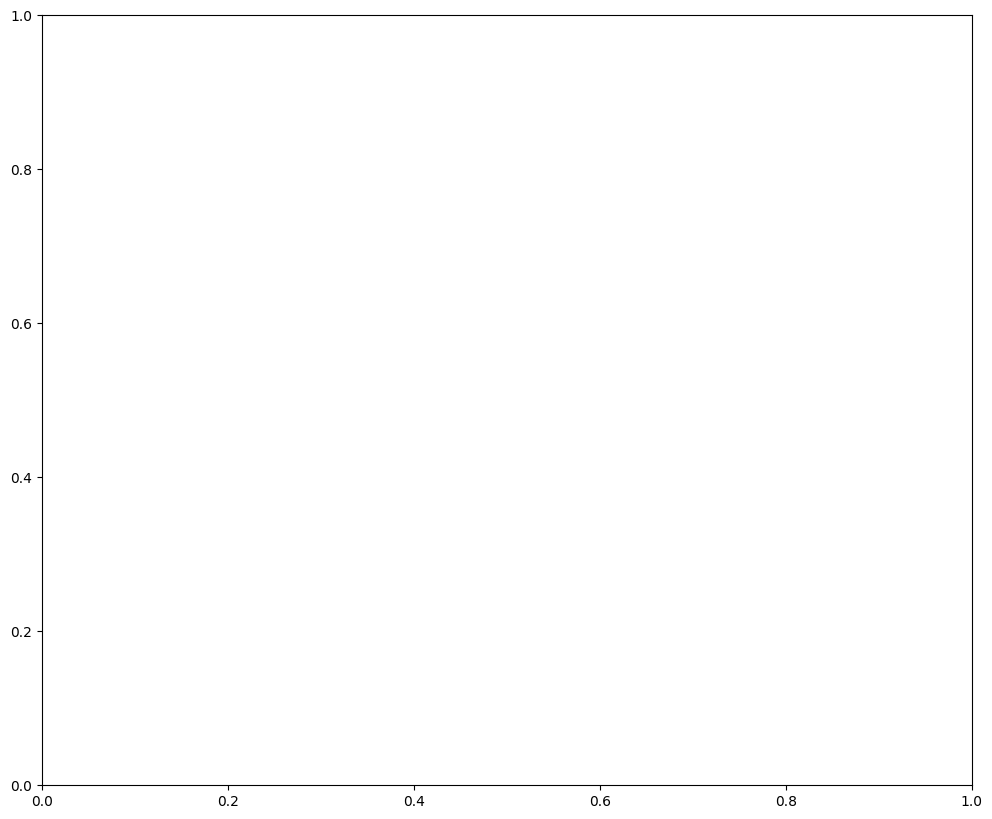

In [23]:
# COORDENADAS RELATIVAS APROXIMADAS OBTENIDAS DEL MAPA

coordenadas_estaciones = pd.DataFrame({
    "ESTACION": [
        "CCA",
        "CUT",
        "FAC",
        "MER",
        "MGH",
        "PED",
        "TLA",
        "UAX",
        "UIZ"
    ],

    "X_REL": [
        0.372,
        0.345,
        0.306,
        0.428,
        0.345,
        0.345,
        0.337,
        0.441,
        0.475
    ],

    "Y_REL": [
        0.624,
        0.189,
        0.424,
        0.499,
        0.500,
        0.617,
        0.365,
        0.647,
        0.574
    ]
})


print(
    "Coordenadas relativas aproximadas:"
)

display(
    coordenadas_estaciones
)


# VERIFICACIÓN VISUAL SOBRE EL MAPA

fig, ax = plt.subplots(
    figsize=(12, 10)
)

ax.imshow(
    img_array,
    extent=[0, 1, 1, 0]
)


for fila in coordenadas_estaciones.itertuples():

    ax.scatter(
        fila.X_REL,
        fila.Y_REL,
        s=90,
        marker="o",
        edgecolors="white",
        linewidths=1.5
    )

    ax.text(
        fila.X_REL + 0.008,
        fila.Y_REL - 0.008,
        fila.ESTACION,
        fontsize=11,
        fontweight="bold"
    )


ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    1,
    0
)

ax.set_xlabel(
    "Coordenada relativa $x$"
)

ax.set_ylabel(
    "Coordenada relativa $y$"
)

ax.set_title(
    "Verificación de las coordenadas relativas "
    "de la red candidata"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

## 6.4. Dispersión espacial relativa de las redes candidatas

Una vez verificadas visualmente las posiciones aproximadas de las estaciones,
se analizará la dispersión espacial de cada red candidata del Escenario B.

Las coordenadas disponibles son relativas:

$$
(x_s,y_s)\in[0,1]\times[0,1].
$$

Sin embargo, la imagen del mapa no es cuadrada. Por tanto, calcular directamente

$$
\sqrt{(x_i-x_j)^2+(y_i-y_j)^2}
$$

introduciría una distorsión, ya que una diferencia de $0.1$ en la dirección
horizontal no representa el mismo número de píxeles que una diferencia de $0.1$
en la dirección vertical.

Para conservar la geometría de la imagen se utilizará

$$
d_{ij}
=
\sqrt{
\left[W(x_i-x_j)\right]^2
+
\left[H(y_i-y_j)\right]^2
},
$$

donde:

- $W$ es el ancho de la imagen en píxeles;
- $H$ es la altura de la imagen en píxeles.

Posteriormente se normalizará cada distancia utilizando la diagonal del mapa:

$$
D=
\sqrt{W^2+H^2},
$$

de modo que

$$
d_{ij}^{*}
=
\frac{d_{ij}}{D}.
$$

Así,

$$
0\leq d_{ij}^{*}\leq1.
$$

Estas distancias siguen siendo **distancias relativas sobre la imagen** y no
distancias geográficas en kilómetros.

Para cada contaminante se calcularán:

- número de estaciones;
- distancia media entre pares de estaciones;
- distancia mínima;
- distancia máxima;
- par de estaciones más cercanas;
- par de estaciones más alejadas;
- extensión horizontal de la red;
- extensión vertical de la red.

La distancia mínima ayudará a identificar posibles redundancias espaciales,
mientras que la distancia máxima y la extensión de la red proporcionarán una
medida aproximada de su dispersión.

Este análisis debe interpretarse con especial cuidado para PM10 y PM2.5, ya que
sus redes candidatas contienen solamente dos estaciones.

In [ ]:
# DISPERSIÓN ESPACIAL RELATIVA DE LAS REDES CANDIDATAS

from itertools import combinations



# Dimensiones reales de la imagen utilizada

alto_mapa, ancho_mapa = img_array.shape[:2]

diagonal_mapa = np.sqrt(
    ancho_mapa**2
    + alto_mapa**2
)

print(
    f"Dimensiones del mapa: "
    f"{ancho_mapa} x {alto_mapa} píxeles"
)

print(
    f"Diagonal del mapa: "
    f"{diagonal_mapa:.1f} píxeles"
)


# Tabla auxiliar indexada por estación

coords = (
    coordenadas_estaciones
    .set_index("ESTACION")
)


# Calcular distancias por contaminante

resultados_dispersion = []
distancias_pares = []

for contaminante in CONTAMINANTES_OBJETIVO:

    estaciones = (
        redes["ESCENARIO_B"][
            contaminante
        ]
    )

    sub = coords.loc[
        estaciones
    ]

    pares = []

    for est1, est2 in combinations(
        estaciones,
        2
    ):

        x1 = sub.loc[
            est1,
            "X_REL"
        ]

        y1 = sub.loc[
            est1,
            "Y_REL"
        ]

        x2 = sub.loc[
            est2,
            "X_REL"
        ]

        y2 = sub.loc[
            est2,
            "Y_REL"
        ]

        dx_px = (
            (x1 - x2)
            * ancho_mapa
        )

        dy_px = (
            (y1 - y2)
            * alto_mapa
        )

        distancia_px = np.sqrt(
            dx_px**2
            + dy_px**2
        )

        distancia_rel = (
            distancia_px
            / diagonal_mapa
        )

        pares.append({
            "ESTACION_1":
                est1,

            "ESTACION_2":
                est2,

            "DISTANCIA_PX":
                distancia_px,

            "DISTANCIA_REL_DIAGONAL":
                distancia_rel
        })

        distancias_pares.append({
            "CONTAMINANTE":
                contaminante,

            "ESTACION_1":
                est1,

            "ESTACION_2":
                est2,

            "DISTANCIA_PX":
                distancia_px,

            "DISTANCIA_REL_DIAGONAL":
                distancia_rel
        })


    tabla_pares = pd.DataFrame(
        pares
    )


    # Identificar pares extremos

    fila_min = (
        tabla_pares.loc[
            tabla_pares[
                "DISTANCIA_REL_DIAGONAL"
            ].idxmin()
        ]
    )

    fila_max = (
        tabla_pares.loc[
            tabla_pares[
                "DISTANCIA_REL_DIAGONAL"
            ].idxmax()
        ]
    )


    resultados_dispersion.append({
        "CONTAMINANTE":
            contaminante,

        "N_ESTACIONES":
            len(estaciones),

        "DIST_MEDIA_REL":
            tabla_pares[
                "DISTANCIA_REL_DIAGONAL"
            ].mean(),

        "DIST_MIN_REL":
            fila_min[
                "DISTANCIA_REL_DIAGONAL"
            ],

        "PAR_MAS_CERCANO":
            (
                f"{fila_min['ESTACION_1']}"
                f"–"
                f"{fila_min['ESTACION_2']}"
            ),

        "DIST_MAX_REL":
            fila_max[
                "DISTANCIA_REL_DIAGONAL"
            ],

        "PAR_MAS_ALEJADO":
            (
                f"{fila_max['ESTACION_1']}"
                f"–"
                f"{fila_max['ESTACION_2']}"
            ),

        "EXTENSION_X_REL":
            (
                sub["X_REL"].max()
                - sub["X_REL"].min()
            ),

        "EXTENSION_Y_REL":
            (
                sub["Y_REL"].max()
                - sub["Y_REL"].min()
            )
    })


# TABLA RESUMEN

resumen_dispersion = pd.DataFrame(
    resultados_dispersion
)


columnas_redondear = [
    "DIST_MEDIA_REL",
    "DIST_MIN_REL",
    "DIST_MAX_REL",
    "EXTENSION_X_REL",
    "EXTENSION_Y_REL"
]

resumen_dispersion[
    columnas_redondear
] = (
    resumen_dispersion[
        columnas_redondear
    ]
    .round(3)
)


print(
    "\nDispersión espacial relativa "
    "de las redes candidatas:"
)

resumen_dispersion

## 6.5. Compromiso entre cobertura temporal y dispersión espacial en partículas

El análisis espacial mostró una diferencia importante entre las redes candidatas
de partículas.

Para PM10, las dos estaciones del Escenario B,

$$
\{CUT,MER\},
$$

presentan una separación relativa considerable.

En cambio, para PM2.5 las estaciones

$$
\{CCA,MER\}
$$

se encuentran espacialmente más próximas.

Esto plantea un problema de selección:

$$
\text{mayor estabilidad temporal}
\qquad\text{vs.}\qquad
\text{mayor representatividad espacial}.
$$

El Escenario A contiene estaciones adicionales:

$$
PM_{10}:
\{CUT,MER,TLA\},
$$

y

$$
PM_{2.5}:
\{CCA,MER,TLA,UAX\}.
$$

Aunque TLA y UAX presentan una estabilidad temporal menor que las estaciones del
Escenario B, podrían aportar información espacial complementaria.

Por ello, antes de elegir una red definitiva se compararán los escenarios A y B
utilizando simultáneamente dos dimensiones.

### Disponibilidad temporal de la red

Para cada escenario se calculará

$$
P(K_{c,t}\geq1),
$$

es decir, el porcentaje de horas en las que existe al menos una estación válida.

También se calculará

$$
P(K_{c,t}\geq2),
$$

cuando el número de estaciones lo permita.

### Dispersión espacial

Se calcularán:

- distancia media entre estaciones;
- distancia máxima entre estaciones;
- extensión horizontal;
- extensión vertical.

Las distancias continuarán expresándose de forma relativa respecto a la diagonal
de la imagen.

El objetivo no es demostrar que el Escenario A o B sea automáticamente mejor,
sino responder: **¿cuánta cobertura temporal se pierde o se gana al ampliar espacialmente la red de partículas?**

Esta comparación permitirá decidir si conviene conservar una red estrictamente
temporal o utilizar una red algo más amplia para mejorar la representatividad
espacial.

In [ ]:
# COMPARACIÓN TEMPORAL-ESPACIAL: ESCENARIO A vs ESCENARIO B PARA PARTÍCULAS

contaminantes_particulas = [
    "PM10",
    "PM25"
]

escenarios_comparar = [
    "ESCENARIO_A",
    "ESCENARIO_B"
]

resultados_tradeoff = []

# Función para construir disponibilidad horaria de una red

def construir_disponibilidad_red(
    contaminante,
    estaciones
):

    bloques = []

    for anio in ANIOS:

        ruta = Path(
            inventario_objetivo.loc[
                (
                    inventario_objetivo["ANIO"]
                    == anio
                )
                &
                (
                    inventario_objetivo[
                        "CONTAMINANTE"
                    ]
                    == contaminante
                ),
                "RUTA"
            ].iloc[0]
        )

        df = pd.read_excel(
            ruta
        )

        fecha = pd.to_datetime(
            df["FECHA"],
            errors="coerce"
        )

        hora = pd.to_numeric(
            df["HORA"],
            errors="coerce"
        )

        timestamp = (
            fecha
            + pd.to_timedelta(
                hora - 1,
                unit="h"
            )
        )

        bloque = pd.DataFrame(
            index=timestamp
        )

        for estacion in estaciones:

            if estacion in df.columns:

                serie = pd.to_numeric(
                    df[estacion],
                    errors="coerce"
                )

                bloque[
                    estacion
                ] = serie.to_numpy()

            else:

                bloque[
                    estacion
                ] = np.nan

        bloques.append(
            bloque
        )

    datos = pd.concat(
        bloques
    ).reindex(
        indice_horario_completo
    )

    validas = (
        datos.notna()
        & (datos != -99)
    )

    return validas.sum(axis=1)


# COMPARAR ESCENARIOS

for contaminante in contaminantes_particulas:

    for escenario in escenarios_comparar:

        estaciones = (
            redes[
                escenario
            ][
                contaminante
            ]
        )

        # DISPONIBILIDAD TEMPORAL

        k = construir_disponibilidad_red(
            contaminante,
            estaciones
        )

        pct_ge1 = (
            100
            * (k >= 1).mean()
        )

        pct_ge2 = (
            100
            * (k >= 2).mean()
            if len(estaciones) >= 2
            else np.nan
        )

        # DISPERSIÓN ESPACIAL

        sub = coords.loc[
            estaciones
        ]

        distancias = []

        for est1, est2 in combinations(
            estaciones,
            2
        ):

            dx_px = (
                (
                    sub.loc[est1, "X_REL"]
                    - sub.loc[est2, "X_REL"]
                )
                * ancho_mapa
            )

            dy_px = (
                (
                    sub.loc[est1, "Y_REL"]
                    - sub.loc[est2, "Y_REL"]
                )
                * alto_mapa
            )

            d_px = np.sqrt(
                dx_px**2
                + dy_px**2
            )

            distancias.append(
                d_px / diagonal_mapa
            )

        dist_media = (
            np.mean(distancias)
            if len(distancias) > 0
            else 0
        )

        dist_max = (
            np.max(distancias)
            if len(distancias) > 0
            else 0
        )

        extension_x = (
            sub["X_REL"].max()
            - sub["X_REL"].min()
        )

        extension_y = (
            sub["Y_REL"].max()
            - sub["Y_REL"].min()
        )

        # GUARDAR

        resultados_tradeoff.append({
            "CONTAMINANTE":
                contaminante,

            "ESCENARIO":
                escenario.replace(
                    "ESCENARIO_",
                    ""
                ),

            "N_ESTACIONES":
                len(estaciones),

            "ESTACIONES":
                ", ".join(estaciones),

            "PCT_HORAS_GE_1":
                pct_ge1,

            "PCT_HORAS_GE_2":
                pct_ge2,

            "DIST_MEDIA_REL":
                dist_media,

            "DIST_MAX_REL":
                dist_max,

            "EXTENSION_X_REL":
                extension_x,

            "EXTENSION_Y_REL":
                extension_y
        })


tradeoff_particulas = pd.DataFrame(
    resultados_tradeoff
)


# Redondear

columnas_pct = [
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2"
]

tradeoff_particulas[
    columnas_pct
] = (
    tradeoff_particulas[
        columnas_pct
    ]
    .round(2)
)

columnas_espaciales = [
    "DIST_MEDIA_REL",
    "DIST_MAX_REL",
    "EXTENSION_X_REL",
    "EXTENSION_Y_REL"
]

tradeoff_particulas[
    columnas_espaciales
] = (
    tradeoff_particulas[
        columnas_espaciales
    ]
    .round(3)
)


print(
    "Comparación temporal-espacial "
    "de las redes de partículas:"
)

tradeoff_particulas

Para PM10, agregar TLA a CUT–MER aumenta la disponibilidad de al menos una estación de

$$
97.20%\rightarrow99.30%,
$$

y, más importante, la disponibilidad simultánea de al menos dos estaciones de

$$
74.66%\rightarrow92.08%.
$$

Sin embargo, **la expansión espacial es pequeña**: la distancia máxima permanece en (0.195) y la extensión vertical tampoco cambia. Así que TLA aporta principalmente **redundancia temporal**, no una nueva región extrema del mapa.

En PM2.5 la situación es mucho más fuerte. Pasar de CCA–MER a CCA–MER–TLA–UAX produce

$$
97.56%\rightarrow99.82%
$$

de horas con al menos una estación, y

$$
76.66%\rightarrow97.76%
$$

con al menos dos estaciones. Además, la extensión vertical aumenta de

$$
0.125\rightarrow0.282,
$$

y la distancia máxima prácticamente se duplica:

$$
0.086\rightarrow0.186.
$$

Aquí sí parece claro que restringirnos a CCA–MER sería severo.

## 6.6. Contribución marginal de las estaciones adicionales de partículas

La comparación entre los escenarios A y B mostró que ampliar las redes de
partículas produce una mejora importante en la disponibilidad temporal.

Sin embargo, el Escenario A incorpora simultáneamente todas las estaciones que
habían sido excluidas por el criterio temporal moderado.

Esto impide conocer qué estación es responsable de cada ganancia.

Para evaluar la **contribución marginal** de las estaciones adicionales se
construirán redes intermedias.

### PM10

La red base del Escenario B es

$$
S_{PM_{10}}^{(B)}
=
\{CUT,MER\}.
$$

El Escenario A añade solamente TLA, por lo que se compararán:

$$
\{CUT,MER\}
$$

y

$$
\{CUT,MER,TLA\}.
$$

### PM2.5

La red base del Escenario B es

$$
S_{PM_{2.5}}^{(B)}
=
\{CCA,MER\}.
$$

Las estaciones adicionales del Escenario A son TLA y UAX.

Por ello se compararán cuatro configuraciones:

$$
\{CCA,MER\},
$$

$$
\{CCA,MER,TLA\},
$$

$$
\{CCA,MER,UAX\},
$$

y

$$
\{CCA,MER,TLA,UAX\}.
$$

Para cada configuración se calcularán nuevamente:

- porcentaje de horas con al menos una estación válida;
- porcentaje de horas con al menos dos estaciones válidas;
- porcentaje de horas con al menos tres estaciones válidas, cuando corresponda;
- racha máxima con cero estaciones disponibles;
- distancia media relativa entre estaciones;
- distancia máxima relativa;
- extensión horizontal;
- extensión vertical.

El objetivo es estudiar el incremento

$$
\Delta
=
\text{desempeño de la red ampliada}
-
\text{desempeño de la red base}.
$$

Una estación adicional será especialmente valiosa si produce simultáneamente:

$$
\text{ganancia temporal}
+
\text{ganancia espacial}.
$$

En cambio, si una estación aporta poca información adicional y presenta una
continuidad individual deficiente, podría no ser necesario conservarla.

Esta comparación permitirá construir una red final más parsimoniosa, evitando
tanto una selección excesivamente restrictiva como la incorporación automática
de todas las estaciones disponibles.

In [ ]:
# CONTRIBUCIÓN MARGINAL DE ESTACIONES ADICIONALES

configuraciones = {
    "PM10": {
        "BASE_B":
            ["CUT", "MER"],

        "BASE_B_MAS_TLA":
            ["CUT", "MER", "TLA"]
    },

    "PM25": {
        "BASE_B":
            ["CCA", "MER"],

        "BASE_B_MAS_TLA":
            ["CCA", "MER", "TLA"],

        "BASE_B_MAS_UAX":
            ["CCA", "MER", "UAX"],

        "BASE_B_MAS_TLA_UAX":
            ["CCA", "MER", "TLA", "UAX"]
    }
}


resultados_incrementales = []


# EVALUAR CADA CONFIGURACIÓN

for contaminante, redes_config in configuraciones.items():

    for nombre_config, estaciones in redes_config.items():

        # Disponibilidad temporal

        k = construir_disponibilidad_red(
            contaminante,
            estaciones
        )

        pct_ge1 = (
            100 * (k >= 1).mean()
        )

        pct_ge2 = (
            100 * (k >= 2).mean()
            if len(estaciones) >= 2
            else np.nan
        )

        pct_ge3 = (
            100 * (k >= 3).mean()
            if len(estaciones) >= 3
            else np.nan
        )


        # Racha máxima con cero estaciones

        hay_alguna = (
            k >= 1
        )

        rachas_cero = (
            longitudes_rachas_faltantes(
                hay_alguna
            )
        )

        max_racha_cero_h = (
            int(rachas_cero.max())
            if len(rachas_cero) > 0
            else 0
        )


        # Dispersión espacial

        sub = coords.loc[
            estaciones
        ]

        distancias = []

        for est1, est2 in combinations(
            estaciones,
            2
        ):

            dx_px = (
                (
                    sub.loc[est1, "X_REL"]
                    - sub.loc[est2, "X_REL"]
                )
                * ancho_mapa
            )

            dy_px = (
                (
                    sub.loc[est1, "Y_REL"]
                    - sub.loc[est2, "Y_REL"]
                )
                * alto_mapa
            )

            distancia_px = np.sqrt(
                dx_px**2
                + dy_px**2
            )

            distancias.append(
                distancia_px
                / diagonal_mapa
            )


        resultados_incrementales.append({
            "CONTAMINANTE":
                contaminante,

            "CONFIGURACION":
                nombre_config,

            "N_ESTACIONES":
                len(estaciones),

            "ESTACIONES":
                ", ".join(estaciones),

            "PCT_HORAS_GE_1":
                pct_ge1,

            "PCT_HORAS_GE_2":
                pct_ge2,

            "PCT_HORAS_GE_3":
                pct_ge3,

            "MAX_RACHA_CERO_DIAS":
                max_racha_cero_h / 24,

            "DIST_MEDIA_REL":
                np.mean(distancias),

            "DIST_MAX_REL":
                np.max(distancias),

            "EXTENSION_X_REL":
                (
                    sub["X_REL"].max()
                    - sub["X_REL"].min()
                ),

            "EXTENSION_Y_REL":
                (
                    sub["Y_REL"].max()
                    - sub["Y_REL"].min()
                )
        })


comparacion_incremental = pd.DataFrame(
    resultados_incrementales
)


# Redondear

columnas_porcentaje = [
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2",
    "PCT_HORAS_GE_3"
]

comparacion_incremental[
    columnas_porcentaje
] = (
    comparacion_incremental[
        columnas_porcentaje
    ]
    .round(2)
)


columnas_relativas = [
    "MAX_RACHA_CERO_DIAS",
    "DIST_MEDIA_REL",
    "DIST_MAX_REL",
    "EXTENSION_X_REL",
    "EXTENSION_Y_REL"
]

comparacion_incremental[
    columnas_relativas
] = (
    comparacion_incremental[
        columnas_relativas
    ]
    .round(3)
)


# MOSTRAR RESULTADOS

for contaminante in [
    "PM10",
    "PM25"
]:

    print(
        "\n"
        + "=" * 50
    )

    print(
        f"{contaminante}: contribución marginal "
        "de estaciones adicionales"
    )

    print(
        "=" * 50
    )

    display(
        comparacion_incremental.loc[
            comparacion_incremental[
                "CONTAMINANTE"
            ] == contaminante
        ]
        .drop(
            columns="CONTAMINANTE"
        )
        .reset_index(drop=True)
    )

La conclusión más importante es:

$$
\boxed{\text{una estación individualmente irregular puede ser muy valiosa dentro de una red}}
$$

El caso más claro es **UAX para PM2.5**. Individualmente parecía problemática por aquella racha de aproximadamente (238) días sin datos. Sin embargo, cuando la añadimos a CCA–MER, la racha máxima en la que **toda la red** queda sin información cae de

$$
29.29\text{ días}\rightarrow2.04\text{ días}.
$$

Y TLA aporta algo distinto: amplía mucho más la cobertura espacial. Cuando incorporamos **TLA y UAX simultáneamente**, conseguimos:

$$
P(K_{PM2.5,t}\geq1)=99.82%,
$$

$$
P(K_{PM2.5,t}\geq2)=97.76%,
$$

y la máxima interrupción de toda la red queda en apenas $1\text{ día}$.


Por eso, **no descartamos UAX ni TLA para PM2.5**.

Para PM10 ocurre algo parecido con TLA. Añadirla a CUT–MER aumenta:

$$
P(K_{PM10,t}\geq2):
74.66%\rightarrow92.08%,
$$

y reduce la interrupción máxima de la red de $29.13\rightarrow2.21\text{ días}$.


Aunque TLA no expande mucho más la región cubierta espacialmente, aporta una redundancia temporal enorme.

Con la evidencia que tenemos, propondríamos provisionalmente: Escenario B para ozono y Escenario A para partículas.


## 6.7. Definición de una red provisional balanceada

Los análisis anteriores mostraron que seleccionar estaciones exclusivamente por
su estabilidad individual puede producir redes demasiado restrictivas.

En particular, algunas estaciones con interrupciones importantes a nivel
individual aportan una gran cantidad de información cuando se combinan con otras
estaciones.

Por esta razón, la calidad temporal debe evaluarse también a nivel de **red**.

A partir de la evidencia obtenida se propone provisionalmente trabajar con:

$$
S_{O_3}^{*}
=
\{CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ\},
$$

$$
S_{PM_{10}}^{*}
=
\{CUT,MER,TLA\},
$$

y

$$
S_{PM_{2.5}}^{*}
=
\{CCA,MER,TLA,UAX\}.
$$

La red de $O_3$ corresponde al Escenario B, ya que presenta una elevada
continuidad temporal con nueve estaciones y una distribución espacial
relativamente amplia.

Para PM10 se reincorpora TLA porque su presencia incrementa la disponibilidad
simultánea de estaciones y reduce notablemente la duración de las
interrupciones de la red.

Para PM2.5 se reincorporan TLA y UAX porque ambas realizan contribuciones
complementarias:

- TLA aumenta principalmente la dispersión espacial de la red;
- UAX proporciona una fuerte complementariedad temporal;
- juntas reducen sustancialmente los periodos en los que la red queda sin
  información.

Esto muestra que

$$
\text{calidad individual de una estación}
\not\equiv
\text{contribución de la estación a la red}.
$$

Por tanto, la selección de estaciones para un problema de monitoreo debe
considerar conjuntamente

$$
\text{continuidad individual}
+
\text{complementariedad temporal}
+
\text{representatividad espacial}.
$$

Las redes anteriores serán denominadas **redes provisionales balanceadas**.

Todavía no se considerarán definitivas.

Antes de cerrar la selección se verificará que su disponibilidad no dependa
excesivamente de determinados meses del año, ya que para un problema de
contingencias es importante disponer de información durante diferentes
condiciones estacionales.

In [ ]:
# DISPONIBILIDAD MENSUAL DE LAS REDES PROVISIONALES BALANCEADAS

REDES_PROVISIONALES = {
    "O3": [
        "CCA",
        "CUT",
        "FAC",
        "MER",
        "MGH",
        "PED",
        "TLA",
        "UAX",
        "UIZ"
    ],

    "PM10": [
        "CUT",
        "MER",
        "TLA"
    ],

    "PM25": [
        "CCA",
        "MER",
        "TLA",
        "UAX"
    ]
}


resultados_disponibilidad_mensual_red = []


# Construir disponibilidad horaria y resumir por mes calendario

for contaminante, estaciones in REDES_PROVISIONALES.items():

    k = construir_disponibilidad_red(
        contaminante,
        estaciones
    )

    tabla = pd.DataFrame({
        "K_DISPONIBLES": k
    })

    tabla["MES"] = (
        tabla.index.month
    )

    for mes in range(1, 13):

        sub = tabla.loc[
            tabla["MES"] == mes
        ]

        n_estaciones = len(
            estaciones
        )

        resultados_disponibilidad_mensual_red.append({
            "CONTAMINANTE":
                contaminante,

            "MES":
                mes,

            "N_ESTACIONES_RED":
                n_estaciones,

            "PCT_HORAS_GE_1":
                100 * (
                    sub["K_DISPONIBLES"] >= 1
                ).mean(),

            "PCT_HORAS_GE_2":
                100 * (
                    sub["K_DISPONIBLES"] >= 2
                ).mean(),

            "PCT_HORAS_GE_3":
                (
                    100 * (
                        sub["K_DISPONIBLES"] >= 3
                    ).mean()
                    if n_estaciones >= 3
                    else np.nan
                ),

            "MEDIA_ESTACIONES_DISPONIBLES":
                sub[
                    "K_DISPONIBLES"
                ].mean()
        })


disponibilidad_mensual_red = pd.DataFrame(
    resultados_disponibilidad_mensual_red
)


# Redondear

columnas_redondear = [
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2",
    "PCT_HORAS_GE_3",
    "MEDIA_ESTACIONES_DISPONIBLES"
]

disponibilidad_mensual_red[
    columnas_redondear
] = (
    disponibilidad_mensual_red[
        columnas_redondear
    ]
    .round(2)
)


# Mostrar matrices mensuales

for variable in [
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2",
    "MEDIA_ESTACIONES_DISPONIBLES"
]:

    print(
        "\n"
        + "=" * 70
    )

    print(
        variable
    )

    print(
        "=" * 70
    )

    matriz = (
        disponibilidad_mensual_red
        .pivot(
            index="CONTAMINANTE",
            columns="MES",
            values=variable
        )
        .reindex(
            CONTAMINANTES_OBJETIVO
        )
    )

    display(matriz)

Los resultados mensuales terminan de respaldar bastante bien las redes provisionales.

Para $O_3$, la disponibilidad es extraordinariamente estable durante todo el año: incluso el peor mes conserva aproximadamente (97.97%) de las horas con al menos una estación disponible y más del (97.6%) con al menos dos.

Para PM10 sí existe una cierta estacionalidad en la redundancia. Agosto es el mes más débil:

$$
P(K_{PM10,t}\geq1)=97.30%,
$$

pero

$$
P(K_{PM10,t}\geq2)=80.13%.
$$

Aun así, la incorporación de TLA ha convertido una red bastante vulnerable en una red utilizable durante prácticamente todo el año.

Para PM2.5 el resultado es todavía mejor: el peor mes conserva $98.96\%$ de horas con alguna estación disponible y $94.10\%$ con al menos dos.

## 6.8. Selección final de estaciones para la construcción de la base de trabajo

Los diagnósticos realizados permitieron evaluar la disponibilidad de las
estaciones desde diferentes perspectivas:

$$
\text{cobertura anual},
$$

$$
\text{cobertura mensual},
$$

$$
\text{duración de los faltantes},
$$

$$
\text{complementariedad temporal},
$$

y

$$
\text{dispersión espacial relativa}.
$$

La evidencia mostró que una selección basada exclusivamente en la calidad
individual de cada estación sería demasiado restrictiva, particularmente para
PM10 y PM2.5.

Algunas estaciones con interrupciones individuales importantes proporcionan una
contribución considerable cuando se incorporan a una red, ya que sus periodos de
disponibilidad complementan los de otras estaciones.

Por esta razón, para los siguientes notebooks se adoptarán las siguientes redes
de trabajo:

$$
\boxed{
S_{O_3}
=
\{CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ\}
}
$$

$$
\boxed{
S_{PM_{10}}
=
\{CUT,MER,TLA\}
}
$$

$$
\boxed{
S_{PM_{2.5}}
=
\{CCA,MER,TLA,UAX\}
}
$$

La selección de $O_3$ corresponde a la red temporal moderada identificada
anteriormente.

En el caso de PM10 y PM2.5 se utilizan redes ampliadas porque las estaciones
adicionales producen mejoras importantes en la disponibilidad conjunta.

En particular, la selección busca equilibrar

$$
\text{calidad individual}
+
\text{redundancia temporal}
+
\text{dispersión espacial}.
$$


### Interpretación de estas redes

Estas estaciones deben interpretarse como las **redes de datos seleccionadas
para continuar el proyecto**, no como una afirmación de que todas las estaciones
deban utilizarse simultáneamente como variables de un mismo modelo.

Más adelante podrán estudiarse diferentes representaciones de la información,
por ejemplo:

- concentraciones por estación;
- máximos espaciales;
- estadísticas regionales;
- características derivadas de varias estaciones;
- estructuras espaciales;
- modelos específicos por estación.

La elección entre estas alternativas pertenece a etapas posteriores.

Asimismo, esta selección no define todavía qué constituye una contingencia.

Posteriormente deberá establecer formalmente, para cada contaminante,

$$
O_3,\qquad PM_{10},\qquad PM_{2.5},
$$

cómo se construyen las variables asociadas con las condiciones regulatorias de
contingencia y qué resolución temporal debe utilizarse.

In [ ]:
# RESUMEN FINAL DE LAS REDES SELECCIONADAS

REDES_SELECCIONADAS = {
    "O3": [
        "CCA",
        "CUT",
        "FAC",
        "MER",
        "MGH",
        "PED",
        "TLA",
        "UAX",
        "UIZ"
    ],

    "PM10": [
        "CUT",
        "MER",
        "TLA"
    ],

    "PM25": [
        "CCA",
        "MER",
        "TLA",
        "UAX"
    ]
}


resumen_final_redes = []


for contaminante, estaciones in REDES_SELECCIONADAS.items():

    # Disponibilidad horaria de la red

    k = construir_disponibilidad_red(
        contaminante,
        estaciones
    )

    n_estaciones = len(
        estaciones
    )

    pct_ge1 = (
        100 * (k >= 1).mean()
    )

    pct_ge2 = (
        100 * (k >= 2).mean()
    )

    pct_ge3 = (
        100 * (k >= 3).mean()
        if n_estaciones >= 3
        else np.nan
    )


    # Racha máxima sin ninguna estación disponible

    rachas_cero = (
        longitudes_rachas_faltantes(
            k >= 1
        )
    )

    max_racha_cero_h = (
        int(rachas_cero.max())
        if len(rachas_cero) > 0
        else 0
    )


    # Disponibilidad por mes calendario

    tabla_k = pd.DataFrame({
        "K": k
    })

    tabla_k["MES"] = (
        tabla_k.index.month
    )

    resumen_mes = (
        tabla_k
        .groupby("MES")
        .agg(
            PCT_GE1=(
                "K",
                lambda x:
                100 * (x >= 1).mean()
            ),
            PCT_GE2=(
                "K",
                lambda x:
                100 * (x >= 2).mean()
            )
        )
    )

    peor_mes_ge1 = int(
        resumen_mes[
            "PCT_GE1"
        ].idxmin()
    )

    min_pct_ge1 = (
        resumen_mes.loc[
            peor_mes_ge1,
            "PCT_GE1"
        ]
    )

    peor_mes_ge2 = int(
        resumen_mes[
            "PCT_GE2"
        ].idxmin()
    )

    min_pct_ge2 = (
        resumen_mes.loc[
            peor_mes_ge2,
            "PCT_GE2"
        ]
    )


    # Dispersión espacial relativa

    sub = coords.loc[
        estaciones
    ]

    distancias = []

    for est1, est2 in combinations(
        estaciones,
        2
    ):

        dx_px = (
            (
                sub.loc[est1, "X_REL"]
                - sub.loc[est2, "X_REL"]
            )
            * ancho_mapa
        )

        dy_px = (
            (
                sub.loc[est1, "Y_REL"]
                - sub.loc[est2, "Y_REL"]
            )
            * alto_mapa
        )

        distancia_px = np.sqrt(
            dx_px**2
            + dy_px**2
        )

        distancias.append(
            distancia_px
            / diagonal_mapa
        )


    # Guardar resumen

    resumen_final_redes.append({
        "CONTAMINANTE":
            contaminante,

        "N_ESTACIONES":
            n_estaciones,

        "ESTACIONES":
            ", ".join(estaciones),

        "PCT_HORAS_GE_1":
            pct_ge1,

        "PCT_HORAS_GE_2":
            pct_ge2,

        "PCT_HORAS_GE_3":
            pct_ge3,

        "MAX_RACHA_SIN_RED_DIAS":
            max_racha_cero_h / 24,

        "PEOR_MES_GE_1":
            peor_mes_ge1,

        "MIN_MENSUAL_GE_1":
            min_pct_ge1,

        "PEOR_MES_GE_2":
            peor_mes_ge2,

        "MIN_MENSUAL_GE_2":
            min_pct_ge2,

        "DIST_MEDIA_REL":
            np.mean(distancias),

        "DIST_MAX_REL":
            np.max(distancias),

        "EXTENSION_X_REL":
            (
                sub["X_REL"].max()
                - sub["X_REL"].min()
            ),

        "EXTENSION_Y_REL":
            (
                sub["Y_REL"].max()
                - sub["Y_REL"].min()
            )
    })


resumen_final_redes = pd.DataFrame(
    resumen_final_redes
)


# Redondear resultados

columnas_pct = [
    "PCT_HORAS_GE_1",
    "PCT_HORAS_GE_2",
    "PCT_HORAS_GE_3",
    "MIN_MENSUAL_GE_1",
    "MIN_MENSUAL_GE_2"
]

resumen_final_redes[
    columnas_pct
] = (
    resumen_final_redes[
        columnas_pct
    ]
    .round(2)
)


columnas_relativas = [
    "MAX_RACHA_SIN_RED_DIAS",
    "DIST_MEDIA_REL",
    "DIST_MAX_REL",
    "EXTENSION_X_REL",
    "EXTENSION_Y_REL"
]

resumen_final_redes[
    columnas_relativas
] = (
    resumen_final_redes[
        columnas_relativas
    ]
    .round(3)
)


print(
    "Resumen final de las redes seleccionadas:"
)

resumen_final_redes

La tabla final es consistente y ya permite cerrar el objetivo del notebook. Las redes seleccionadas tienen una disponibilidad muy alta:

$$
98.04\% \text{ para } O_3,\qquad
99.30\% \text{ para PM}_{10},\qquad
99.82\% \text{ para PM}_{2.5}
$$

con al menos una estación disponible. Además, la redundancia es especialmente buena para $O_3$ y PM2.5. Para PM10, agosto es el periodo relativamente más débil, pero incluso ahí hay alguna estación disponible durante el (97.30%) de las horas.



## 7. Conclusiones del diagnóstico y datos de salida

El objetivo de este notebook fue determinar qué series horarias de la RAMA
presentan una cobertura temporal y una distribución espacial suficientemente
adecuadas para continuar el estudio de detección temprana de contingencias
atmosféricas durante el periodo 2015–2025.

El análisis se concentró en los tres contaminantes objetivo:

$$
O_3,\qquad PM_{10},\qquad PM_{2.5}.
$$

Los demás contaminantes disponibles en RAMA no fueron utilizados para seleccionar
las estaciones objetivo y podrán evaluarse posteriormente como covariables
predictoras.



### 7.1. Integridad estructural de la base

Se localizaron correctamente los

$$
11\times3=33
$$

archivos correspondientes a los contaminantes objetivo durante 2015–2025.

No se identificaron:

- archivos faltantes;
- archivos duplicados;
- registros `FECHA`–`HORA` duplicados;
- fechas inválidas;
- valores no numéricos en las concentraciones.

La única irregularidad estructural común ocurrió en 2024, donde los tres
contaminantes presentan dos registros horarios ausentes:

$$
2024\text{-}01\text{-}17,\quad HORA=19,
$$

y

$$
2024\text{-}04\text{-}06,\quad HORA=24.
$$

Estas ausencias representan aproximadamente el $0.023\%$ de las horas del año y
se conservarán como información faltante, sin imputación en esta etapa.


### 7.2. Importancia de analizar cada contaminante por separado

La disponibilidad histórica de estaciones es claramente distinta entre
contaminantes.

Se identificaron en el periodo completo:

$$
39\text{ estaciones para }O_3,
$$

$$
31\text{ estaciones para PM}_{10},
$$

y

$$
27\text{ estaciones para PM}_{2.5}.
$$

Asimismo, el número de estaciones con al menos alguna medición válida durante
los once años fue:

$$
25\text{ para }O_3,
$$

$$
13\text{ para PM}_{10},
$$

y

$$
9\text{ para PM}_{2.5}.
$$

Estos resultados justifican utilizar redes específicas para cada contaminante,
en lugar de restringir el análisis a la intersección de estaciones comunes.


### 7.3. Cobertura individual frente a contribución a la red

El análisis mostró que una estación con menor estabilidad individual puede
seguir siendo útil cuando sus periodos de disponibilidad complementan los de
otras estaciones.

Por tanto,

$$
\text{calidad individual}
\not\equiv
\text{utilidad dentro de la red}.
$$

La selección final se realizó considerando conjuntamente:

$$
\text{continuidad individual}
+
\text{complementariedad temporal}
+
\text{dispersión espacial}.
$$

Esta consideración fue particularmente importante para PM10 y PM2.5.



### 7.4. Redes seleccionadas

Las redes que se utilizarán como punto de partida para los siguientes notebooks
son:

$$
\boxed{
S_{O_3}
=
\{CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ\}
}
$$

con $9$ estaciones,

$$
\boxed{
S_{PM_{10}}
=
\{CUT,MER,TLA\}
}
$$

con $3$ estaciones, y

$$
\boxed{
S_{PM_{2.5}}
=
\{CCA,MER,TLA,UAX\}
}
$$

con $4$ estaciones.



### 7.5. Disponibilidad de las redes seleccionadas

Considerando que una hora es utilizable cuando existe al menos una estación con
información válida, la disponibilidad global obtenida fue:

$$
P(K_{O_3,t}\geq1)=98.04\%,
$$

$$
P(K_{PM_{10},t}\geq1)=99.30\%,
$$

y

$$
P(K_{PM_{2.5},t}\geq1)=99.82\%.
$$

La disponibilidad simultánea de al menos dos estaciones fue:

$$
P(K_{O_3,t}\geq2)=97.79\%,
$$

$$
P(K_{PM_{10},t}\geq2)=92.08\%,
$$

y

$$
P(K_{PM_{2.5},t}\geq2)=97.76\%.
$$

Las interrupciones máximas en las que ninguna estación de la red proporciona
información fueron aproximadamente:

$$
0.25\text{ días para }O_3,
$$

$$
2.21\text{ días para PM}_{10},
$$

y

$$
1.00\text{ día para PM}_{2.5}.
$$

Estos resultados muestran que la complementariedad entre estaciones reduce
considerablemente los huecos temporales de las series individuales.


### 7.6. Comportamiento mensual

La disponibilidad de las redes permanece elevada durante todos los meses del
año.

El porcentaje mínimo mensual de horas con al menos una estación disponible fue:

$$
97.97\%\text{ para }O_3,
$$

$$
97.30\%\text{ para PM}_{10},
$$

y

$$
98.96\%\text{ para PM}_{2.5}.
$$

En PM10 y PM2.5, agosto fue el mes con menor disponibilidad relativa, aunque los
niveles continúan siendo elevados.



### 7.7. Consideraciones espaciales

Debido a que no se dispuso de un catálogo oficial local con coordenadas
geográficas, la distribución espacial se estudió mediante coordenadas relativas
digitalizadas sobre el mapa del sistema de monitoreo.

Estas posiciones deben interpretarse exclusivamente como una herramienta
exploratoria:

$$
(x_s,y_s)
\neq
(\text{longitud}_s,\text{latitud}_s).
$$

Por tanto, las distancias calculadas en este notebook representan únicamente
separaciones relativas dentro de la imagen y no distancias geográficas en
kilómetros.

A pesar de esta limitación, el análisis permitió comprobar que la ampliación de
las redes de partículas mejora la cobertura espacial relativa, especialmente en
PM2.5.



## 7.8. Decisiones metodológicas que se posponen

Este notebook **no define todavía qué constituye una contingencia ambiental**.

En particular, todavía no se han establecido:

- los umbrales regulatorios que definirán cada condición de interés;
- la resolución temporal específica para cada contaminante;
- los promedios móviles necesarios para partículas;
- la representación adecuada del ozono;
- las etiquetas de evento;
- los horizontes de anticipación;
- los periodos de entrenamiento y prueba;
- los predictores químicos o meteorológicos;
- los procedimientos de imputación, si fueran necesarios.

Estas decisiones deberán tratarse explícitamente en los siguientes notebooks.



## 7.9. Resultado principal del notebook

El resultado principal de esta etapa puede resumirse como

$$
\boxed{
\text{RAMA 2015--2025}
\longrightarrow
\begin{cases}
9\text{ estaciones para }O_3,\\
3\text{ estaciones para PM}_{10},\\
4\text{ estaciones para PM}_{2.5},
\end{cases}
}
$$

con una disponibilidad temporal de red superior al $98\%$ para $O_3$ y superior
al $99\%$ para las redes seleccionadas de partículas.

Estas redes constituyen la base de monitoreo que será utilizada en las siguientes
etapas del proyecto.

In [ ]:
# EXPORTACIÓN DE LOS RESULTADOS DEL NOTEBOOK 00

RUTA_RESULTADOS_00 = Path(
    "resultados_00_diagnostico_RAMA_contingencias"
)

RUTA_RESULTADOS_00.mkdir(
    parents=True,
    exist_ok=True
)


# 1. Inventario de archivos objetivo

inventario_objetivo.to_csv(
    RUTA_RESULTADOS_00
    / "inventario_archivos_objetivo.csv",
    index=False,
    encoding="utf-8-sig"
)


# 2. Auditoría estructural

auditoria_objetivo.to_csv(
    RUTA_RESULTADOS_00
    / "auditoria_estructural_archivos.csv",
    index=False,
    encoding="utf-8-sig"
)


# 3. Panel completo de cobertura anual

cobertura_panel.to_csv(
    RUTA_RESULTADOS_00
    / "cobertura_anual_estacion_contaminante.csv",
    index=False,
    encoding="utf-8-sig"
)


# 4. Resumen longitudinal

resumen_longitudinal.to_csv(
    RUTA_RESULTADOS_00
    / "resumen_longitudinal_estaciones.csv",
    index=False,
    encoding="utf-8-sig"
)


# 5. Cobertura mensual

cobertura_mensual.to_csv(
    RUTA_RESULTADOS_00
    / "cobertura_mensual_estaciones.csv",
    index=False,
    encoding="utf-8-sig"
)


# 6. Indicadores integrados de estabilidad

estabilidad_integrada.to_csv(
    RUTA_RESULTADOS_00
    / "indicadores_estabilidad_temporal.csv",
    index=False,
    encoding="utf-8-sig"
)


# 7. Sensibilidad de los criterios

sensibilidad_estaciones.to_csv(
    RUTA_RESULTADOS_00
    / "sensibilidad_seleccion_estaciones.csv",
    index=False,
    encoding="utf-8-sig"
)


# 8. Coordenadas relativas utilizadas

coordenadas_estaciones.to_csv(
    RUTA_RESULTADOS_00
    / "coordenadas_relativas_estaciones.csv",
    index=False,
    encoding="utf-8-sig"
)


# 9. Resumen final de las redes seleccionadas

resumen_final_redes.to_csv(
    RUTA_RESULTADOS_00
    / "resumen_final_redes_seleccionadas.csv",
    index=False,
    encoding="utf-8-sig"
)


# 10. Tabla simple estación-contaminante

registros_red_final = []

for contaminante, estaciones in REDES_SELECCIONADAS.items():

    for estacion in estaciones:

        registros_red_final.append({
            "CONTAMINANTE":
                contaminante,

            "ESTACION":
                estacion
        })


redes_seleccionadas_tabla = pd.DataFrame(
    registros_red_final
)

redes_seleccionadas_tabla.to_csv(
    RUTA_RESULTADOS_00
    / "redes_seleccionadas.csv",
    index=False,
    encoding="utf-8-sig"
)


# VERIFICACIÓN

archivos_exportados = sorted(
    [
        archivo.name
        for archivo in RUTA_RESULTADOS_00.iterdir()
        if archivo.is_file()
    ]
)


print(
    "Directorio de resultados:"
)

print(
    RUTA_RESULTADOS_00.resolve()
)

print(
    "\nArchivos exportados:"
)

for archivo in archivos_exportados:
    print(
        f"- {archivo}"
    )

print(
    f"\nTotal de archivos exportados: "
    f"{len(archivos_exportados)}"
)

# Cuestionario de comprensión

El objetivo de este cuestionario es verificar que se comprendan las decisiones
metodológicas realizadas durante el diagnóstico de cobertura de la base RAMA.

Las respuestas deben justificarse con argumentos y, cuando sea necesario,
utilizar los resultados obtenidos en el notebook.


## Pregunta 1. Integridad de la base

Para un año ordinario se esperan

$$
365\times24=8760
$$

registros horarios, mientras que para un año bisiesto se esperan

$$
366\times24=8784.
$$

Durante la auditoría se encontró que los archivos de $O_3$, PM10 y PM2.5 de
2024 contienen $8782$ registros.

**a)** ¿Cuántos registros faltan en cada archivo?

**b)** ¿Por qué es preferible calcular la cobertura utilizando $8784$ como
denominador y no $8782$?

**c)** ¿Qué problema produciría utilizar únicamente el número de filas
existentes en el archivo?


## Pregunta 2. Datos faltantes y observaciones válidas

En la base RAMA aparecen valores `-99`, mientras que `pandas` también puede
representar información faltante mediante `NaN`.

Explica:

**a)** ¿Qué significa `-99` en los archivos RAMA?

**b)** ¿Por qué

$$
-99\neq NaN
$$

desde el punto de vista computacional?

**c)** ¿Qué condiciones debe cumplir una observación para ser considerada
válida en este notebook?

**d)** ¿Por qué no sería correcto incluir los valores `-99` al calcular la
concentración media de un contaminante?



## Pregunta 3. Cobertura temporal

La cobertura anual de una estación $s$ para un contaminante $c$ se definió como

$$
C_{s,c,y}
=
\frac{
N_{s,c,y}^{(\mathrm{válido})}
}{
H_y
}
\times100.
$$

Supongamos que una estación presenta $7008$ observaciones válidas durante un año
ordinario.

**a)** Calcula su cobertura anual.

**b)** ¿Puede concluirse únicamente con este porcentaje que la estación tiene
buena continuidad temporal?

**c)** Explica por qué dos estaciones con la misma cobertura anual pueden tener
calidades temporales muy diferentes.


## Pregunta 4. Continuidad longitudinal

Considere las siguientes dos estaciones hipotéticas:

- Estación A: cobertura cercana al $82\%$ durante los $11$ años.
- Estación B: cobertura cercana al $97\%$ durante $8$ años y cobertura de
  $0\%$ durante los otros $3$ años.

**a)** ¿Cuál tiene mayor cobertura cuando está funcionando?

**b)** ¿Cuál presenta mayor continuidad longitudinal?

**c)** ¿Cuál sería inicialmente más conveniente para un estudio temporal
2015–2025? Justifica tu respuesta.

**d)** ¿Por qué la cobertura media o mediana no debe utilizarse como único
criterio de selección?


## Pregunta 5. Cobertura anual, mensual y rachas faltantes

Explica qué información diferente proporciona cada uno de los siguientes
indicadores:

1. cobertura anual;
2. cobertura mensual;
3. número de meses completamente sin datos;
4. racha máxima consecutiva sin observaciones válidas.

En particular, explica por qué una estación con una cobertura mediana anual alta
puede seguir siendo problemática si presenta

$$
L_{\max}=200\text{ días}
$$

sin información.



## Pregunta 6. Análisis de sensibilidad

En el notebook se utilizaron tres escenarios de selección:

- Escenario A: amplio;
- Escenario B: moderado;
- Escenario C: estricto.

Para PM2.5 se obtuvieron:

$$
4\text{ estaciones en A},
$$

$$
2\text{ estaciones en B},
$$

y

$$
1\text{ estación en C}.
$$

**a)** ¿Por qué no se eligió automáticamente el Escenario C por ser el más
estricto?

**b)** ¿Qué ventaja proporciona estudiar varios escenarios en lugar de fijar
desde el principio un único umbral?

**c)** Explica qué significa que una estación sea robusta frente a cambios en
los criterios de selección.



## Pregunta 7. Complementariedad temporal

Para una red de estaciones se definió

$$
K_{c,t}
=
\sum_{s\in S_c}
I(V_{s,c,t}=1),
$$

donde $K_{c,t}$ representa el número de estaciones con información válida en la
hora $t$.

Explica con tus propias palabras qué significan:

$$
K_{c,t}=0,
$$

$$
K_{c,t}=1,
$$

y

$$
K_{c,t}\geq2.
$$

Después explica por qué una estación con cobertura individual relativamente baja
puede ser muy útil si sus faltantes ocurren en momentos diferentes a los de las
otras estaciones.



## Pregunta 8. Calidad individual frente a calidad de la red

Para PM2.5, UAX presentó individualmente una interrupción máxima de
aproximadamente

$$
238\text{ días}.
$$

Sin embargo, al incorporarla a la red formada por CCA y MER, la racha máxima con
**cero estaciones disponibles** disminuyó aproximadamente de

$$
29.3\text{ días}
$$

a

$$
2.0\text{ días}.
$$

**a)** ¿Cómo puede explicarse aparentemente esta contradicción?

**b)** ¿Qué demuestra este resultado acerca de la selección de estaciones?

**c)** Interpreta la afirmación:

$$
\boxed{
\text{calidad individual}
\not\equiv
\text{utilidad dentro de la red}
}
$$



## Pregunta 9. Coincidencia de interrupciones e índice de Jaccard

Para comparar las horas en las que dos redes quedan completamente sin
información se utilizó

$$
J(A,B)
=
\frac{|A\cap B|}{|A\cup B|}.
$$

Se obtuvieron aproximadamente:

$$
J(O_3,PM_{10})=0.014,
$$

$$
J(O_3,PM_{2.5})=0.016,
$$

y

$$
J(PM_{10},PM_{2.5})=0.122.
$$

**a)** ¿Qué significa un índice de Jaccard cercano a cero en este contexto?

**b)** ¿Qué par de contaminantes presenta la mayor coincidencia de
interrupciones?

**c)** ¿Los resultados sugieren que las ausencias de información se deben
principalmente a interrupciones generales de toda la RAMA? Justifica.



## Pregunta 10. Selección final y compromiso temporal–espacial

Las redes seleccionadas finalmente fueron

$$
S_{O_3}
=
\{CCA,CUT,FAC,MER,MGH,PED,TLA,UAX,UIZ\},
$$

$$
S_{PM_{10}}
=
\{CUT,MER,TLA\},
$$

y

$$
S_{PM_{2.5}}
=
\{CCA,MER,TLA,UAX\}.
$$

Responde:

**a)** ¿Por qué no se exigió utilizar las mismas estaciones para los tres
contaminantes?

**b)** ¿Qué significa buscar un equilibrio entre

$$
\text{continuidad individual}
+
\text{complementariedad temporal}
+
\text{representatividad espacial}?
$$

**c)** ¿Por qué las coordenadas utilizadas en este notebook no deben
interpretarse como latitud y longitud reales?

**d)** ¿Por qué, aun después de seleccionar estas redes, todavía no podemos
afirmar que ya está definido el problema de detección de contingencias?

**e)** Menciona al menos tres decisiones metodológicas que todavía deben tomarse
antes de entrenar modelos predictivos.